## Run settings
Three flags, set in the next cell, decide what a run does. Every model is saved when it is trained, so later runs can load it instead of training again.

| Flag | `True` | `False` |
|---|---|---|
| `TrainStage1` | Train every Stage 1 model (baselines, MLP, CNN, tuning, train + validation refits) and save them to `models/combined/stage1.pkl` (about 10 min on a GPU) | Load that file; nothing is retrained. Every loaded model is checked against the validation score saved with it |
| `TrainStage2` | Train, tune and refit the seven Stage 2 models and save them to `models/combined/stage2.pkl` (about 2 h). The file is saved after step 1 and after every Bayesian study, so an interrupted run continues where it stopped when run again with `True`. The smoothed-target and EWMA-input models of **Further investigation** (and the EWMA refits) are then retrained and added to the same file | Load that file; Stage 2 is skipped if it does not exist. The smoothed-target and EWMA-input models are loaded from it too, or trained once and added to it if they are missing |
| `TestModels` | Evaluate every Stage 1 and Stage 2 model, and the selected best-balance models, on the **test set** in one pass, store the results in `models/test_predictions.pkl` and `models/test_predictions_selected.pkl`, and plot them | No testing: plot the stored results if those files exist, otherwise skip the test figures |

**Recommended flow.**
1. Train both stages (`TrainStage1 = TrainStage2 = True`) with `TestModels = False`, review the validation results and the **Further investigation** section, then set `SELECTED` (the best balance of validation error and latency). The test set is not used at all.
2. If the results are good, set both train flags to `False` (everything loads) and `TestModels = True`. The test section only forecasts with the saved models; nothing is trained or refitted at test time.

In [1]:
# Run settings (see the table above)
TrainStage1 = False   # True: train and save Stage 1 | False: load the saved Stage 1 models
TrainStage2 = False   # True: train, tune and save Stage 2 (resumes an interrupted run) | False: load them
TestModels = False   # True: test every Stage 1 and Stage 2 model (and the selected ones) and store the results | False: plot stored test results, if any

STAGE1_CKPT = 'models/combined/stage1.pkl'
STAGE2_CKPT = 'models/combined/stage2.pkl'
TEST_CACHE = 'models/test_predictions.pkl'
TEST_CACHE_SEL = 'models/test_predictions_selected.pkl'

In [ ]:
import random
import numpy as np


# Fix GPU Path issues so GPU can be used, only uncomment if needed
# import os
# import sys
# os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')

import torch

print('PyTorch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('CUDA version:', torch.version.cuda, '| cuDNN version:', torch.backends.cudnn.version())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print('Training on GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, training on CPU')

# A small matmul proves tensors actually land on the chosen device
probe = torch.randn(256, 256, device=device)
print('Test matmul ran on:', (probe @ probe).device)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

# Deterministic cuDNN kernels so GPU runs repeat exactly with the same seed
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

PyTorch 2.14.1
CUDA available: True
CUDA version: 13.4 | cuDNN version: 92800
Training on GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Test matmul ran on: cuda:0


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

FIG = {'num': None, 'sub': None}  # the number show() uses when it is called without one

def figure_number(num, several=False):
    """Number the next figure(s) drawn by a shared plot function; several=True labels them a, b, c, ..."""
    FIG.update(num=num, sub=0 if several else None)

def show(num=None, sub=None):
    """plt.show() with 'Figure <num><letter>' in front of the figure's title (defaults: figure_number())."""
    if num is None:
        num, sub = FIG['num'], FIG['sub']
        if sub is not None:
            FIG['sub'] += 1
    fig = plt.gcf()
    label = f'Figure {num}' + ('' if sub is None else 'abcdefghijklmnopqrstuvwxyz'[sub])
    title = fig.get_suptitle()
    fig.suptitle(f'{label} - {title}' if title else label, fontweight='bold')
    fig.tight_layout()  # make room for the label
    plt.show()

def hbar_pair(ax, labels, first, second, legend, colors):
    """Paired horizontal bars, first label at the top; the second bar's values are printed at its end."""
    y = np.arange(len(labels))[::-1]
    ax.barh(y + 0.2, first, 0.4, color=colors[0], label=legend[0])
    ax.barh(y - 0.2, second, 0.4, color=colors[1], label=legend[1])
    for yi, v in zip(y, second):
        ax.text(v, yi - 0.2, f' {v:.3f}', va='center', fontsize=8)
    ax.set_yticks(y, labels)
    ax.legend(loc='upper right')  # the top bars are the shortest
    ax.grid(alpha=0.3, axis='x')

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [4]:
print('Shape:', df.shape)
print('Range:', df.index.min(), '->', df.index.max())
print('Timestamps unique and evenly spaced (1 min):', df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta('1min')).all())
df.info()
df.describe().T

Shape: (2075259, 7)
Range: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Timestamps unique and evenly spaced (1 min): True
<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


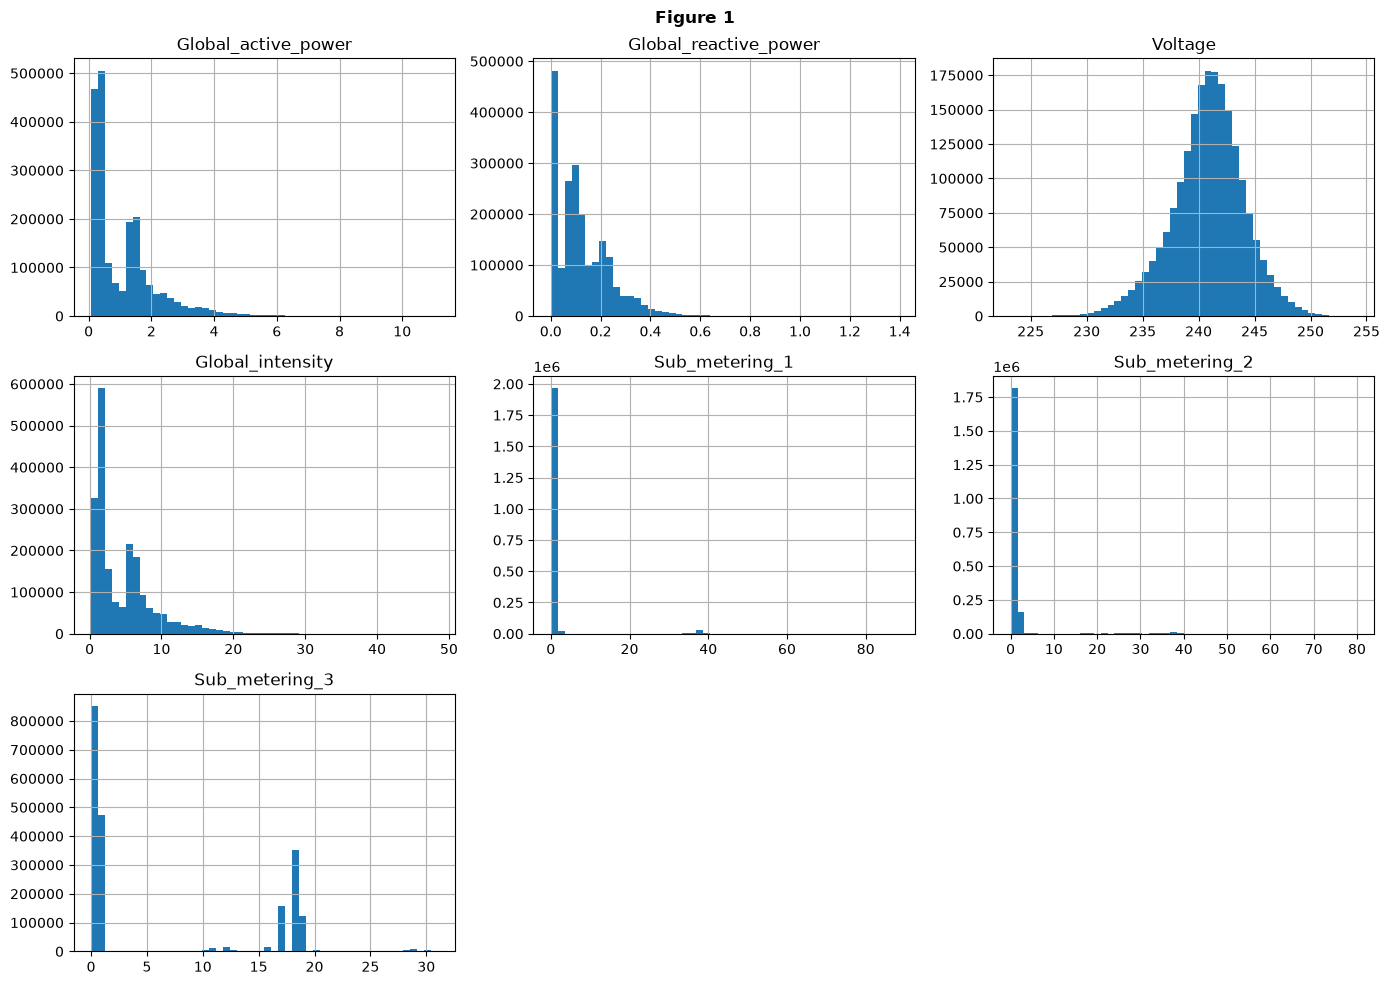

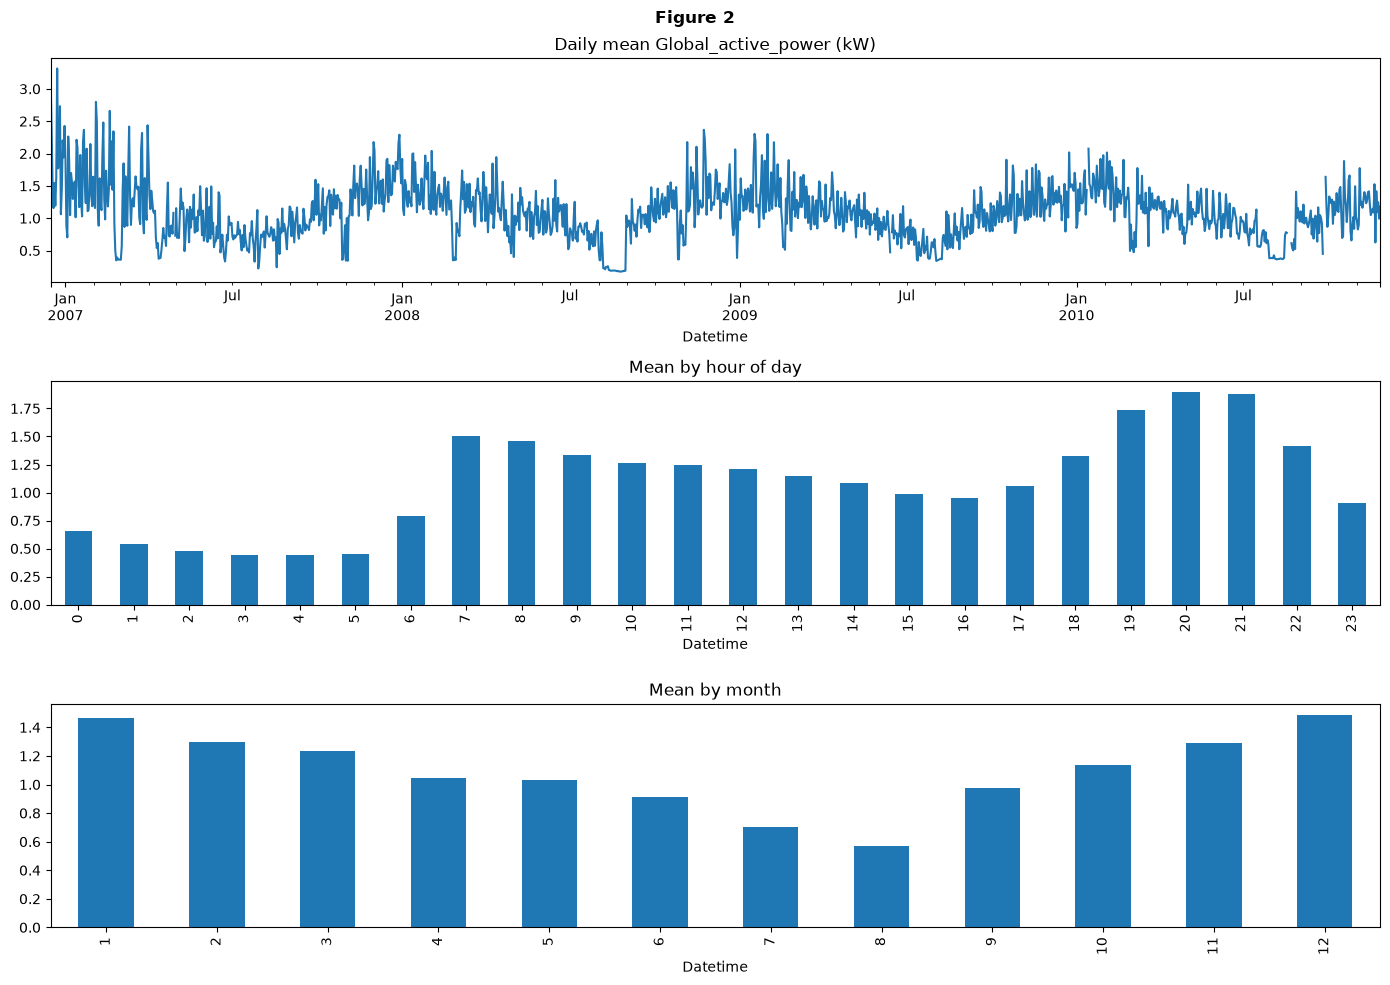

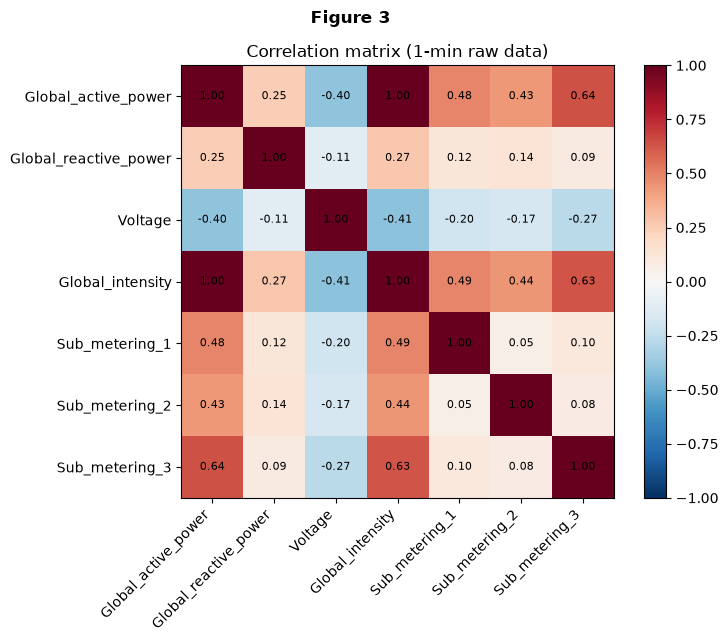

In [5]:
df.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
show(1)

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
df['Global_active_power'].resample('D').mean().plot(ax=axes[0], title='Daily mean Global_active_power (kW)')
df['Global_active_power'].groupby(df.index.hour).mean().plot(ax=axes[1], kind='bar', title='Mean by hour of day')
df['Global_active_power'].groupby(df.index.month).mean().plot(ax=axes[2], kind='bar', title='Mean by month')
plt.tight_layout()
show(2)

corr = df.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title('Correlation matrix (1-min raw data)')
plt.tight_layout()
show(3)

**What the plots show (Figures 1-3)**
* **Histograms (1-min data):** `Global_active_power` is right-skewed and bimodal: a large idle mode around 0.3 kW, an active mode around 1.5 kW, and a long tail up to about 10 kW. Voltage is roughly normal around 240 V. The sub-meters are zero most of the time; `Sub_metering_3` (water heater / AC) has a second mode near 18 Wh/min, which is the appliance switching fully on.
* **Daily mean GAP:** a clear yearly cycle, high in winter and low in summer. The August dips (near zero in Aug 2008) look like the household being away on holiday.
* **Mean by hour:** low overnight, a morning peak at 7-8 h, and the highest use in the evening (19-21 h).
* **Mean by month:** December and January are highest (about 1.5 kW), August lowest (about 0.6 kW).
* **Correlation matrix:** `Global_intensity` correlates 1.00 with GAP because current = power / voltage, so it adds no information and is dropped below. `Sub_metering_3` is the sub-meter most tied to total use (0.64). Voltage is negatively correlated (-0.40) because heavier load pulls the voltage down.

These patterns motivate hourly resampling, calendar features for hour and season, and a model that has to handle the skewed, peaky target.

In [6]:
# Global_intensity is redundant: I = P * 1000 / V, so it is almost perfectly correlated with Global_active_power
df = df.drop(columns=['Global_intensity'])
df.columns.tolist()

['Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3']

In [7]:
# How much data is missing ('?' in the raw file became NaN)
missing = df.isna()
print('Missing per column:')
print(missing.sum())

# Equal counts per column: the meter drops whole rows at once
print(f'\nRows with any missing: {missing.any(axis=1).sum()} ({missing.any(axis=1).mean():.2%})')

# Group consecutive missing minutes into gaps
row_missing = missing.any(axis=1)
gap_id = (row_missing != row_missing.shift()).cumsum()
gaps = row_missing[row_missing].groupby(gap_id[row_missing]).agg(
    start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size')
print(f'\nNumber of gaps: {len(gaps)}')

# Longest gaps span days, which shapes the imputation strategy
gaps.sort_values('minutes', ascending=False).head(10).reset_index(drop=True)

Missing per column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Rows with any missing: 25979 (1.25%)

Number of gaps: 71


,start,end,minutes
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
5,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
6,2009-08-13 05:00:00,2009-08-13 19:50:00,891
7,2007-07-15 16:49:00,2007-07-15 18:11:00,83
8,2008-12-10 10:48:00,2008-12-10 11:57:00,70
9,2007-07-15 18:21:00,2007-07-15 19:07:00,47


### Hourly resampling: within-hour std and max

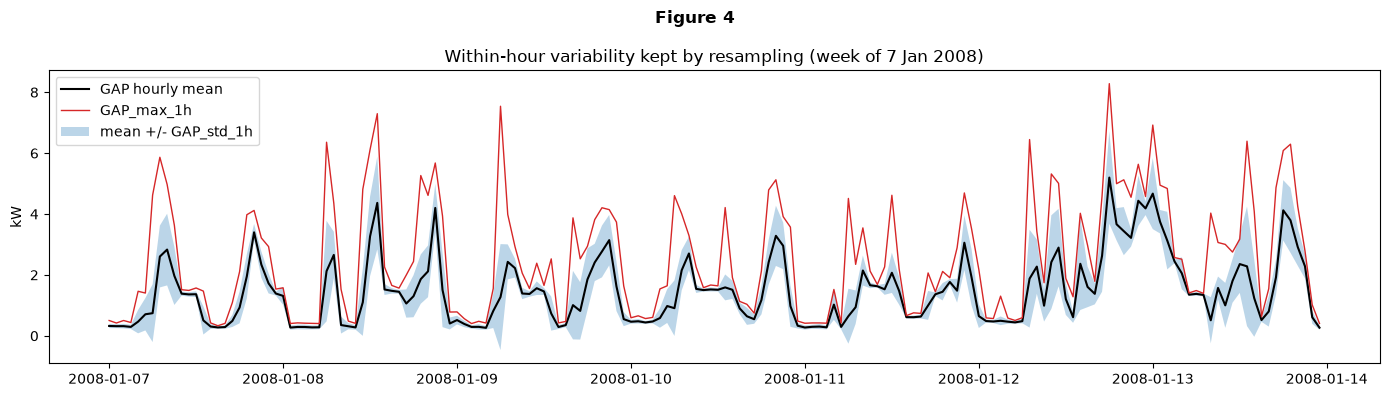

In [8]:
TARGET = 'Global_active_power'

# Hourly means are the model resolution; resampling also keeps how spiky each hour was (std, max)
hourly_raw = df.resample('h').mean()
hourly_raw[['GAP_std_1h', 'GAP_max_1h']] = df[TARGET].resample('h').agg(['std', 'max']).to_numpy()

week = hourly_raw.loc['2008-01-07':'2008-01-13']
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week[TARGET], 'k', lw=1.5, label='GAP hourly mean')
ax.plot(week.index, week['GAP_max_1h'], 'C3', lw=1, label='GAP_max_1h')
ax.fill_between(week.index, week[TARGET] - week['GAP_std_1h'], week[TARGET] + week['GAP_std_1h'],
                alpha=0.3, label='mean +/- GAP_std_1h')
ax.set(ylabel='kW', title='Within-hour variability kept by resampling (week of 7 Jan 2008)')
ax.legend()
plt.tight_layout()
show(4)

**What the plot shows (Figure 4):** the black line is the hourly mean GAP (equal to kWh used in that hour). The red line is the highest single-minute reading in each hour, and the shaded band is mean ± the within-hour standard deviation. Peak minutes often reach 6-8 kW in hours whose average is only 2-4 kW. Averaging to hourly hides these spikes, so `GAP_std_1h` and `GAP_max_1h` give the model back information about how bursty each hour was.

### Causal imputation
* Hours with fewer than 30 recorded minutes are set to missing (all columns, including std and max).
* **Short gaps (≤ 3 h):** forward fill, which carries the last observed hour forward.
* **Long gaps (up to about 5 days):** the value from the same hour one week earlier. Any remainder is forward-filled.

Every fill is **causal**: a missing hour is filled only from earlier hours, so no future value can leak into a lookback window. The `imputed` mask is kept so we can report how much of each split is filled in.

In [9]:
DAY, WEEK = 24, 168  # seasonal periods in hours

counts = df[TARGET].resample('h').count()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()

# Length of each run of missing hours
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)

hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):  # a second pass covers gaps whose previous week was also missing
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()  # only leading hours with no history can remain; drop them
imputed = imputed.loc[hourly.index]

assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly)} | imputed hours: {imputed.sum()} ({imputed.mean():.2%}), '
      f'of which short gaps: {short_gap.sum()}')
hourly.columns.tolist()

Hourly rows: 34589 | imputed hours: 432 (1.25%), of which short gaps: 7


['Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3',
 'GAP_std_1h',
 'GAP_max_1h']

### Calendar features
Household use follows the clock and the calendar, so the model gets features that say where each hour sits:
* **Hour of day** and **day of week** as sine/cosine pairs, so 23:00 sits next to 00:00 and Sunday next to Monday.
* **is_weekend**, since weekend days have a different shape than any single weekday.
* **Season** as yearly sine/cosine harmonics (1st and 2nd), a smooth version of "time of year" with no jump at 31 Dec.

All of these are known in advance for any future hour, so they cannot leak the target.

In [10]:
features = hourly.copy()
idx = features.index
dow = idx.day_of_week.to_numpy()
year_phase = 2 * np.pi * ((idx.day_of_year.to_numpy() - 1) + idx.hour.to_numpy() / 24) / 365.2425
features['hour_sin'] = np.sin(2 * np.pi * idx.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * idx.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * dow / 7)
features['dow_cos'] = np.cos(2 * np.pi * dow / 7)
features['is_weekend'] = (dow >= 5).astype(float)
for harmonic in (1, 2):
    features[f'year_sin_{harmonic}'] = np.sin(harmonic * year_phase)
    features[f'year_cos_{harmonic}'] = np.cos(harmonic * year_phase)
CALENDAR = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend',
            'year_sin_1', 'year_cos_1', 'year_sin_2', 'year_cos_2']
features[CALENDAR].head()

,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,year_sin_1,year_cos_1,year_sin_2,year_cos_2
Datetime,,,,,,,,,
2006-12-16 17:00:00,-0.965926,-2.588190e-01,-0.974928,-0.222521,1.0,-0.264062,0.964506,-0.509378,0.860543
2006-12-16 18:00:00,-1.000000,-1.836970e-16,-0.974928,-0.222521,1.0,-0.263370,0.964695,-0.508144,0.861272
2006-12-16 19:00:00,-0.965926,2.588190e-01,-0.974928,-0.222521,1.0,-0.262679,0.964883,-0.506908,0.862000
2006-12-16 20:00:00,-0.866025,5.000000e-01,-0.974928,-0.222521,1.0,-0.261987,0.965071,-0.505672,0.862726
2006-12-16 21:00:00,-0.707107,7.071068e-01,-0.974928,-0.222521,1.0,-0.261295,0.965259,-0.504435,0.863450


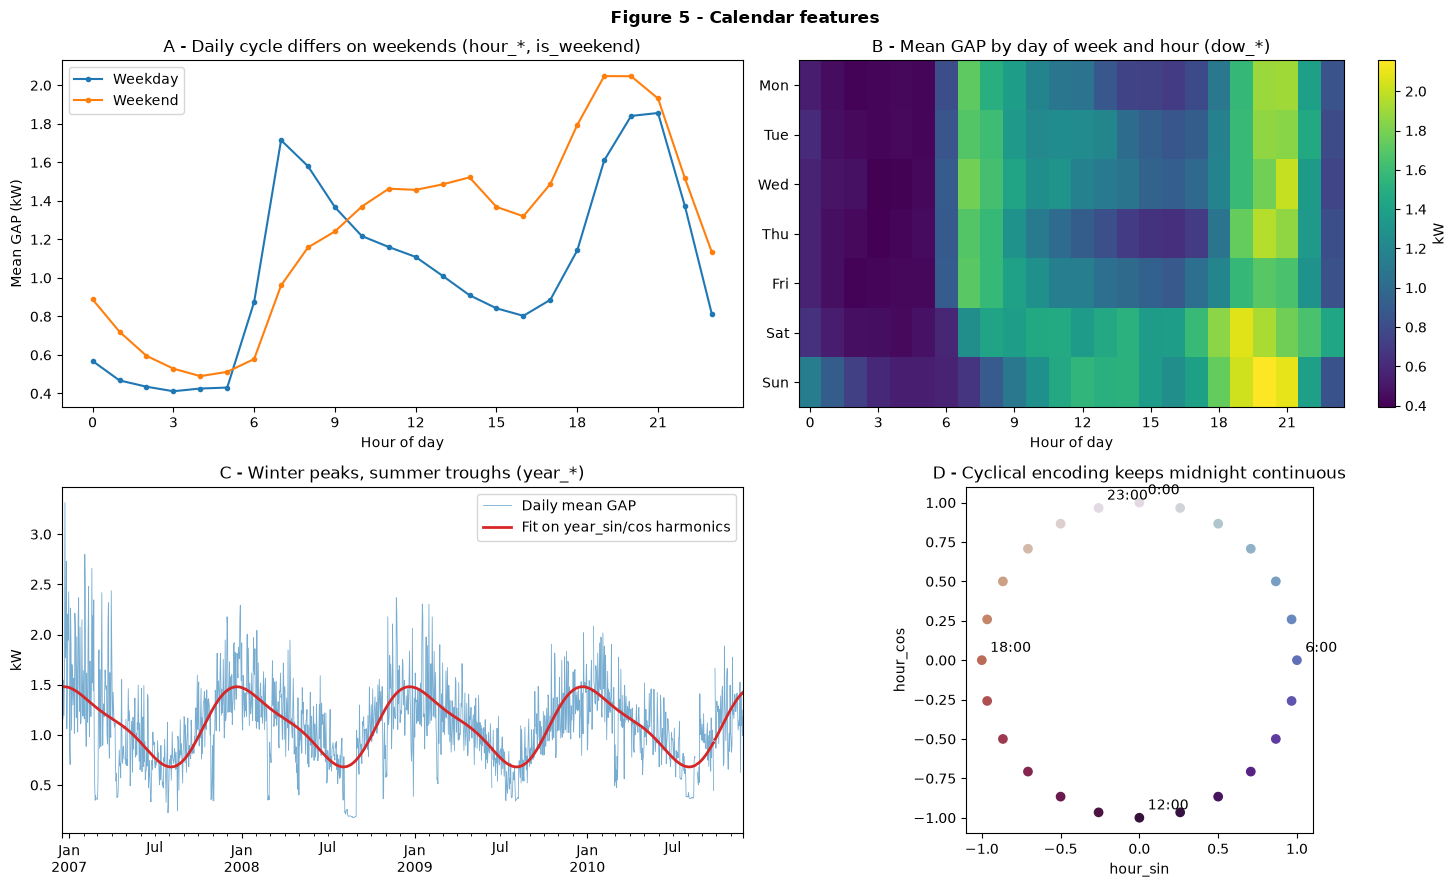

hour of day       0.235
day of week       0.011
weekend flag      0.010
month (season)    0.090
Name: share of GAP variance explained, dtype: float64

In [11]:
# Measured hours only, so imputed values don't shape the patterns
obs = features[~imputed]
gap_obs = obs[TARGET]
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) Hour of day: strong daily cycle, and weekends shift it
for weekend, label in ((0, 'Weekday'), (1, 'Weekend')):
    sel = obs['is_weekend'] == weekend
    gap_obs[sel].groupby(obs.index.hour[sel]).mean().plot(ax=axes[0, 0], marker='.', label=label)
axes[0, 0].set(xlabel='Hour of day', ylabel='Mean GAP (kW)', xticks=range(0, 24, 3),
               title='A - Daily cycle differs on weekends (hour_*, is_weekend)')
axes[0, 0].legend()

# (b) Hour x day of week: which hours are busy depends on the day
grid = gap_obs.groupby([obs.index.day_of_week, obs.index.hour]).mean().unstack()
im = axes[0, 1].imshow(grid, aspect='auto', cmap='viridis')
axes[0, 1].set_yticks(range(7), days)
axes[0, 1].set(xlabel='Hour of day', xticks=range(0, 24, 3), title='B - Mean GAP by day of week and hour (dow_*)')
fig.colorbar(im, ax=axes[0, 1], label='kW')

# (c) Season: daily mean vs a fit on the yearly harmonics alone (illustration only, fit on all measured hours)
basis = np.column_stack([np.ones(len(obs))] + [obs[c] for c in CALENDAR[5:]])
coef = np.linalg.lstsq(basis, gap_obs.to_numpy(), rcond=None)[0]
season_fit = pd.Series(basis @ coef, index=obs.index)
gap_obs.resample('D').mean().plot(ax=axes[1, 0], lw=0.6, alpha=0.6, label='Daily mean GAP')
season_fit.resample('D').mean().plot(ax=axes[1, 0], color='C3', lw=2, label='Fit on year_sin/cos harmonics')
axes[1, 0].set(ylabel='kW', xlabel='', title='C - Winter peaks, summer troughs (year_*)')
axes[1, 0].legend()

# (d) Why sin/cos: 23:00 and 00:00 end up next to each other, unlike the raw hour number
hours = np.arange(24)
axes[1, 1].scatter(np.sin(2 * np.pi * hours / 24), np.cos(2 * np.pi * hours / 24), c=hours, cmap='twilight')
for h in (0, 6, 12, 18, 23):
    axes[1, 1].annotate(f'{h}:00', (np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)),
                        textcoords='offset points', xytext=(6, 6))
axes[1, 1].set(xlabel='hour_sin', ylabel='hour_cos', aspect='equal',
               title='D - Cyclical encoding keeps midnight continuous')

fig.suptitle('Calendar features')
plt.tight_layout()
show(5)

# Share of hourly GAP variance each calendar grouping explains on its own
groups = {'hour of day': obs.index.hour, 'day of week': obs.index.day_of_week,
          'weekend flag': obs['is_weekend'], 'month (season)': obs.index.month}
pd.Series({name: gap_obs.groupby(g).transform('mean').var() / gap_obs.var() for name, g in groups.items()},
          name='share of GAP variance explained').round(3)

**What the plots show (Figure 5)**
* **A:** weekdays have a sharp 7 h morning peak and a midday dip (occupants out). Weekends have no early spike, higher daytime use, and a taller evening peak. The hour features alone can't capture this, so `is_weekend` is needed with them.
* **B:** the hour × day heatmap shows the same thing across all seven days: Monday to Friday look alike, while Saturday and Sunday stand out across the whole day.
* **C:** a fit that uses only the yearly sine/cosine harmonics follows the winter peaks and summer troughs of the daily mean, so these features carry the seasonal level.
* **D:** with sine/cosine encoding, hours sit on a circle, so 23:00 is next to 00:00. A raw hour number would place them 23 units apart.

The table gives the share of hourly GAP variance each grouping explains on its own: hour of day is largest (about 23%), then season (about 9%). Day of week and the weekend flag are about 1% each because they mostly change the *shape* of the day rather than its average, which is the interaction visible in panels A and B.

### Chronological split (60 / 20 / 20)
* The split is by time and never shuffled, so the model is always evaluated on hours that come after everything it trained on.
* Two window setups are tested:
  * **168 h → 24 h**: one week of inputs to forecast the next day, as in Stage 1.
  * **24 h → 1 h**: one day of inputs to forecast the next hour.
* A window's lookback may reach back into the previous split (that is past data), but its **target hours always stay inside their own split**.
* Train covers three winters, while test (Feb to Nov 2010) is mostly the low-load months, so absolute errors are only compared within the same split.

In [12]:
WINDOWS = {'168h_to_24h': {'lookback': 168, 'horizon': 24},
           '24h_to_1h': {'lookback': 24, 'horizon': 1}}

n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}

def window_count(a, b, lookback, horizon):
    """Forecast origins t whose lookback fits in the data and whose targets t..t+horizon-1 stay in [a, b)."""
    return max(0, b - horizon + 1 - max(a, lookback))

pd.DataFrame([{'split': s, 'start': features.index[a], 'end': features.index[b - 1], 'hours': b - a,
               'imputed %': round(imputed.iloc[a:b].mean() * 100, 2),
               **{f'windows {name}': window_count(a, b, **w) for name, w in WINDOWS.items()}}
              for s, (a, b) in splits.items()]).set_index('split')

,start,end,hours,imputed %,windows 168h_to_24h,windows 24h_to_1h
split,,,,,,
train,2006-12-16 17:00:00,2009-04-29 09:00:00,20753,0.33,20562,20729
val,2009-04-29 10:00:00,2010-02-11 15:00:00,6918,1.76,6895,6918
test,2010-02-11 16:00:00,2010-11-26 21:00:00,6918,3.50,6895,6918


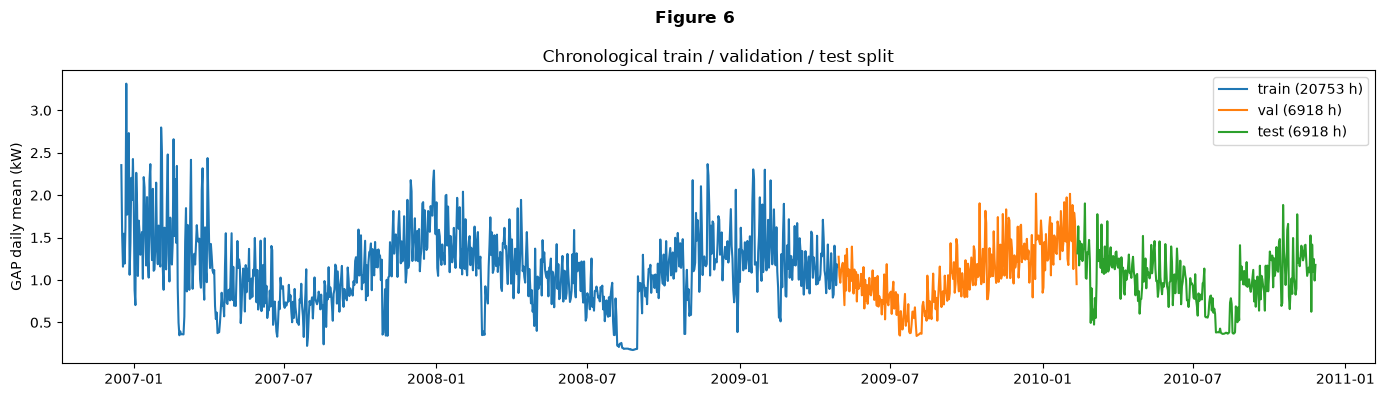

In [13]:
fig, ax = plt.subplots(figsize=(14, 4))
daily = features[TARGET].resample('D').mean()
for s, (a, b) in splits.items():
    part = daily.loc[features.index[a]:features.index[b - 1]]
    ax.plot(part.index, part, label=f'{s} ({b - a} h)')
ax.set(ylabel='GAP daily mean (kW)', title='Chronological train / validation / test split')
ax.legend()
show(6)

**What the plot shows (Figure 6):** the three splits follow each other in time with no overlap. Train covers three winters (2006-07 to 2008-09). Validation runs from spring 2009 through the 2009-10 winter. Test (Feb to Nov 2010) is mostly spring to autumn, so its average load is lower. That is why errors are only compared between models on the same split, never across splits.

### Normalization (fit on train only)
Each column is standardized as `(x - mean) / std`, with the mean and std computed on the **training rows only**. The same train statistics are applied to validation (and later test), so no information from those periods leaks into training. `to_kw` undoes the scaling on GAP predictions so errors are reported in kW.

In [14]:
train_rows = features.iloc[:train_end]
mu = train_rows.mean()
sd = train_rows.std(ddof=0).replace(0, 1)  # guard against a constant column
scaled = (features - mu) / sd

def to_kw(y):
    """Undo the scaling on GAP values (model outputs or targets)."""
    return y * sd[TARGET] + mu[TARGET]

# Check: train should be ~0 mean / 1 std; val and test drift because seasons and usage change over time
check = pd.concat({s: scaled.iloc[a:b].agg(['mean', 'std']).T for s, (a, b) in splits.items()}, axis=1)
check.round(2)

train        val        test      
                       mean  std  mean   std  mean   std
Global_active_power     0.0  1.0 -0.08  0.87 -0.14  0.77
Global_reactive_power  -0.0  1.0  0.38  1.11  0.22  0.99
Voltage                -0.0  1.0  0.46  0.87  0.28  0.77
Sub_metering_1         -0.0  1.0 -0.05  0.88 -0.07  0.84
Sub_metering_2         -0.0  1.0 -0.07  0.75 -0.08  0.75
Sub_metering_3         -0.0  1.0  0.13  1.01  0.09  0.99
GAP_std_1h              0.0  1.0 -0.03  0.86 -0.09  0.78
GAP_max_1h              0.0  1.0 -0.02  0.84 -0.11  0.74
hour_sin                0.0  1.0 -0.00  1.00 -0.00  1.00
hour_cos               -0.0  1.0 -0.00  1.00 -0.00  1.00
dow_sin                 0.0  1.0  0.00  1.00 -0.00  1.00
dow_cos                 0.0  1.0 -0.01  1.00 -0.01  1.00
is_weekend              0.0  1.0 -0.00  1.00 -0.00  1.00
year_sin_1              0.0  1.0 -0.48  0.84 -0.15  1.10
year_cos_1              0.0  1.0 -0.18  1.10 -0.47  0.84
year_sin_2              0.0  1.0 -0.18  1.03 -0.10  1.04
year_cos_2             -0.0  1.0  0.26  0.93 -0.26  0.92

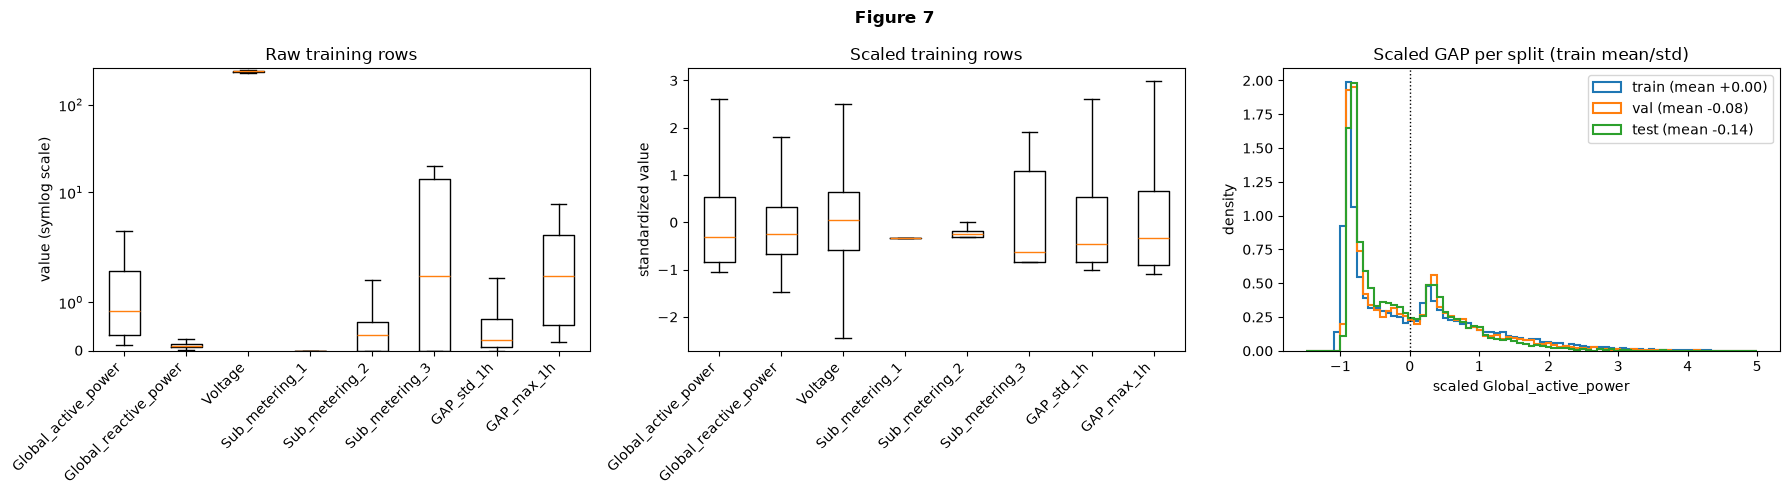

In [15]:
measured_cols = [c for c in features.columns if c not in CALENDAR]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a, b) Before scaling the inputs live on very different ranges (Voltage ~240, GAP ~1); after, they are comparable
for ax, frame, title in ((axes[0], features, 'Raw training rows'), (axes[1], scaled, 'Scaled training rows')):
    ax.boxplot([frame[c].iloc[:train_end] for c in measured_cols], showfliers=False)
    ax.set_xticks(range(1, len(measured_cols) + 1), measured_cols, rotation=45, ha='right')
    ax.set_title(title)
axes[0].set(yscale='symlog', ylim=(0, None), ylabel='value (symlog scale)')
axes[1].set(ylabel='standardized value')

# (c) Train stats applied to every split: train is centred at 0, val and test sit slightly lower
bins = np.linspace(-1.5, 5, 80)
for s, (a, b) in splits.items():
    axes[2].hist(scaled[TARGET].iloc[a:b], bins=bins, density=True, histtype='step', lw=1.5,
                 label=f'{s} (mean {scaled[TARGET].iloc[a:b].mean():+.2f})')
axes[2].axvline(0, color='k', ls=':', lw=1)
axes[2].set(xlabel=f'scaled {TARGET}', ylabel='density', title='Scaled GAP per split (train mean/std)')
axes[2].legend()

plt.tight_layout()
show(7)

**What the plots show (Figure 7)**
* **Raw training rows:** the inputs sit on very different scales: Voltage around 240, GAP around 1, reactive power around 0.1 (log-style axis so they all fit). Unscaled, the large-valued columns would dominate the gradients.
* **Scaled training rows:** after standardizing with the training mean and std, every column is centred near 0 with comparable spread. `Sub_metering_1` looks flat because the kitchen meter reads zero in most hours, so its quartiles collapse.
* **Scaled GAP per split:** all three splits keep the same shape (an idle peak near -0.9 and a long tail of busy hours). Validation and test sit slightly left of 0 (means -0.08 and -0.14) because later periods use a little less power. That shift is expected when scaling with training statistics and is not leakage.

## Non-neural baselines
Every baseline is run for both window setups and scored on **exactly the same validation windows**: every hourly forecast origin, the same target hours, and only **measured** target hours (imputed hours are excluded because long gaps were filled with last week's values, which the weekly baselines would "forecast" perfectly). Errors are in kW. For the 168 h → 24 h setup, MAE on **midnight origins** (one forecast per day) is reported as well.

* **Seasonal naive (week):** each target hour repeats the same hour one week earlier.
* **Weekly profile:** each target hour gets the training-set average for that hour of the week (168 values). It shows how much the calendar alone explains.
* **Seasonal weekly profile:** the same, but averaged separately for each season (Dec-Feb, Mar-May, Jun-Aug, Sep-Nov), so the calendar baseline also follows the yearly level. A season/hour cell with no training data falls back to the plain weekly profile.
* **Ridge regression** on the flattened, scaled lookback window (all 17 columns). Alpha is chosen on validation from 16 log-spaced values between 1 and 1e5.
* **Gradient boosting:** XGBoost on the CPU, one multi-output model with separate trees per forecast hour. For the 168 h lookback it uses a compact summary of the window (last 24 h of GAP, the same hours one week before the targets, two means, and the latest value of every input); for the 24 h lookback it uses the whole window. Learning rate, leaf count and number of boosting rounds are chosen on validation.
* **Holt-Winters:** exponential smoothing with a damped additive trend and an additive **weekly (168-hour)** season, so weekdays and weekends get their own daily shape, fitted on the training series. It is univariate (GAP only) and carries its state through all past data, so it is not limited to the lookback window.

**Causality.** A forecast for hours `t … t+H-1` only ever uses data from hours before `t`:
* Model inputs are the lookback rows `t-L … t-1`; scaling statistics, the weekly profile and the Holt-Winters parameters come from training rows only.
* Seasonal naive reads hour `t+h-168`, which is before `t` for every horizon used here (H ≤ 24).
* Holt-Winters forecasts from its state after hour `t-1`.
* Gradient boosting does **not** use early stopping on a *random* holdout of training windows (later windows would steer training on earlier ones). Instead each configuration is fitted once with many rounds and scored on validation every 25 rounds (`iteration_range`), so the number of rounds is tuned on validation. It is trained on absolute error, the same metric it is scored on.

These rules are checked with `assert`s below. Windows start one week into the data so every model has the history it needs; this drops 144 early training windows from the 24 h → 1 h setup compared with the split table. The test set is not used here.

In [16]:
# Forecast windows and the error metric shared by every model
import itertools
import pickle
import time
from types import SimpleNamespace

import xgboost as xgb  # CPU: boosting rounds are sequential and this data is too small for the GPU to pay off
from sklearn.linear_model import Ridge
from torch import nn

X_all = scaled.to_numpy(np.float32)
gap = features[TARGET].to_numpy()
TARGET_IDX = features.columns.get_loc(TARGET)
measured_all = ~imputed.to_numpy()
how = (features.index.day_of_week * 24 + features.index.hour).to_numpy()  # hour of the week, 0-167
is_midnight = features.index.hour.to_numpy() == 0
PREDICT_BATCH = 1024  # windows per forward pass when forecasting (memory only; results do not depend on it)

def make_windows(a, b, lookback, horizon):
    """Origins t (first target hour) whose targets t..t+horizon-1 lie in [a, b); inputs are rows t-lookback..t-1."""
    t = np.arange(max(a, lookback, WEEK), b - horizon + 1)
    rows = t[:, None] + np.arange(horizon)  # row index of every target hour
    return {'t': t, 'rows': rows, 'X': np.stack([X_all[i - lookback:i] for i in t]),
            'y': X_all[rows, TARGET_IDX], 'y_kw': gap[rows], 'measured': measured_all[rows]}

def check_windows(d, split_range, lookback):
    """Causality checks: inputs end right before the first target hour, and targets stay inside split_range."""
    assert np.array_equal(d['X'][:, -1], X_all[d['t'] - 1]) and np.array_equal(d['X'][:, 0], X_all[d['t'] - lookback])
    assert d['rows'].min() >= split_range[0] and d['rows'].max() < split_range[1]
    assert (d['rows'] - WEEK < d['t'][:, None]).all()  # seasonal naive only looks back

data = {setup: {s: make_windows(*splits[s], **w) for s in ('train', 'val')} for setup, w in WINDOWS.items()}
for setup, w in WINDOWS.items():
    for s, d in data[setup].items():
        check_windows(d, splits[s], w['lookback'])

def evaluate(d, pred):
    """MAE / RMSE in kW on measured target hours; midnight-origin MAE as well for multi-hour horizons."""
    err = pred - d['y_kw']
    scores = {'MAE': np.abs(err[d['measured']]).mean(), 'RMSE': np.sqrt((err[d['measured']] ** 2).mean())}
    if err.shape[1] > 1:
        scores['MAE (midnight origins)'] = np.abs(err[d['measured'] & is_midnight[d['t']][:, None]]).mean()
    return scores

ModuleNotFoundError: No module named 'xgboost'

In [ ]:
# Forecasting and checkpoint helpers, the per-model registries, and the Stage 1 checkpoint when loading
def flat(X):
    return X.reshape(len(X), -1)

def gb_features(X, horizon):
    """Gradient-boosting inputs: a compact summary of a 168 h window, or the whole (small) 24 h window."""
    y = X[:, :, TARGET_IDX]
    if X.shape[1] >= WEEK:  # the window starts exactly one week before the first target hour
        return np.hstack([y[:, -DAY:], y[:, :horizon], y[:, -DAY:].mean(1, keepdims=True),
                          y.mean(1, keepdims=True), X[:, -1]])
    return flat(X)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def predict(model, X):
    """Network outputs (scaled GAP) for windows X."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(device)).cpu() for xb in torch.from_numpy(X).split(PREDICT_BATCH)]).numpy()

def forecast(model, d):
    """Forecasts in kW for windows d from a fitted Ridge, XGBoost booster or network."""
    if isinstance(model, Ridge):
        out = model.predict(flat(d['X']))
    elif isinstance(model, xgb.Booster):
        out = model.predict(xgb.DMatrix(gb_features(d['X'], d['y_kw'].shape[1])))
    else:
        out = predict(model, d['X'])
    return to_kw(out.reshape(d['y_kw'].shape))

def best_trial(trials, setup):
    """The search row with the lowest validation MAE for one setup (the first of any ties)."""
    return min((r for r in trials if r['setup'] == setup), key=lambda r: r['val MAE'])

def save_checkpoint(path, payload):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(payload, f)
    print(f'Saved {path}')

def load_checkpoint(path, flag_name):
    assert os.path.exists(path), f'{path} not found - set {flag_name} = True to train these models'
    with open(path, 'rb') as f:
        return pickle.load(f)

def update_checkpoint(path, flag_name, **entries):
    """Add or replace entries of a saved checkpoint, keeping everything else in it."""
    checkpoint = load_checkpoint(path, flag_name)
    checkpoint.update(entries)
    save_checkpoint(path, checkpoint)

val_pred = {setup: {} for setup in WINDOWS}    # setup -> model -> validation forecasts (kW)
train_secs = {setup: {} for setup in WINDOWS}  # setup -> model -> training time of the selected configuration (s)
fitted = {setup: {} for setup in WINDOWS}      # setup -> 'Ridge' / 'Gradient boosting' -> fitted model

def val_mae_of(setup, name):
    return evaluate(data[setup]['val'], val_pred[setup][name])['MAE']

stage1_ckpt = None if TrainStage1 else load_checkpoint(STAGE1_CKPT, 'TrainStage1')
if stage1_ckpt:
    train_secs, fitted = stage1_ckpt['train_secs'], stage1_ckpt['fitted']

for setup, d in data.items():
    print(f"{setup}: train windows {len(d['train']['t'])}, val windows {len(d['val']['t'])}, input shape {d['train']['X'].shape[1:]}")

168h_to_24h: train windows 20562, val windows 6895, input shape (168, 17)
24h_to_1h: train windows 20585, val windows 6918, input shape (24, 17)


c:\Users\jonat\.conda\envs\DeepLearning\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Calendar baselines, from measured training hours only
train_obs = measured_all[:train_end]
weekly_profile = pd.Series(gap[:train_end][train_obs]).groupby(how[:train_end][train_obs]).mean().to_numpy()

# Seasonal weekly profile: one weekly profile per season (0 = Dec-Feb ... 3 = Sep-Nov)
season_of = (features.index.month.to_numpy() % 12) // 3
seasonal_profile = (pd.Series(gap[:train_end][train_obs])
                    .groupby([season_of[:train_end][train_obs], how[:train_end][train_obs]]).mean()
                    .reindex(pd.MultiIndex.from_product([range(4), range(WEEK)])).to_numpy().reshape(4, WEEK))
seasonal_profile = np.where(np.isnan(seasonal_profile), weekly_profile, seasonal_profile)  # season missing from training

In [ ]:
# Ridge: alpha chosen on validation MAE
RIDGE_ALPHAS = np.logspace(0, 5, 16)

if TrainStage1:
    ridge_trials = []
    n_trials = len(WINDOWS) * len(RIDGE_ALPHAS)
    for setup in WINDOWS:
        tr, va = data[setup]['train'], data[setup]['val']
        best = None
        for alpha in RIDGE_ALPHAS:
            start = time.perf_counter()
            model = Ridge(alpha=alpha).fit(flat(tr['X']), tr['y'])
            secs = time.perf_counter() - start
            mae = evaluate(va, forecast(model, va))['MAE']
            ridge_trials.append({'setup': setup, 'alpha': alpha, 'val MAE': mae, 'train time (s)': secs})
            print(f'[{len(ridge_trials)}/{n_trials}] Ridge {setup} alpha={alpha:g}: val MAE {mae:.4f} ({secs:.1f} s)', flush=True)
            if best is None or mae < best[0]:
                best = (mae, model, secs)
        _, fitted[setup]['Ridge'], train_secs[setup]['Ridge'] = best
else:
    ridge_trials = stage1_ckpt['ridge_trials']
    print(f'Ridge: loaded from {STAGE1_CKPT}')

for setup in WINDOWS:
    val_pred[setup]['Ridge'] = forecast(fitted[setup]['Ridge'], data[setup]['val'])
pd.DataFrame(ridge_trials).pivot(index='alpha', columns='setup', values='val MAE').round(4)

Ridge: loaded from models/combined/stage1.pkl


setup,168h_to_24h,24h_to_1h
alpha,,
1.000000,0.4562,0.3709
2.154435,0.4563,0.3709
4.641589,0.4563,0.3709
10.000000,0.4562,0.3708
21.544347,0.4559,0.3707
46.415888,0.4553,0.3705
100.000000,0.4542,0.3704
215.443469,0.4525,0.3705
464.158883,0.4502,0.3710


In [ ]:
# Gradient boosting: XGBoost, one multi-output model with separate trees per forecast hour, trained on absolute error
# (the scoring metric). No early stopping on a random (non-chronological) holdout: each configuration is fitted once
# with MAX_ROUNDS rounds and the round count is chosen on validation via iteration_range.
GB_GRID = list(itertools.product((0.05, 0.1), (15, 31, 63), (0.0, 1.0)))  # learning rate, leaves, L2
MAX_ROUNDS, EVAL_EVERY = 600, 25

def make_xgb(learning_rate, leaves, l2, rounds):
    """Leaf-wise (LightGBM-style) multi-output XGBoost on absolute error."""
    return xgb.XGBRegressor(objective='reg:absoluteerror', tree_method='hist', device='cpu',
                            learning_rate=learning_rate, grow_policy='lossguide', max_leaves=leaves, max_depth=0,
                            reg_lambda=l2, n_estimators=rounds, random_state=SEED)

if TrainStage1:
    gb_trials = []
    n_trials = len(WINDOWS) * len(GB_GRID)
    for setup, w in WINDOWS.items():
        tr, va = data[setup]['train'], data[setup]['val']
        G_train, dval = gb_features(tr['X'], w['horizon']), xgb.DMatrix(gb_features(va['X'], w['horizon']))
        best = None
        for lr, leaves, l2 in GB_GRID:
            start = time.perf_counter()
            booster = make_xgb(lr, leaves, l2, MAX_ROUNDS).fit(G_train, tr['y']).get_booster()
            secs = time.perf_counter() - start
            scores = {rounds: evaluate(va, to_kw(booster.predict(dval, iteration_range=(0, rounds))
                                                 .reshape(va['y_kw'].shape)))['MAE']
                      for rounds in range(EVAL_EVERY, MAX_ROUNDS + 1, EVAL_EVERY)}
            rounds = min(scores, key=scores.get)
            gb_trials.append({'setup': setup, 'learning_rate': lr, 'max_leaf_nodes': leaves, 'l2': l2, 'rounds': rounds,
                              'val MAE': scores[rounds], 'train time (s)': secs})
            print(f'[{len(gb_trials)}/{n_trials}] XGBoost {setup} lr={lr} leaves={leaves} l2={l2}: '
                  f'best val MAE {scores[rounds]:.4f} at {rounds} rounds ({secs:.1f} s for {MAX_ROUNDS} rounds)', flush=True)
            if best is None or scores[rounds] < best[0]:
                best = (scores[rounds], booster[0:rounds], secs)  # keep only the selected rounds
        _, fitted[setup]['Gradient boosting'], train_secs[setup]['Gradient boosting'] = best
else:
    gb_trials = stage1_ckpt['gb_trials']
    print(f'Gradient boosting: loaded from {STAGE1_CKPT}')

for setup in WINDOWS:
    val_pred[setup]['Gradient boosting'] = forecast(fitted[setup]['Gradient boosting'], data[setup]['val'])
    if TrainStage1:  # the sliced booster must score exactly like its search trial
        assert np.isclose(val_mae_of(setup, 'Gradient boosting'), best_trial(gb_trials, setup)['val MAE'], atol=1e-5)
pd.DataFrame(gb_trials).sort_values(['setup', 'val MAE']).round(4)

Gradient boosting: loaded from models/combined/stage1.pkl


,setup,learning_rate,max_leaf_nodes,l2,rounds,val MAE,train time (s)
5,168h_to_24h,0.05,63,1.0,150,0.4139,98.4882
3,168h_to_24h,0.05,31,1.0,225,0.4146,52.9741
11,168h_to_24h,0.10,63,1.0,75,0.4147,95.1530
4,168h_to_24h,0.05,63,0.0,150,0.4152,97.3677
9,168h_to_24h,0.10,31,1.0,125,0.4155,50.8457
1,168h_to_24h,0.05,15,1.0,400,0.4160,29.9486
2,168h_to_24h,0.05,31,0.0,200,0.4162,51.8181
10,168h_to_24h,0.10,63,0.0,75,0.4165,94.6204
7,168h_to_24h,0.10,15,1.0,200,0.4169,29.1834
8,168h_to_24h,0.10,31,0.0,75,0.4172,50.9902


In [ ]:
# Holt-Winters, then every simple baseline's validation forecasts
from statsmodels.tsa.holtwinters import ExponentialSmoothing

HW_PARAMS = ('smoothing_level', 'smoothing_trend', 'smoothing_seasonal', 'damping_trend',
             'initial_level', 'initial_trend', 'initial_seasons')

# The smoothing parameters are fitted once, on the training series only
if TrainStage1:
    print('Fitting Holt-Winters on the training series...', flush=True)
    start = time.perf_counter()
    hw = ExponentialSmoothing(gap[:train_end], trend='add', damped_trend=True, seasonal='add',
                              seasonal_periods=WEEK, initialization_method='heuristic').fit()
    hw_secs = time.perf_counter() - start
    hw_params = {k: hw.params[k] for k in HW_PARAMS}
else:
    hw_params, hw_secs = stage1_ckpt['hw_params'], stage1_ckpt['hw_secs']
alpha, beta, gamma, phi = (hw_params[k] for k in HW_PARAMS[:4])
print(f'Holt-Winters: alpha={alpha:.3f} beta={beta:.4f} gamma={gamma:.3f} phi={phi:.3f} ({hw_secs:.1f} s to fit)')

# Run the smoothing equations forward once over the whole series with those fixed parameters. Each step only
# uses the current and earlier hours, so the state after hour t-1 depends on nothing from hour t onwards.
N, m = len(gap), WEEK
level, trend, season = np.empty(N), np.empty(N), np.empty(N + m)
season[:m] = hw_params['initial_seasons']
l_prev, b_prev = hw_params['initial_level'], hw_params['initial_trend']
for i in range(N):
    level[i] = alpha * (gap[i] - season[i]) + (1 - alpha) * (l_prev + phi * b_prev)
    trend[i] = beta * (level[i] - l_prev) + (1 - beta) * phi * b_prev
    season[i + m] = gamma * (gap[i] - l_prev - phi * b_prev) + (1 - gamma) * season[i]
    l_prev, b_prev = level[i], trend[i]
if TrainStage1:  # identical to statsmodels on the training data
    one_step = np.r_[hw_params['initial_level'] + phi * hw_params['initial_trend'], level[:-1] + phi * trend[:-1]] + season[:N]
    assert np.allclose(one_step[:train_end], hw.fittedvalues)

def holt_winters_forecast(t, horizon):
    """Forecast hours t..t+horizon-1 from the state after hour t-1: level + damped trend + latest season estimate."""
    h = np.arange(1, horizon + 1)
    season_idx = t[:, None] - 1 + h  # season[k] was last updated at hour k-168, i.e. before t for h <= 168
    assert horizon <= m and (season_idx - m < t[:, None]).all()
    return level[t - 1, None] + np.cumsum(phi ** h) * trend[t - 1, None] + season[season_idx]

# Simple baselines: windows -> forecasts (kW). Their fitted parts (profiles, smoothing parameters) come from train only.
BASELINE_FNS = {
    'Seasonal naive (week)': lambda d: gap[d['rows'] - WEEK],
    'Weekly profile': lambda d: weekly_profile[how[d['rows']]],
    'Seasonal weekly profile': lambda d: seasonal_profile[season_of[d['rows']], how[d['rows']]],
    'Holt-Winters': lambda d: holt_winters_forecast(d['t'], d['rows'].shape[1]),
}
for setup in WINDOWS:
    for name, baseline in BASELINE_FNS.items():
        val_pred[setup][name] = baseline(data[setup]['val'])
    train_secs[setup]['Holt-Winters'] = hw_secs

Holt-Winters: alpha=0.615 beta=0.0000 gamma=0.063 phi=0.800 (2.4 s to fit)


In [ ]:
# Validation results: every model on the same windows, measured hours only
def validation_table(setup):
    """Every model so far on the same validation windows (measured hours only), with its training time."""
    table = pd.DataFrame({name: evaluate(data[setup]['val'], pred) for name, pred in val_pred[setup].items()}).T
    table['train time (s)'] = pd.Series(train_secs[setup])
    return table.sort_values('MAE')

results = {}
for setup in WINDOWS:
    results[setup] = validation_table(setup)
    print(f"Validation - {setup} ({len(data[setup]['val']['t'])} windows)")
    display(results[setup].round(4))

Validation - 168h_to_24h (6895 windows)


,MAE,RMSE,MAE (midnight origins),train time (s)
Gradient boosting,0.4139,0.5999,0.4148,98.4882
Ridge,0.4433,0.6056,0.4436,0.4740
Seasonal weekly profile,0.4489,0.6230,0.4490,NaN
Weekly profile,0.5149,0.6953,0.5150,NaN
Seasonal naive (week),0.5310,0.7977,0.5306,NaN
Holt-Winters,0.6502,0.8609,0.6413,2.4133


Validation - 24h_to_1h (6918 windows)


,MAE,RMSE,train time (s)
Gradient boosting,0.3039,0.4672,21.9891
Ridge,0.3704,0.5155,0.0310
Holt-Winters,0.4013,0.5710,2.4133
Seasonal weekly profile,0.4485,0.6225,NaN
Weekly profile,0.5144,0.6946,NaN
Seasonal naive (week),0.5315,0.7980,NaN


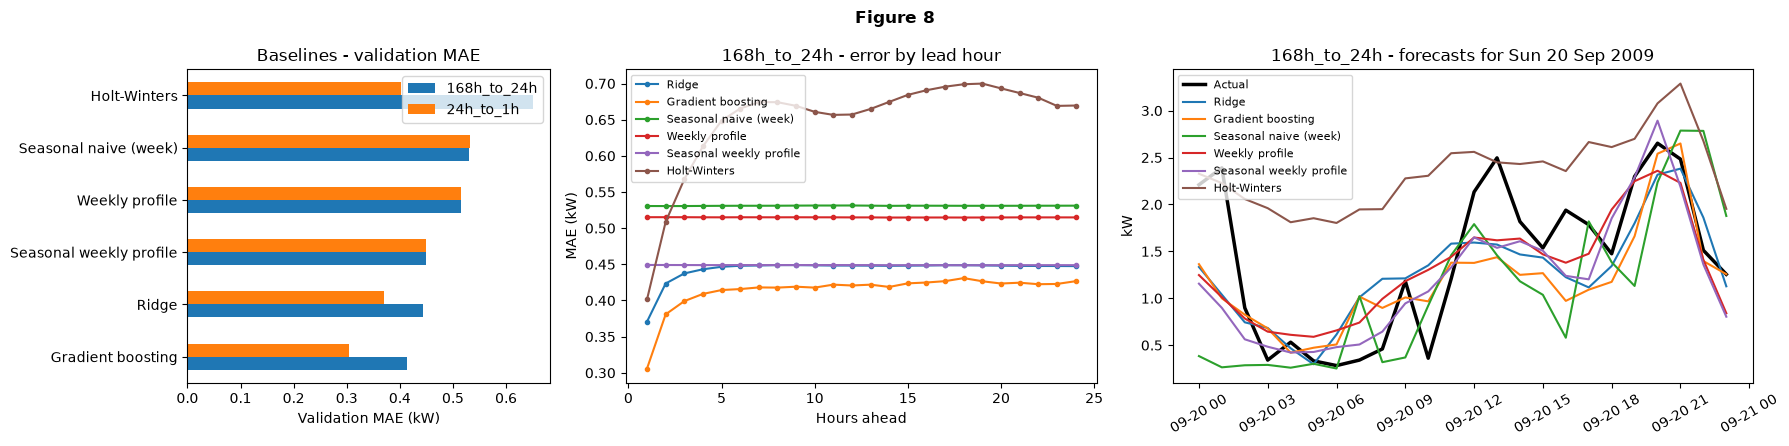

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={'width_ratios': [1, 1.3, 1.6]})

# (a) Validation MAE per model for both setups
mae_table = pd.DataFrame({setup: results[setup]['MAE'] for setup in WINDOWS}).sort_values('168h_to_24h')
mae_table.plot.barh(ax=axes[0])
axes[0].set(xlabel='Validation MAE (kW)', title='Baselines - validation MAE')

# (b) Error by lead hour for the 24-hour horizon
va = data['168h_to_24h']['val']
for name, pred in val_pred['168h_to_24h'].items():
    lead_mae = np.nanmean(np.where(va['measured'], np.abs(pred - va['y_kw']), np.nan), axis=0)
    axes[1].plot(np.arange(1, 25), lead_mae, marker='.', label=name)
axes[1].set(xlabel='Hours ahead', ylabel='MAE (kW)', title='168h_to_24h - error by lead hour')
axes[1].legend(fontsize=8)

# (c) One validation day forecast from midnight
i = np.flatnonzero(is_midnight[va['t']])[len(va['t']) // 48]
hours = features.index[va['rows'][i]]
axes[2].plot(hours, va['y_kw'][i], 'k', lw=2.5, label='Actual')
for name, pred in val_pred['168h_to_24h'].items():
    axes[2].plot(hours, pred[i], label=name)
axes[2].set(ylabel='kW', title=f'168h_to_24h - forecasts for {hours[0]:%a %d %b %Y}')
axes[2].tick_params(axis='x', rotation=30)
axes[2].legend(fontsize=8)

plt.tight_layout()
show(8)

## Neural models: MLP and CNN
Both models are built for **either window setup** (the lookback length and horizon are constructor arguments) and are trained and scored on the same windows as the baselines.

**Diamond MLP.** The flattened lookback window goes through a narrow layer, expands, then shrinks before the output: `L·F → w → expand·w → w → H` (each hidden layer: Linear, BatchNorm, ReLU, Dropout).

**CNN.** Convolution blocks (Conv1d with **left-only padding** → optional BatchNorm → ReLU → optional AvgPool(2)). The head combines the conv features at the **last step**, the conv features **averaged over the window**, and the **last hour's raw inputs**, so it works for both 168 and 24 input steps.

**Loss.** Every model is scored on MAE, which is lowest at the *median* of the likely outcomes. Hourly load is right-skewed (mostly low, with short spikes), so the training loss should not let the spikes dominate. **L1** trains on the scored metric directly. **Huber** is squared for errors smaller than delta and linear beyond it: smooth gradients near zero, while large errors count linearly as in L1. Delta is in scaled units (1 = one standard deviation of hourly GAP); a small delta behaves like L1, a large one gives more weight to big misses. Early stopping and Optuna pruning use validation MAE (measured hours), so each network is stopped on the metric it is judged by. Gradient boosting already trains on absolute error.

**Two steps.**
1. **Equal footing.** MLP and CNN are trained with the **same training hyperparameters** (learning rate, weight decay, batch size, dropout, early stopping) and default sizes, and compared with the baselines on the same validation windows. Each network is trained with **L1** and with **Huber** at three deltas (0.1, 0.3, 1.0); the lowest validation MAE picks that network's loss, and its tuned version keeps it. If Huber is picked, its delta is tuned again in step 2.
2. **Tune the winner.** For each window setup, whichever of the two has the lower validation MAE is tuned with **Bayesian hyperparameter optimization** (Optuna, TPE sampler) and added to the comparison as `<model> (tuned)`.

Optuna proposes a configuration, trains it, and uses the validation MAE (kW, measured hours, the same metric as the baselines) to decide where to search next, instead of trying every grid point. Unpromising trials are **pruned**: if a trial's validation MAE after a few epochs is worse than the median of earlier trials at the same epoch, it is stopped early. The sampler is seeded, so the search is reproducible.

| | Search space |
|---|---|
| MLP | width `w ∈ {32, 64, 128, 256}`, expand `∈ {1, 2, 4, 8}`, dropout `0–0.5`, learning rate `5e-5–1e-2` (log), weight decay `1e-5–1e-1` (log), batch `∈ {64, 128, 256, 512, 1024}` |
| CNN | filters `∈ {16, 32, 64, 128}`, kernel `∈ {2, 3, 5, 7, 9}`, blocks `∈ {1, 2, 3, 4}`, BatchNorm on/off, pooling on/off, dropout, learning rate, weight decay, batch (as MLP) |
| Huber delta | `0.05–2` (log), searched only when Huber was selected in step 1 |

BatchNorm and pooling are therefore only kept if they lower the validation error. `N_TRIALS` sets the budget per tuned model and setup.

**Causality / no leakage.** Every input is from rows `t-L … t-1`, before the first target hour `t`, so nothing inside the network (convolutions, BatchNorm, pooling) can see a target hour. Without pooling the conv stack is also causal step by step: a test below changes the later part of a window and asserts the earlier conv features do not move (BatchNorm included, since at inference it is a fixed per-channel scale). Training uses AdamW on the scaled target with the selected loss and early stopping on validation MAE; validation is the period right after training, so stopping and HPO are chronological. The test set is not used.

In [ ]:
N_FEATURES = X_all.shape[1]
BATCH, MAX_EPOCHS, PATIENCE = 256, 100, 10

class DiamondMLP(nn.Module):
    """Flattened lookback -> w -> expand*w -> w -> horizon."""
    def __init__(self, lookback, horizon, width=64, expand=4, dropout=0.2):
        super().__init__()
        dims = [lookback * N_FEATURES, width, width * expand, width]
        blocks = [nn.Flatten()]
        for d_in, d_out in zip(dims, dims[1:]):
            blocks += [nn.Linear(d_in, d_out), nn.BatchNorm1d(d_out), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*blocks, nn.Linear(width, horizon))

    def forward(self, x):
        return self.net(x)

class CausalConv1d(nn.Conv1d):
    """Conv1d padded on the left only, so output step i only sees input steps <= i."""
    def __init__(self, c_in, c_out, kernel):
        super().__init__(c_in, c_out, kernel)
        self.left_pad = kernel - 1

    def forward(self, x):
        return super().forward(nn.functional.pad(x, (self.left_pad, 0)))

class CausalCNN(nn.Module):
    """Causal conv blocks (optional BatchNorm / AvgPool); the head sees the last step's features, their mean over
    the window, and the last raw hour."""
    def __init__(self, lookback, horizon, filters=32, kernel=3, blocks=3, dropout=0.2, batchnorm=False, pool=False):
        super().__init__()
        layers, c_in = [], N_FEATURES
        for _ in range(blocks):
            layers.append(CausalConv1d(c_in, filters, kernel))
            if batchnorm:
                layers.append(nn.BatchNorm1d(filters))
            layers.append(nn.ReLU())
            if pool:
                layers.append(nn.AvgPool1d(2))
            c_in = filters
        self.convs = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * filters + N_FEATURES, horizon))

    def features(self, x):
        return self.convs(x.transpose(1, 2))  # (batch, time, features) -> (batch, filters, time)

    def forward(self, x):
        h = self.features(x)
        return self.head(torch.cat([h[:, :, -1], h.mean(2), x[:, -1]], dim=1))

ARCHS = {'MLP': DiamondMLP, 'CNN': CausalCNN}  # family name -> class; saved networks are rebuilt from it

# Checks for both setups and every CNN option: output shapes, and (without pooling) step-by-step causality of the
# conv stack: changing steps >= k of a window must leave the conv features at steps < k unchanged
for setup, w in WINDOWS.items():
    x = torch.randn(4, w['lookback'], N_FEATURES)
    assert DiamondMLP(**w).eval()(x).shape == (4, w['horizon'])
    for batchnorm, pool in itertools.product((False, True), (False, True)):
        cnn = CausalCNN(**w, batchnorm=batchnorm, pool=pool).eval()
        assert cnn(x).shape == (4, w['horizon'])
        assert CausalCNN(**w, blocks=4, kernel=9, batchnorm=batchnorm, pool=pool).eval()(x).shape == (4, w['horizon'])
        if not pool:
            k = w['lookback'] // 2
            x_changed = x.clone()
            x_changed[:, k:] += torch.randn_like(x_changed[:, k:])
            with torch.no_grad():
                assert torch.allclose(cnn.features(x)[:, :, :k], cnn.features(x_changed)[:, :, :k])
print('Shape and causality checks passed for', list(WINDOWS))

Shape and causality checks passed for ['168h_to_24h', '24h_to_1h']


In [ ]:
# Network training: losses and fit(), shared by the Stage 1 and Stage 2 networks
import copy
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)  # progress is printed by tune() instead
N_TRIALS = 20  # Bayesian HPO budget per model and setup
LOSSES = {'L1': lambda delta: nn.L1Loss(), 'Huber': lambda delta: nn.HuberLoss(delta=delta)}  # delta: scaled GAP
LOSS_CANDIDATES = [{'loss': 'L1'}] + [{'loss': 'Huber', 'huber_delta': d} for d in (0.1, 0.3, 1.0)]
TRAIN_KEYS = ('lr', 'weight_decay', 'batch_size', 'huber_delta', 'clip_norm')  # passed to fit(), not to the model

def loss_name(loss, huber_delta=1.0):
    return loss if loss == 'L1' else f'Huber (delta={huber_delta:.3g})'

def fit(build, setup, lr=1e-3, weight_decay=1e-2, batch_size=BATCH, loss='L1', huber_delta=1.0, clip_norm=None,
        max_epochs=MAX_EPOCHS, patience=PATIENCE, trial=None, refit_epochs=None):
    """Train the network made by `build()` with `loss` (L1, or Huber with `huber_delta`) and early stopping on
    validation MAE (scaled GAP, measured hours - the scored metric). Returns the best model, its history (train and
    validation MAE, both in eval mode on measured hours, plus the training loss per epoch) and the train time.
    clip_norm: clip the gradient norm (used by the recurrent models).
    trial: an Optuna trial; the validation MAE is reported each epoch so the pruner can stop a poor trial early.
    refit_epochs: train on data[setup]['trainval'] for exactly that many epochs instead, with no early stopping."""
    set_seed()
    model = build().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = LOSSES[loss](huber_delta)
    tr, va = data[setup]['trainval' if refit_epochs else 'train'], data[setup]['val']
    X_tr, y_tr, m_tr = (torch.from_numpy(tr[k]).to(device) for k in ('X', 'y', 'measured'))
    X_va, y_va, m_va = (torch.from_numpy(va[k]).to(device) for k in ('X', 'y', 'measured'))
    history = {'train': [], 'val': [], 'loss': []}

    def mae(X, y, measured):
        pred = torch.cat([model(xb) for xb in X.split(PREDICT_BATCH)]).reshape(y.shape)
        return (pred - y).abs()[measured].mean().item()

    best_mae, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start = time.perf_counter()
    for epoch in range(refit_epochs or max_epochs):
        model.train()
        total = 0.0
        for idx in torch.randperm(len(X_tr), device=device).split(batch_size):
            opt.zero_grad()
            batch_loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            batch_loss.backward()
            if clip_norm is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
            opt.step()
            total += batch_loss.detach() * len(idx)
        history['loss'].append(total.item() / len(X_tr))
        if refit_epochs:
            continue
        model.eval()
        with torch.no_grad():
            history['train'].append(mae(X_tr, y_tr, m_tr))
            val_mae = mae(X_va, y_va, m_va)
        history['val'].append(val_mae)
        if trial is not None:
            trial.report(val_mae, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned(f'pruned at epoch {epoch + 1}')
        if val_mae < best_mae:
            best_mae, wait = val_mae, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    if not refit_epochs:
        model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start

In [ ]:
# Registries of trained networks and step 1 (equal footing), shared by both stages
# Every trained network by setup and name: '<family>' after step 1, '<family> (tuned)' for the Bayesian winner
nn_models, nn_histories, nn_loss, nn_cfgs, refits, studies = ({setup: {} for setup in WINDOWS} for _ in range(6))
nn_trials = []  # one row per Optuna trial, both stages

def family_of(name):
    return name.removesuffix(' (tuned)')

def build_network(setup, name, model_cfg):
    return ARCHS[family_of(name)](**WINDOWS[setup], **model_cfg).to(device)

def register_network(setup, name, model_cfg, train_cfg, model, history, secs):
    """Record a trained network and its validation forecasts (used by step 1, tuning and checkpoint loading)."""
    nn_models[setup][name], nn_histories[setup][name], train_secs[setup][name] = model, history, secs
    nn_cfgs[setup][name] = (model_cfg, train_cfg)
    nn_loss[setup][name] = loss_name(train_cfg['loss'], train_cfg.get('huber_delta', 1.0))
    val_pred[setup][name] = forecast(model, data[setup]['val'])

def model_forecast(setup, name, d):
    """Forecasts in kW for windows d from any trained model, by name."""
    if name in BASELINE_FNS:
        return BASELINE_FNS[name](d)
    return forecast(fitted[setup][name] if name in fitted[setup] else nn_models[setup][name], d)

def train_equal_footing(defaults, shared):
    """Step 1: every family (name -> default model config) on both setups with the same training settings `shared`
    and every candidate loss; each family keeps the loss with the lowest validation MAE. Returns one row per run."""
    rows, n_runs = [], len(WINDOWS) * len(defaults) * len(LOSS_CANDIDATES)
    for setup in WINDOWS:
        va = data[setup]['val']
        for name, model_cfg in defaults.items():
            best = None
            for loss_cfg in LOSS_CANDIDATES:
                model, history, secs = fit(lambda: build_network(setup, name, model_cfg), setup, **loss_cfg, **shared)
                mae = evaluate(va, forecast(model, va))['MAE']
                rows.append({'setup': setup, 'model': name, 'loss': loss_name(**loss_cfg), 'val MAE': mae})
                print(f'[{len(rows)}/{n_runs}] {name} {setup} {loss_name(**loss_cfg)}: {len(history["val"])} epochs, '
                      f'val MAE {mae:.4f} ({secs:.1f} s)', flush=True)
                if best is None or mae < best[0]:
                    best = (mae, {**shared, **loss_cfg}, model, history, secs)
            register_network(setup, name, model_cfg, *best[1:])
    return rows

def loss_table(rows):
    """Validation MAE of each family under each candidate loss, and the loss it kept."""
    table = pd.DataFrame(rows).pivot(index=['setup', 'model'], columns='loss', values='val MAE')
    table = table[[loss_name(**c) for c in LOSS_CANDIDATES]]
    table['selected'] = table.idxmin(axis=1)
    return table

In [ ]:
# Step 2 (Bayesian tuning) and the validation results table, shared by both stages
def tune(name, space, setup, n_trials=N_TRIALS):
    """Bayesian HPO (Optuna TPE) of one family on one setup, minimising validation MAE (kW, measured hours). Keeps
    the loss chosen in step 1 (tuning its delta when it is Huber). The best trial becomes '<name> (tuned)'."""
    va, best = data[setup]['val'], {}
    loss = nn_cfgs[setup][name][1]['loss']

    def objective(trial):
        cfg = space(trial)
        if loss == 'Huber':
            cfg['huber_delta'] = trial.suggest_float('huber_delta', 0.05, 2.0, log=True)
        model_cfg = {k: v for k, v in cfg.items() if k not in TRAIN_KEYS}
        train_cfg = {'loss': loss, **{k: cfg[k] for k in TRAIN_KEYS if k in cfg}}
        row = {'model': name, 'setup': setup, 'trial': trial.number, **cfg}
        start = time.perf_counter()
        try:
            model, history, secs = fit(lambda: build_network(setup, name, model_cfg), setup, trial=trial, **train_cfg)
        except optuna.TrialPruned as pruned:
            nn_trials.append({**row, 'state': 'pruned', 'train time (s)': time.perf_counter() - start})
            print(f'[{trial.number + 1}/{n_trials}] {name} {setup}: {pruned}', flush=True)
            raise
        mae = evaluate(va, forecast(model, va))['MAE']
        nn_trials.append({**row, 'state': 'complete', 'epochs': len(history['val']), 'val MAE': mae,
                          'params': count_params(model), 'train time (s)': secs})
        if not best or mae < best['mae']:
            best.update(mae=mae, model=model, history=history, secs=secs, model_cfg=model_cfg, train_cfg=train_cfg)
        print(f'[{trial.number + 1}/{n_trials}] {name} {setup}: {len(history["val"])} epochs, val MAE {mae:.4f} '
              f'({secs:.1f} s) | best so far {best["mae"]:.4f}', flush=True)
        return mae

    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5))
    study.optimize(objective, n_trials=n_trials)
    studies[setup][name] = study
    print(f'==> {name} {setup}: best val MAE {best["mae"]:.4f} with {study.best_params}\n', flush=True)
    register_network(setup, f'{name} (tuned)', best['model_cfg'], best['train_cfg'], best['model'], best['history'],
                     best['secs'])

def results_table(setup):
    """validation_table plus each network's training loss and parameter count."""
    table = validation_table(setup)
    table.insert(len(table.columns) - 1, 'loss', pd.Series(nn_loss[setup]))  # training loss of each network
    table.insert(len(table.columns) - 1, 'params', pd.Series({name: count_params(m) for name, m in nn_models[setup].items()}))
    return table

In [ ]:
# Train + validation refits and checkpoint packing, shared by both stages
def retrain(setup, name, windows, **fit_kwargs):
    """Ridge, gradient boosting or the network `name`, trained on `windows` with its selected hyperparameters.
    A network trains with fit(), which reads data[setup]['train'] (or data[setup]['trainval'] with refit_epochs), so
    `windows` must be that entry; fit_kwargs go to fit(). Returns (model, training history or None)."""
    if name == 'Ridge':
        return Ridge(alpha=best_trial(ridge_trials, setup)['alpha']).fit(flat(windows['X']), windows['y']), None
    if name == 'Gradient boosting':
        cfg = best_trial(gb_trials, setup)
        return make_xgb(cfg['learning_rate'], cfg['max_leaf_nodes'], cfg['l2'], cfg['rounds']).fit(
            gb_features(windows['X'], WINDOWS[setup]['horizon']), windows['y']).get_booster(), None
    model_cfg, train_cfg = nn_cfgs[setup][name]
    return fit(lambda: build_network(setup, name, model_cfg), setup, **train_cfg, **fit_kwargs)[:2]

def refit_on_train_val(setup, names, histories=None):
    """Refit the named models on every window whose targets lie in train + validation, with the hyperparameters
    already selected. Networks train for the epoch count of their best validation epoch, since no data is left for
    early stopping; histories (name -> training history) gives that epoch, by default each network's own in
    nn_histories. Returns name -> fitted model. The test split is never touched (asserted)."""
    w, trainval = WINDOWS[setup], (splits['train'][0], splits['val'][1])
    windows = data[setup]['trainval'] = make_windows(*trainval, **w)
    check_windows(windows, trainval, w['lookback'])  # every target hour ends before the test split
    histories = nn_histories[setup] if histories is None else histories
    out = {}
    for name in names:
        start = time.perf_counter()
        history = histories.get(name)  # None for Ridge and gradient boosting
        epochs = None if history is None else int(np.argmin(history['val'])) + 1
        out[name] = retrain(setup, name, windows, refit_epochs=epochs)[0]
        print(f"{setup}: refit {name} on {len(windows['t'])} train + validation windows "
              f"({time.perf_counter() - start:.1f} s)", flush=True)
    del data[setup]['trainval']  # free the memory
    return out

def cpu_state(model):
    return {k: v.detach().cpu() for k, v in model.state_dict().items()}

def pack_networks(names_by_setup):
    """Configs, weights (on the CPU), histories and train times of the named networks, for a checkpoint."""
    return {setup: {name: {'model_cfg': nn_cfgs[setup][name][0], 'train_cfg': nn_cfgs[setup][name][1],
                           'state': cpu_state(nn_models[setup][name]), 'history': nn_histories[setup][name],
                           'secs': train_secs[setup][name]} for name in names}
            for setup, names in names_by_setup.items()}

def load_networks(saved):
    for setup, networks in saved.items():
        for name, net in networks.items():
            model = build_network(setup, name, net['model_cfg'])
            model.load_state_dict(net['state'])
            register_network(setup, name, net['model_cfg'], net['train_cfg'], model, net['history'], net['secs'])

def pack_model(model):
    """A network as its weights (its config is in nn_cfgs); Ridge / XGBoost (or None) as it is."""
    return {'state': cpu_state(model)} if isinstance(model, nn.Module) else model

def unpack_model(setup, name, saved):
    """The inverse of pack_model: a network is rebuilt from the config of the model `name`."""
    if not isinstance(saved, dict):
        return saved
    model = build_network(setup, name, nn_cfgs[setup][name][0])
    model.load_state_dict(saved['state'])
    return model

def pack_refits(refits_by_setup):
    return {setup: {name: pack_model(model) for name, model in models.items()}
            for setup, models in refits_by_setup.items()}

def unpack_refits(saved):
    for setup, models in saved.items():
        for name, model in models.items():
            refits[setup][name] = unpack_model(setup, name, model)

def check_reload(saved_mae, current_mae):
    """Loaded models must reproduce the validation MAE they had when they were saved."""
    for setup in WINDOWS:
        assert saved_mae[setup].keys() == current_mae[setup].keys(), f'{setup}: saved and loaded models differ'
        for name, mae in saved_mae[setup].items():
            assert np.isclose(current_mae[setup][name], mae, atol=1e-5), \
                f'{setup} {name}: validation MAE {current_mae[setup][name]:.6f} vs {mae:.6f} when saved'
    print('Loaded models reproduce their saved validation scores')

In [ ]:
# Step 1: MLP and CNN with the same training hyperparameters, each trained with every candidate loss
SHARED = {'lr': 1e-3, 'weight_decay': 1e-2, 'batch_size': BATCH}  # identical for both networks
DEFAULTS = {'MLP': {'width': 64, 'expand': 4, 'dropout': 0.2},
            'CNN': {'filters': 32, 'kernel': 3, 'blocks': 3, 'dropout': 0.2, 'batchnorm': True, 'pool': False}}

if TrainStage1:
    loss_runs = train_equal_footing(DEFAULTS, SHARED)
else:
    loss_runs = stage1_ckpt['loss_runs']
    load_networks(stage1_ckpt['networks'])  # untuned and tuned networks, rebuilt from their configs and weights
    print(f'Stage 1 networks loaded from {STAGE1_CKPT}')

print('Validation MAE (kW) by training loss (untuned networks)')
display(loss_table(loss_runs).round(4))
for setup in WINDOWS:
    table = results_table(setup)
    print(f'\nValidation - {setup} (untuned MLP and CNN with the same training hyperparameters, selected loss)')
    display(table[~table.index.str.endswith('(tuned)')].round(4))

Stage 1 networks loaded from models/combined/stage1.pkl
Validation MAE (kW) by training loss (untuned networks)


loss                   L1  Huber (delta=0.1)  Huber (delta=0.3)  \
setup       model                                                 
168h_to_24h CNN    0.4201             0.4195             0.4226   
            MLP    0.4227             0.4209             0.4233   
24h_to_1h   CNN    0.3233             0.3239             0.3264   
            MLP    0.3234             0.3212             0.3237   

loss               Huber (delta=1)           selected  
setup       model                                      
168h_to_24h CNN             0.4339  Huber (delta=0.1)  
            MLP             0.4354  Huber (delta=0.1)  
24h_to_1h   CNN             0.3355                 L1  
            MLP             0.3324  Huber (delta=0.1)


Validation - 168h_to_24h (untuned MLP and CNN with the same training hyperparameters, selected loss)


,MAE,RMSE,MAE (midnight origins),loss,params,train time (s)
Gradient boosting,0.4139,0.5999,0.4148,NaN,NaN,98.4882
CNN,0.4195,0.6136,0.4208,Huber (delta=0.1),10032.0,18.8988
MLP,0.4209,0.6217,0.4201,Huber (delta=0.1),218264.0,2.6106
Ridge,0.4433,0.6056,0.4436,NaN,NaN,0.4740
Seasonal weekly profile,0.4489,0.6230,0.4490,NaN,NaN,NaN
Weekly profile,0.5149,0.6953,0.5150,NaN,NaN,NaN
Seasonal naive (week),0.5310,0.7977,0.5306,NaN,NaN,NaN
Holt-Winters,0.6502,0.8609,0.6413,NaN,NaN,2.4133



Validation - 24h_to_1h (untuned MLP and CNN with the same training hyperparameters, selected loss)


,MAE,RMSE,loss,params,train time (s)
Gradient boosting,0.3039,0.4672,NaN,NaN,21.9891
MLP,0.3212,0.4967,Huber (delta=0.1),60097.0,4.2711
CNN,0.3233,0.4933,L1,8146.0,7.5338
Ridge,0.3704,0.5155,NaN,NaN,0.0310
Holt-Winters,0.4013,0.5710,NaN,NaN,2.4133
Seasonal weekly profile,0.4485,0.6225,NaN,NaN,NaN
Weekly profile,0.5144,0.6946,NaN,NaN,NaN
Seasonal naive (week),0.5315,0.7980,NaN,NaN,NaN


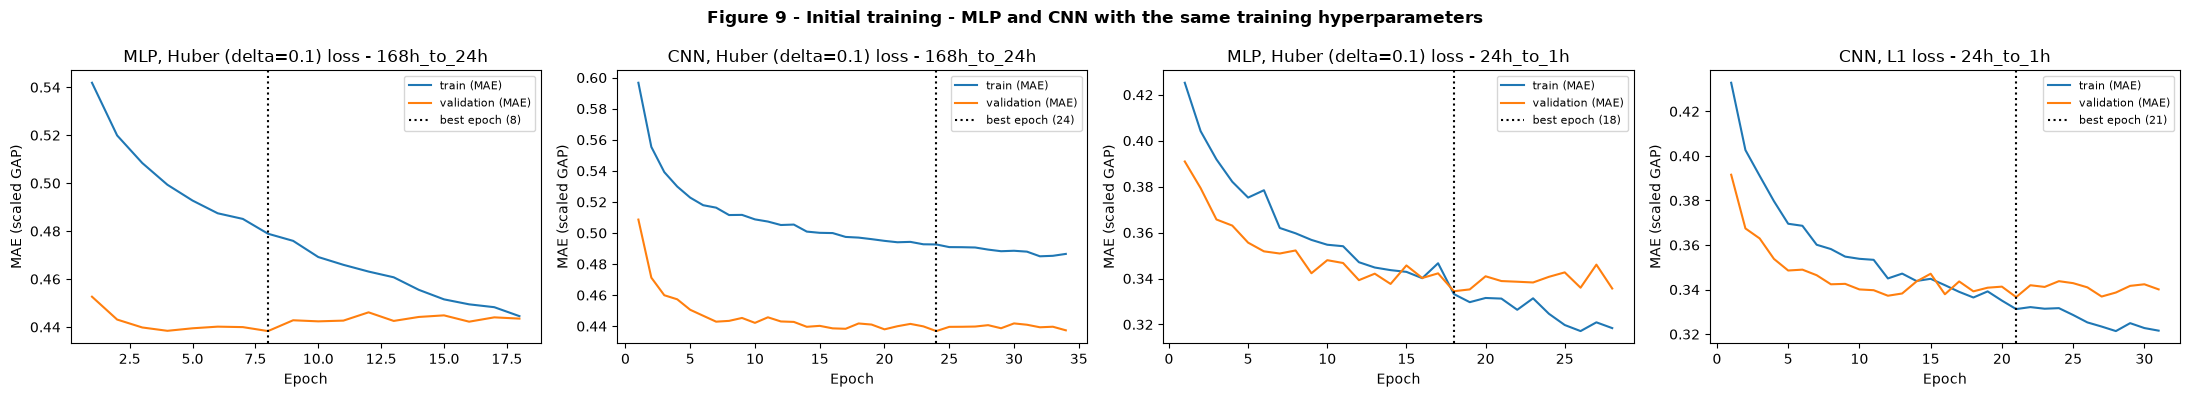

In [ ]:
def plot_curves(panels, title):
    """One learning-curve panel per (setup, model): train and validation MAE per epoch (same metric, eval mode,
    measured hours), best epoch marked."""
    fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4), squeeze=False)
    for ax, (setup, name) in zip(axes[0], panels):
        hist = nn_histories[setup][name]
        best = int(np.argmin(hist['val']))
        epochs = np.arange(1, len(hist['train']) + 1)
        ax.plot(epochs, hist['train'], label='train (MAE)')
        ax.plot(epochs, hist['val'], label='validation (MAE)')
        ax.axvline(best + 1, color='k', ls=':', label=f'best epoch ({best + 1})')
        ax.set(xlabel='Epoch', ylabel='MAE (scaled GAP)', title=f'{name}, {nn_loss[setup][name]} loss - {setup}')
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    show()

# Step 1 learning curves: MLP and CNN (same training hyperparameters) on the 24 h and the 1 h horizon
figure_number(9)
plot_curves([(setup, name) for setup in WINDOWS for name in DEFAULTS],
            'Initial training - MLP and CNN with the same training hyperparameters')

In [ ]:
# Step 2: Bayesian HPO of the better network for each setup
def training_space(trial):
    """Training settings searched for every network (both stages)."""
    return {'dropout': trial.suggest_float('dropout', 0.0, 0.5),
            'lr': trial.suggest_float('lr', 5e-5, 1e-2, log=True),
            'weight_decay': trial.suggest_float('weight_decay', 1e-5, 1e-1, log=True),
            'batch_size': trial.suggest_categorical('batch_size', [64, 128, 256, 512])}

def mlp_space(trial):
    return {'width': trial.suggest_categorical('width', [32, 64, 128, 256]),
            'expand': trial.suggest_categorical('expand', [1, 2, 4, 8]),
            **training_space(trial)}

def cnn_space(trial):
    return {'filters': trial.suggest_categorical('filters', [16, 32, 64, 128]),
            'kernel': trial.suggest_categorical('kernel', [2, 3, 5, 7, 9]),
            'blocks': trial.suggest_categorical('blocks', [1, 2, 3, 4]),  # 4 pooled blocks still fit the 24 h lookback
            'batchnorm': trial.suggest_categorical('batchnorm', [False, True]),
            'pool': trial.suggest_categorical('pool', [False, True]),
            **training_space(trial)}

SPACES = {'MLP': mlp_space, 'CNN': cnn_space}
best_family = {setup: min(DEFAULTS, key=lambda name: val_mae_of(setup, name)) for setup in WINDOWS}
if TrainStage1:
    for setup, family in best_family.items():
        print(f'{setup}: {family} has the lower untuned validation MAE -> tuning {family}', flush=True)
        tune(family, SPACES[family], setup)
else:
    nn_trials.extend(stage1_ckpt['nn_trials'])
    for setup in WINDOWS:
        studies[setup].update(stage1_ckpt['studies'][setup])
    print(f'Stage 1 Bayesian searches loaded from {STAGE1_CKPT}')

# Five best trials per setup
pd.DataFrame(nn_trials).sort_values(['setup', 'val MAE']).groupby('setup').head(5).dropna(axis=1, how='all').round(4)

Stage 1 Bayesian searches loaded from models/combined/stage1.pkl


,model,setup,trial,filters,kernel,blocks,batchnorm,pool,dropout,lr,weight_decay,batch_size,huber_delta,state,epochs,val MAE,params,train time (s),width,expand
14,CNN,168h_to_24h,14,32.0,3.0,4.0,False,False,0.0521,0.0012,0.0227,128,0.1329,complete,23.0,0.4168,12944.0,71.6954,NaN,NaN
12,CNN,168h_to_24h,12,32.0,2.0,2.0,False,False,0.1272,0.0007,0.0215,128,0.3002,complete,54.0,0.4223,5168.0,63.0996,NaN,NaN
16,CNN,168h_to_24h,16,128.0,2.0,2.0,False,False,0.0817,0.0016,0.0118,128,0.2634,complete,16.0,0.4225,43952.0,9.8846,NaN,NaN
4,CNN,168h_to_24h,4,32.0,2.0,4.0,False,False,0.0933,0.0057,0.0014,128,0.1159,complete,24.0,0.4248,9328.0,13.9002,NaN,NaN
17,CNN,168h_to_24h,17,64.0,3.0,4.0,True,False,0.1221,0.0027,0.0248,128,0.2249,complete,15.0,0.4256,44400.0,13.6448,NaN,NaN
34,MLP,24h_to_1h,14,NaN,NaN,NaN,NaN,NaN,0.1729,0.0020,0.0000,64,0.2044,complete,27.0,0.3167,34945.0,16.0699,64.0,1.0
20,MLP,24h_to_1h,0,NaN,NaN,NaN,NaN,NaN,0.3006,0.0021,0.0000,64,0.0984,complete,36.0,0.3187,93633.0,21.7286,64.0,8.0
38,MLP,24h_to_1h,18,NaN,NaN,NaN,NaN,NaN,0.1453,0.0014,0.0000,64,0.1771,complete,35.0,0.3203,34945.0,20.3611,64.0,1.0
21,MLP,24h_to_1h,1,NaN,NaN,NaN,NaN,NaN,0.2280,0.0032,0.0001,512,0.0938,complete,42.0,0.3230,34945.0,3.7756,64.0,1.0
24,MLP,24h_to_1h,4,NaN,NaN,NaN,NaN,NaN,0.0028,0.0038,0.0067,128,0.0767,complete,20.0,0.3291,369921.0,6.2031,256.0,2.0


Tuned models, validation MAE (kW): {'CNN (tuned) - 168h_to_24h': np.float64(0.4168), 'MLP (tuned) - 24h_to_1h': np.float64(0.3167)}


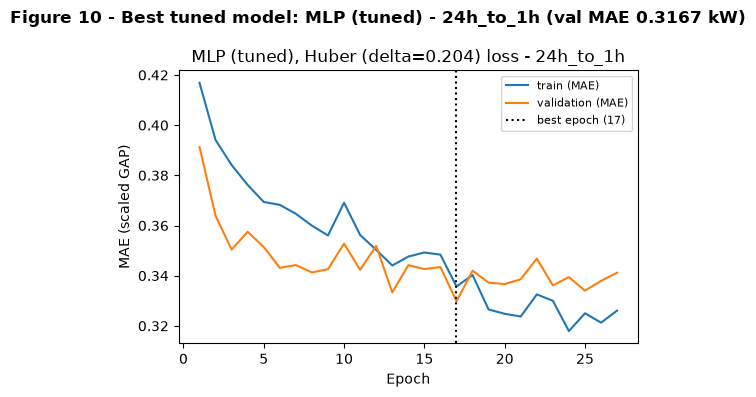

In [ ]:
# Learning curve of the tuned model with the lowest validation MAE
tuned_mae = {(setup, f'{family} (tuned)'): val_mae_of(setup, f'{family} (tuned)') for setup, family in best_family.items()}
best_tuned = min(tuned_mae, key=tuned_mae.get)
print('Tuned models, validation MAE (kW):', {f'{name} - {setup}': round(mae, 4) for (setup, name), mae in tuned_mae.items()})
figure_number(10)
plot_curves([best_tuned], f'Best tuned model: {best_tuned[1]} - {best_tuned[0]} (val MAE {tuned_mae[best_tuned]:.4f} kW)')

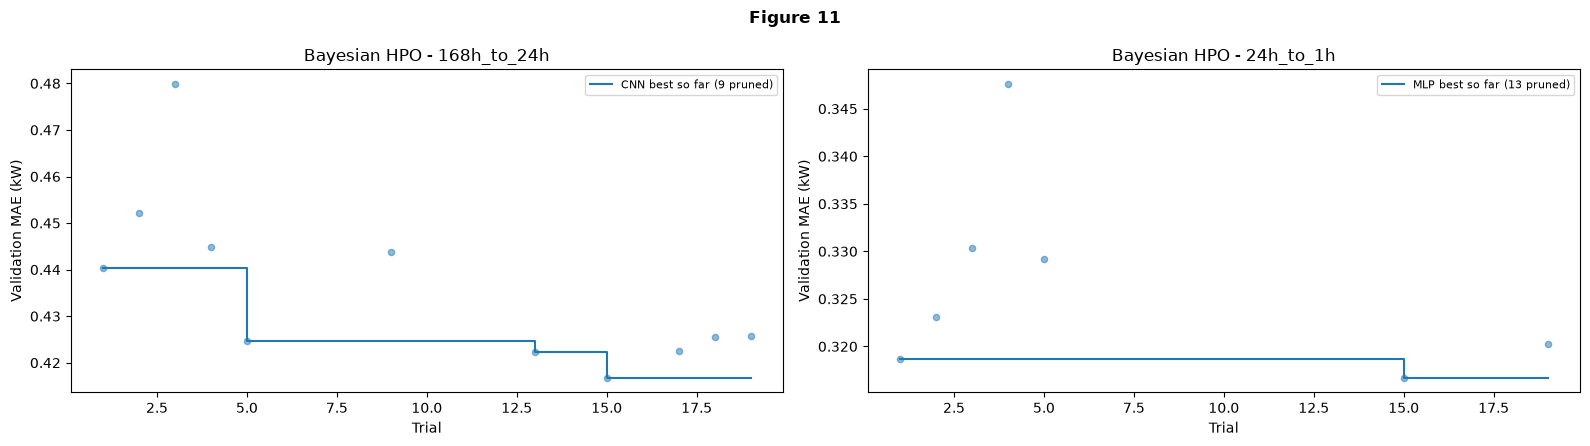

In [ ]:
def plot_hpo_progress(names_by_setup, title):
    """Per setup: every completed trial's validation MAE and the best so far for each named study (pruned trials
    are not plotted)."""
    fig, axes = plt.subplots(1, len(names_by_setup), figsize=(16, 4.5), squeeze=False)
    for ax, (setup, names) in zip(axes[0], names_by_setup.items()):
        for i, name in enumerate(names):
            trials = studies[setup][name].trials
            done = [t for t in trials if t.state == optuna.trial.TrialState.COMPLETE]
            n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in trials)
            x, y = [t.number + 1 for t in done], [t.value for t in done]
            ax.scatter(x, y, color=f'C{i}', alpha=0.5, s=20)
            ax.step(x, np.minimum.accumulate(y), where='post', color=f'C{i}', label=f'{name} best so far ({n_pruned} pruned)')
        ax.set(xlabel='Trial', ylabel='Validation MAE (kW)', title=f'{title} - {setup}')
        ax.legend(fontsize=8)
    plt.tight_layout()
    show()

figure_number(11)
plot_hpo_progress({setup: [family] for setup, family in best_family.items()}, 'Bayesian HPO')

**Search space.** Each panel shows one hyperparameter: every completed trial's value (x) against its validation MAE relative to the best trial (y, 1.0 = best). There is one figure per tuned model and setup (Figure 12 for Stage 1, Figure 16 for Stage 2). Clusters near 1.0 show where the Bayesian search concentrated and which values work; a flat cloud means the setting barely matters. The last panel ranks hyperparameter importance (Optuna's fANOVA estimate of how much each one explains the variation in validation MAE across trials).

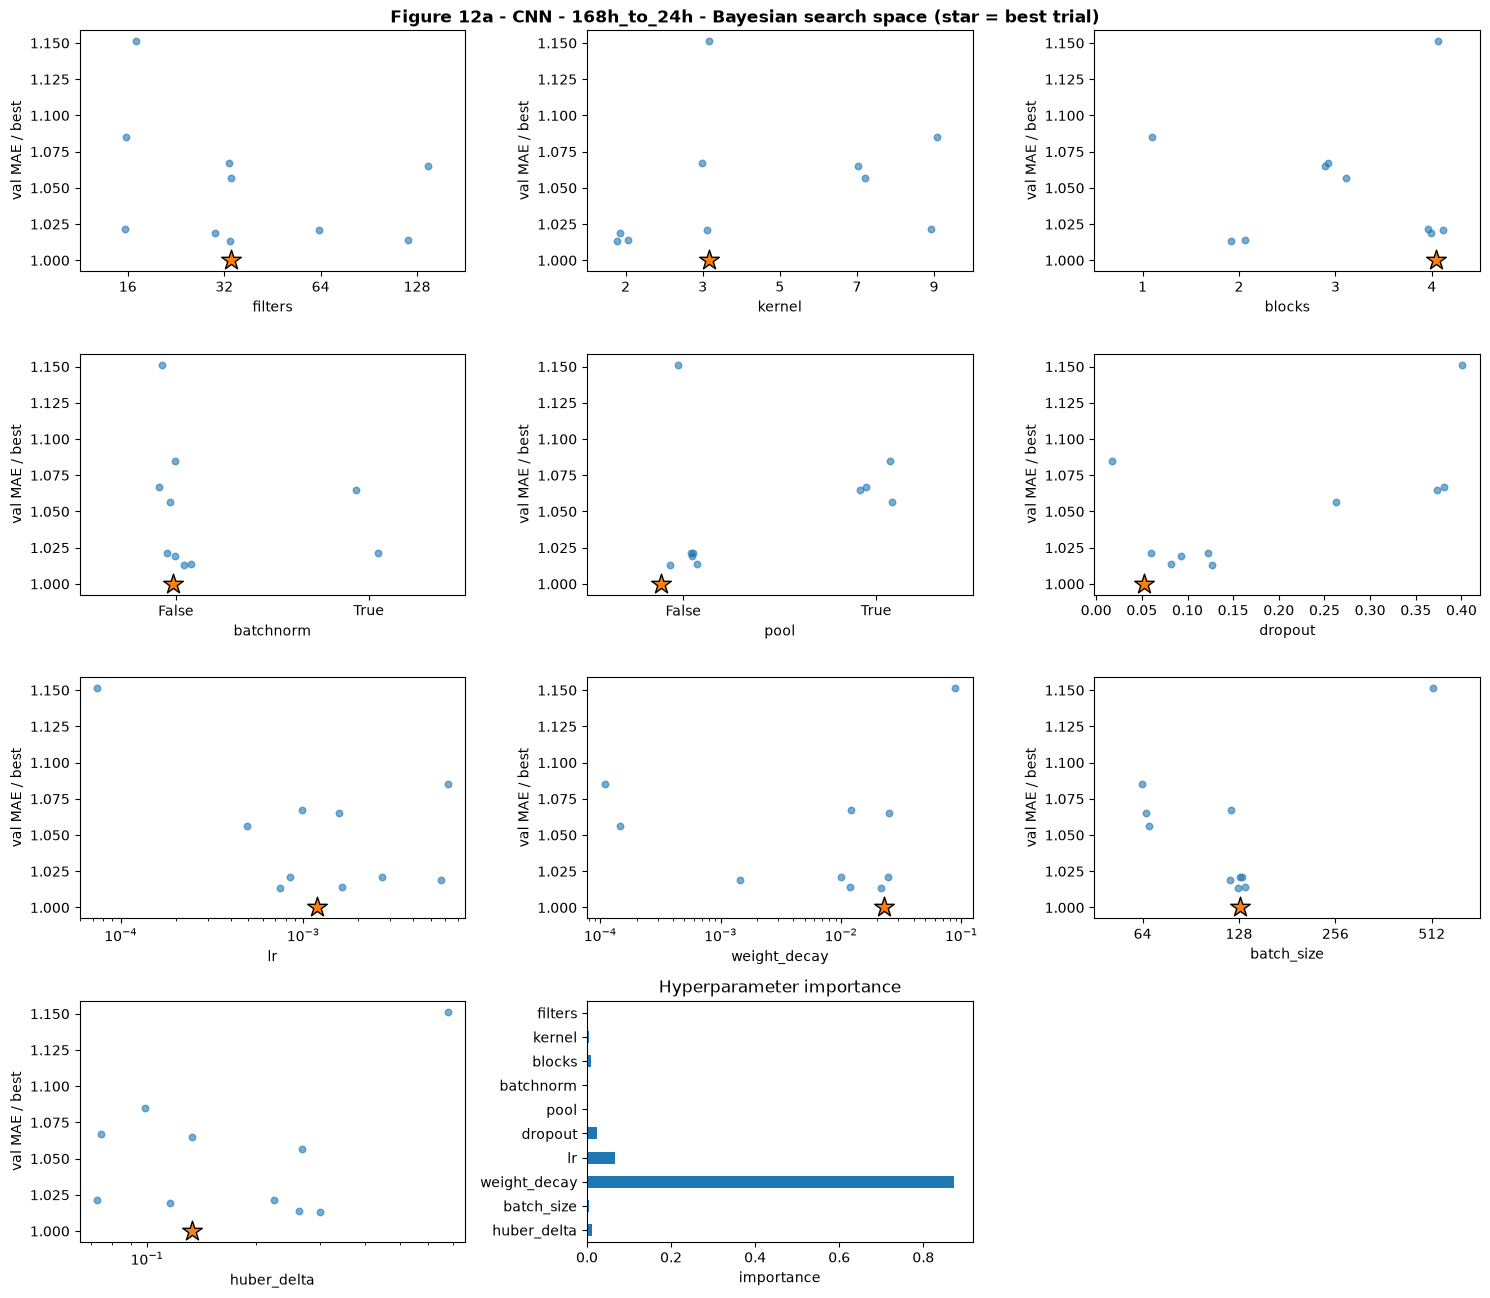

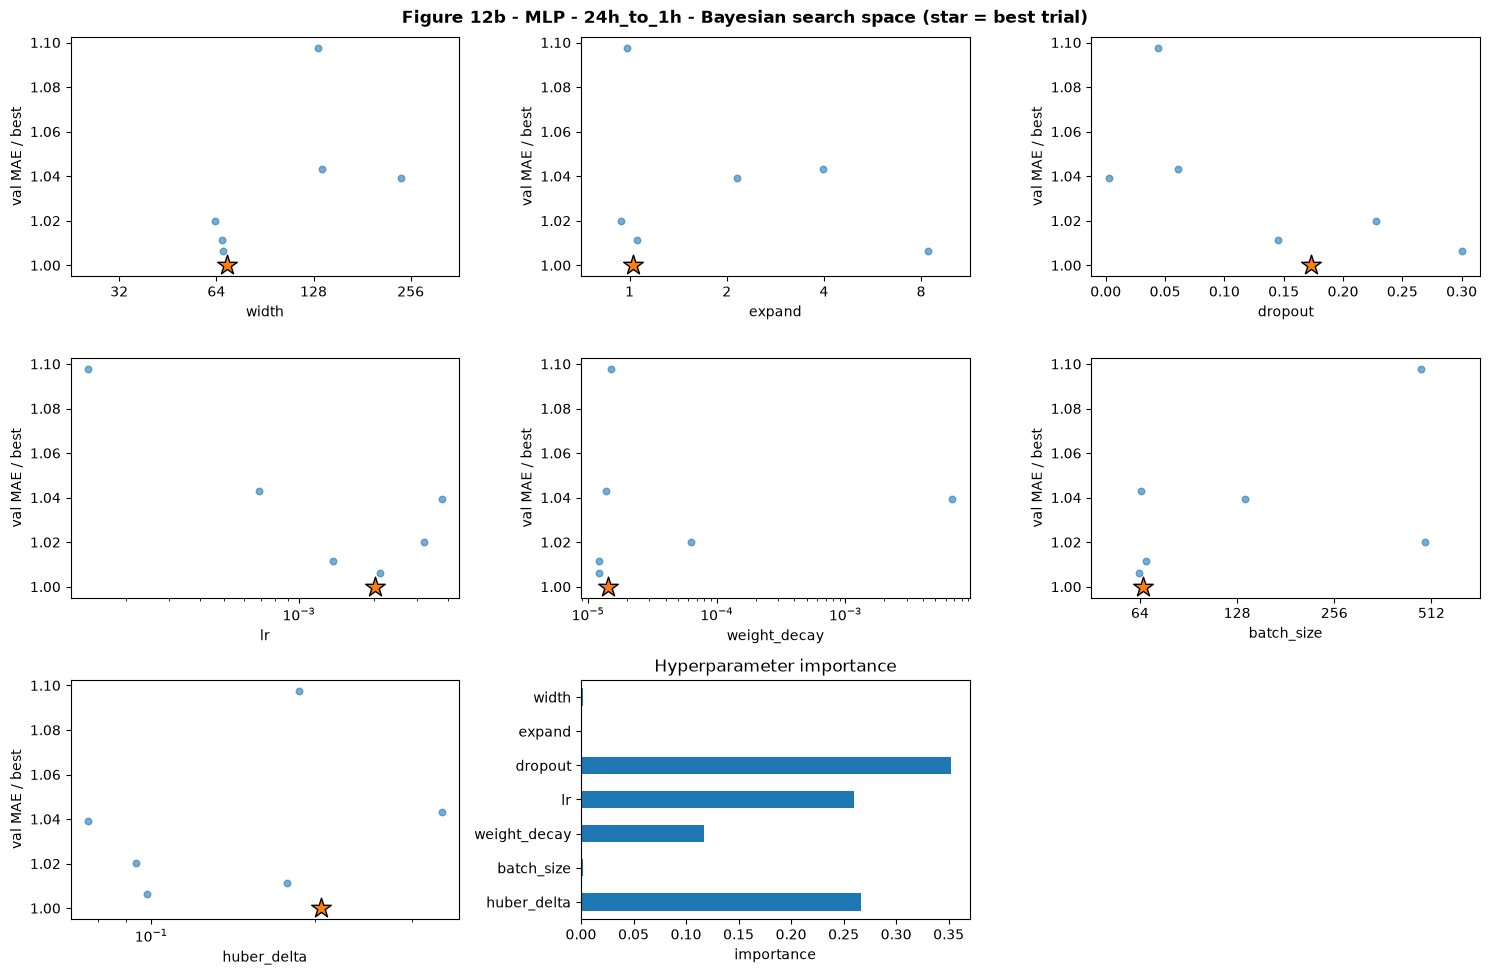

In [ ]:
import matplotlib

LOG_SCALE = {'lr', 'weight_decay', 'huber_delta'}

def plot_search_space(setup, name):
    """Hyperparameter value vs validation MAE (relative to the best) for every completed trial of one study, plus
    Optuna's hyperparameter importances."""
    study = studies[setup][name]
    complete = pd.DataFrame([t for t in nn_trials
                             if t['state'] == 'complete' and t['model'] == name and t['setup'] == setup])
    rel = complete['val MAE'] / complete['val MAE'].min()
    best = int(np.argmin(complete['val MAE'].to_numpy()))
    params = list(study.best_params)
    distributions = study.trials[0].distributions
    jitter = np.random.default_rng(SEED)
    ncols = 3
    nrows = -(-(len(params) + 1) // ncols)  # ceiling division; one extra panel for the importances
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.3 * nrows), squeeze=False)
    for ax, param in zip(axes.flat, params):
        choices = getattr(distributions[param], 'choices', None)  # categorical: evenly spaced positions, labelled
        if choices is None:
            x = complete[param].to_numpy(float)
        else:
            x = np.array([choices.index(v) for v in complete[param]]) + jitter.uniform(-0.12, 0.12, len(complete))
        ax.scatter(x, rel, color='C0', alpha=0.6, s=22)
        ax.scatter(x[best], 1.0, color='C1', marker='*', s=220, edgecolor='k', zorder=3)
        if choices is not None:
            ax.set_xticks(range(len(choices)), [str(v) for v in choices])
            ax.set_xlim(-0.5, len(choices) - 0.5)
        elif param in LOG_SCALE:
            ax.set_xscale('log')
            ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.set(xlabel=param, ylabel='val MAE / best')

    # Importances need a few completed trials with varied values
    ax = axes.flat[len(params)]
    try:
        importance = pd.Series(optuna.importance.get_param_importances(study)).reindex(params).fillna(0)
        importance.plot.barh(ax=ax, color='C0')
        ax.set(xlabel='importance', title='Hyperparameter importance')
        ax.invert_yaxis()
    except (RuntimeError, ValueError) as err:
        print(f'{name} {setup}: importances unavailable ({err})')
        ax.set_visible(False)
    for extra in axes.flat[len(params) + 1:]:
        extra.set_visible(False)
    fig.suptitle(f'{name} - {setup} - Bayesian search space (star = best trial)')
    plt.tight_layout()
    show()

figure_number(12, several=True)
for setup, family in best_family.items():
    plot_search_space(setup, family)

### Refit on train + validation
Model selection is finished, so the validation hours can also be used for training. The two best baselines (gradient boosting and Ridge) and the best MLP and best CNN of each setup (lowest validation MAE, tuned or not) are refitted on **all windows whose targets lie in train + validation**, with the hyperparameters already selected:
* **Ridge:** same alpha. **Gradient boosting:** same learning rate, leaves, L2 and number of rounds.
* **Networks:** same architecture, training settings and loss. No data is left for early stopping, so each trains for the epoch count at which its original run had its best validation MAE.
* The scaling statistics, profiles and Holt-Winters parameters are unchanged (train only), so the only difference is the extra 8 months of training data, which sit right before the test period.

The refits cannot be scored on validation (they trained on it), so they are only compared in the test section, with the same models trained on train only.

In [ ]:
# Refit the two best baselines and the best MLP and best CNN of each setup on train + validation (or load them)
REFIT_BASELINES = ('Gradient boosting', 'Ridge')  # the two best baselines on validation in both setups

def best_of_family(setup, family):
    """The family's untuned or tuned network, whichever has the lower validation MAE."""
    return min((n for n in nn_models[setup] if family_of(n) == family), key=lambda n: val_mae_of(setup, n))

if TrainStage1:
    for setup in WINDOWS:
        refits[setup].update(refit_on_train_val(setup, [*REFIT_BASELINES, *(best_of_family(setup, f) for f in DEFAULTS)]))
else:
    unpack_refits(stage1_ckpt['refits'])
print('Refitted on train + validation:', {setup: list(r) for setup, r in refits.items()})

Refitted on train + validation: {'168h_to_24h': ['Gradient boosting', 'Ridge', 'MLP', 'CNN (tuned)'], '24h_to_1h': ['Gradient boosting', 'Ridge', 'MLP (tuned)', 'CNN']}


In [ ]:
# Save every Stage 1 model (or check the loaded ones reproduce their saved validation scores)
stage1_val_mae = {setup: {n: val_mae_of(setup, n) for n in val_pred[setup]} for setup in WINDOWS}
if TrainStage1:
    save_checkpoint(STAGE1_CKPT, {
        'train_secs': train_secs, 'fitted': fitted, 'ridge_trials': ridge_trials, 'gb_trials': gb_trials,
        'hw_params': hw_params, 'hw_secs': hw_secs, 'loss_runs': loss_runs, 'nn_trials': nn_trials, 'studies': studies,
        'networks': pack_networks({setup: list(nn_models[setup]) for setup in WINDOWS}),
        'refits': pack_refits(refits), 'val_mae': stage1_val_mae})
else:
    check_reload(stage1_ckpt['val_mae'], stage1_val_mae)

Loaded models reproduce their saved validation scores


In [ ]:
# All Stage 1 models on the same validation windows (measured hours only)
for setup in WINDOWS:
    results[setup] = results_table(setup)
    print(f"Validation - {setup} ({len(data[setup]['val']['t'])} windows)")
    display(results[setup].round(4))
STAGE1_MODELS = {setup: list(results[setup].index) for setup in WINDOWS}  # validation order; tested in the next section

Validation - 168h_to_24h (6895 windows)


,MAE,RMSE,MAE (midnight origins),loss,params,train time (s)
Gradient boosting,0.4139,0.5999,0.4148,NaN,NaN,98.4882
CNN (tuned),0.4168,0.6092,0.4234,Huber (delta=0.133),12944.0,71.6954
CNN,0.4195,0.6136,0.4208,Huber (delta=0.1),10032.0,18.8988
MLP,0.4209,0.6217,0.4201,Huber (delta=0.1),218264.0,2.6106
Ridge,0.4433,0.6056,0.4436,NaN,NaN,0.4740
Seasonal weekly profile,0.4489,0.6230,0.4490,NaN,NaN,NaN
Weekly profile,0.5149,0.6953,0.5150,NaN,NaN,NaN
Seasonal naive (week),0.5310,0.7977,0.5306,NaN,NaN,NaN
Holt-Winters,0.6502,0.8609,0.6413,NaN,NaN,2.4133


Validation - 24h_to_1h (6918 windows)


,MAE,RMSE,loss,params,train time (s)
Gradient boosting,0.3039,0.4672,NaN,NaN,21.9891
MLP (tuned),0.3167,0.4890,Huber (delta=0.204),34945.0,16.0699
MLP,0.3212,0.4967,Huber (delta=0.1),60097.0,4.2711
CNN,0.3233,0.4933,L1,8146.0,7.5338
Ridge,0.3704,0.5155,NaN,NaN,0.0310
Holt-Winters,0.4013,0.5710,NaN,NaN,2.4133
Seasonal weekly profile,0.4485,0.6225,NaN,NaN,NaN
Weekly profile,0.5144,0.6946,NaN,NaN,NaN
Seasonal naive (week),0.5315,0.7980,NaN,NaN,NaN


## Stage 2: recurrent models and a TCN
Stage 2 adds six recurrent layouts (LSTM, GRU and SimpleRNN variants) and a temporal convolutional network (TCN), trained on **exactly the same data, windows and metrics as Stage 1**: both setups (168 h → 24 h and 24 h → 1 h), validation MAE on measured hours, train-only scaling, and the same `fit()` (AdamW, early stopping on validation MAE, the same candidate losses).

| Model | Layout (hidden = h) | Depth searched |
|---|---|---|
| Vanilla LSTM | `LSTM(h)` | 1, 2 layers |
| Stacked LSTM | `LSTM(h)` → `LSTM(h/2)` (→ `LSTM(h/2)`) | 2, 3 layers |
| Bidirectional LSTM | `Bidirectional(LSTM(h/2))` per layer | 1, 2 layers |
| LSTM + Dropout + Dense | `LSTM(h)`, `Dropout`, `Dense(h/2, relu)` | 1, 2 layers |
| Stacked GRU | `GRU(h)` → `GRU(h/2)` (→ `GRU(h/2)`) | 2, 3 layers |
| Stacked SimpleRNN | `RNN(h)` → `RNN(h/2)` (→ `RNN(h/2)`) | 2, 3 layers |
| TCN | causal dilated residual blocks, kernel 7, h channels | fewest levels covering the lookback, + 0 or 2 |

The output layer gives every forecast hour. Dropout is applied between layers and before the output, and gradients are clipped at norm 1.

**Two steps, as in Stage 1.**
1. **Equal footing.** All seven models with the same default size (h = 64, the smaller depth, dropout 0.2) and the same training settings as Stage 1, each trained with L1 and with Huber at delta 0.1, 0.3 and 1.0; the lowest validation MAE picks each model's loss.
2. **Bayesian tuning of all seven** in both setups (Optuna, `N_TRIALS` trials each): hidden size {32, 64, 128}, depth, dropout, learning rate, weight decay and batch size (the Stage 1 ranges), plus the Huber delta when Huber was picked. Each becomes `<model> (tuned)`.

The two best Stage 2 models per setup are then refitted on train + validation, like Stage 1. Whether Stage 2 is trained or loaded is set by `TrainStage2` in **Run settings** at the top. After the validation results, **Further investigation** looks for a lower validation error and picks the selected model; both stages are then tested together in **Test set evaluation** at the end.

**Causality.** Inputs are rows `t-L … t-1` only. The bidirectional LSTM reads that past window in both directions, so it sees no future values (as in Keras, its output joins the forward state at the last hour with the backward state at the first). The TCN's convolutions are causal (asserted below).

In [ ]:
# Stage 2 models (recurrent networks and a TCN), built like the Stage 1 networks
import functools
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

class Recurrent(nn.Module):
    """Recurrent layouts: `depth` layers (hidden, then hidden // 2 units), last time step -> horizon outputs.
    `lookback` is unused (the recurrence reads any length); it is accepted so every model is built the same way."""
    def __init__(self, lookback, horizon, cell, hidden=64, depth=1, dropout=0.2, bidirectional=False, dense_head=False):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[cell]
        dirs = 2 if bidirectional else 1
        sizes = [hidden // dirs] + [hidden // (2 * dirs)] * (depth - 1)  # units per direction
        inputs = [N_FEATURES] + [s * dirs for s in sizes[:-1]]
        self.layers = nn.ModuleList(rnn(i, s, batch_first=True, bidirectional=bidirectional) for i, s in zip(inputs, sizes))
        self.bidirectional, self.last = bidirectional, sizes[-1]
        self.drop = nn.Dropout(dropout)
        out = sizes[-1] * dirs
        self.head = (nn.Sequential(nn.Linear(out, hidden // 2), nn.ReLU(), nn.Linear(hidden // 2, horizon))
                     if dense_head else nn.Linear(out, horizon))

    def forward(self, x):
        for layer in self.layers:
            x = self.drop(layer(x)[0])
        if self.bidirectional:  # Keras-style: forward state after the last hour, backward state after the first
            return self.head(torch.cat([x[:, -1, :self.last], x[:, 0, self.last:]], dim=-1))
        return self.head(x[:, -1])

class DilatedCausalConv1d(nn.Module):
    """Dilated Conv1d whose output at each hour only sees that hour and earlier ones."""
    def __init__(self, c_in, c_out, kernel, dilation):
        super().__init__()
        self.pad = (kernel - 1) * dilation
        self.conv = nn.Conv1d(c_in, c_out, kernel, padding=self.pad, dilation=dilation)

    def forward(self, x):
        return self.conv(x)[..., :-self.pad]  # drop the right padding so no output sees a later hour

class TemporalBlock(nn.Module):
    def __init__(self, c_in, c_out, kernel, dilation, dropout):
        super().__init__()
        self.net = nn.Sequential(DilatedCausalConv1d(c_in, c_out, kernel, dilation), nn.ReLU(), nn.Dropout(dropout),
                                 DilatedCausalConv1d(c_out, c_out, kernel, dilation), nn.ReLU(), nn.Dropout(dropout))
        self.skip = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x):
        return torch.relu(self.net(x) + self.skip(x))

TCN_KERNEL = 7

def tcn_receptive_field(levels, kernel=TCN_KERNEL):
    return 1 + 2 * (kernel - 1) * (2 ** levels - 1)  # two convolutions per level, dilations 1, 2, 4, ...

def tcn_min_levels(lookback, kernel=TCN_KERNEL):
    """Fewest levels whose receptive field covers the lookback (4 for 168 h, 2 for 24 h with kernel 7)."""
    levels = 1
    while tcn_receptive_field(levels, kernel) < lookback:
        levels += 1
    return levels

class TCN(nn.Module):
    """Causal dilated residual blocks: the fewest levels that cover the lookback, plus `extra_levels`."""
    def __init__(self, lookback, horizon, hidden=64, extra_levels=0, dropout=0.2, kernel=TCN_KERNEL):
        super().__init__()
        channels = [N_FEATURES] + [hidden] * (tcn_min_levels(lookback, kernel) + extra_levels)
        self.net = nn.Sequential(*[TemporalBlock(a, b, kernel, 2 ** i, dropout)
                                   for i, (a, b) in enumerate(zip(channels, channels[1:]))])
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):
        return self.head(self.net(x.transpose(1, 2))[:, :, -1])  # (batch, time, features) -> channels first

In [ ]:
# The seven Stage 2 families, and shape / causality checks
# name -> (class, the hyperparameter that sets its depth, the values searched)
S2_FAMILIES = {
    'Vanilla LSTM':           (functools.partial(Recurrent, cell='LSTM'), 'depth', (1, 2)),
    'Stacked LSTM':           (functools.partial(Recurrent, cell='LSTM'), 'depth', (2, 3)),
    'Bidirectional LSTM':     (functools.partial(Recurrent, cell='LSTM', bidirectional=True), 'depth', (1, 2)),
    'LSTM + Dropout + Dense': (functools.partial(Recurrent, cell='LSTM', dense_head=True), 'depth', (1, 2)),
    'Stacked GRU':            (functools.partial(Recurrent, cell='GRU'), 'depth', (2, 3)),
    'Stacked SimpleRNN':      (functools.partial(Recurrent, cell='RNN'), 'depth', (2, 3)),
    'TCN':                    (TCN, 'extra_levels', (0, 2)),
}
ARCHS.update({name: cls for name, (cls, _, _) in S2_FAMILIES.items()})
STAGE_COLORS = {'Baseline': '0.6', 'Stage 1': 'C0', 'Stage 2': 'C1'}

def stage_of(name):
    family = family_of(name)
    return 'Stage 2' if family in S2_FAMILIES else 'Stage 1' if family in ARCHS else 'Baseline'

# Checks for both setups: every model and depth maps (batch, lookback, F) -> (batch, horizon), the TCN covers the
# lookback, and its outputs at earlier hours do not change when the last hour changes (causality)
for setup, w in WINDOWS.items():
    x = torch.randn(4, w['lookback'], N_FEATURES, device=device)
    for name, (cls, depth_key, choices) in S2_FAMILIES.items():
        for depth in choices:
            model = cls(**w, hidden=32, dropout=0.0, **{depth_key: depth}).to(device).eval()
            with torch.no_grad():
                assert model(x).shape == (4, w['horizon']), (setup, name, depth)
    assert tcn_receptive_field(tcn_min_levels(w['lookback'])) >= w['lookback']
    tcn = TCN(**w, hidden=8, dropout=0.0).to(device).eval()
    changed = x.clone()
    changed[:, -1] += 1.0
    with torch.no_grad():
        assert torch.allclose(tcn.net(x.transpose(1, 2))[..., :-1], tcn.net(changed.transpose(1, 2))[..., :-1])
print('Shape and causality checks passed for', list(S2_FAMILIES), 'on', list(WINDOWS))

Shape and causality checks passed for ['Vanilla LSTM', 'Stacked LSTM', 'Bidirectional LSTM', 'LSTM + Dropout + Dense', 'Stacked GRU', 'Stacked SimpleRNN', 'TCN'] on ['168h_to_24h', '24h_to_1h']


In [ ]:
# Stage 2 training settings, search space and checkpoint contents
S2_SHARED = {**SHARED, 'clip_norm': 1.0}  # Stage 1's training settings plus gradient clipping
S2_DEFAULTS = {name: {'hidden': 64, depth_key: choices[0], 'dropout': 0.2}
               for name, (_, depth_key, choices) in S2_FAMILIES.items()}
S2_REFITS = 2  # best Stage 2 models per setup refitted on train + validation

def s2_space(name):
    """Search space of one Stage 2 family: hidden size and depth, plus the training settings searched in Stage 1."""
    _, depth_key, choices = S2_FAMILIES[name]

    def space(trial):
        return {'hidden': trial.suggest_categorical('hidden', [32, 64, 128]),
                depth_key: trial.suggest_categorical(depth_key, list(choices)),
                **training_space(trial),
                'clip_norm': 1.0}  # fixed, not searched
    return space

def stage2_names():
    return {setup: [n for n in nn_models[setup] if stage_of(n) == 'Stage 2'] for setup in WINDOWS}

def stage2_payload(complete):
    """Everything needed to rebuild Stage 2; saved after step 1, after every Bayesian study, and at the end."""
    names = stage2_names()
    return {'complete': complete, 'loss_runs': s2_loss_runs, 'networks': pack_networks(names),
            'nn_trials': [row for row in nn_trials if row['model'] in S2_FAMILIES],
            'studies': {setup: {name: study for name, study in studies[setup].items() if name in S2_FAMILIES}
                        for setup in WINDOWS},
            'refits': pack_refits({setup: {name: model for name, model in refits[setup].items()
                                           if stage_of(name) == 'Stage 2'} for setup in WINDOWS}),
            'val_mae': {setup: {name: val_mae_of(setup, name) for name in names[setup]} for setup in WINDOWS}}

def restore_stage2(saved):
    """Load a Stage 2 checkpoint into the shared registries and check it; returns the step 1 loss runs."""
    load_networks(saved['networks'])
    nn_trials.extend(saved['nn_trials'])
    for setup in WINDOWS:
        studies[setup].update(saved['studies'][setup])
    unpack_refits(saved['refits'])
    check_reload(saved['val_mae'], {setup: {name: val_mae_of(setup, name) for name in names}
                                    for setup, names in stage2_names().items()})
    return saved['loss_runs']

In [ ]:
# Train, tune and refit Stage 2 (saving as it goes), or load it
stage2_ready = True
if TrainStage2:
    previous = load_checkpoint(STAGE2_CKPT, 'TrainStage2') if os.path.exists(STAGE2_CKPT) else None
    if previous is not None and not previous['complete']:  # an interrupted run: keep what finished
        print(f'Resuming the interrupted Stage 2 run saved in {STAGE2_CKPT}')
        s2_loss_runs = restore_stage2(previous)
    else:
        for setup in WINDOWS:  # a fresh run: forget any Stage 2 studies already in memory
            for name in S2_FAMILIES:
                studies[setup].pop(name, None)
        s2_loss_runs = train_equal_footing(S2_DEFAULTS, S2_SHARED)
        save_checkpoint(STAGE2_CKPT, stage2_payload(complete=False))
    for setup in WINDOWS:
        for name in S2_FAMILIES:
            if name not in studies[setup]:  # skipped when it finished before an interruption
                tune(name, s2_space(name), setup)
                save_checkpoint(STAGE2_CKPT, stage2_payload(complete=False))
    for setup in WINDOWS:
        best = sorted(stage2_names()[setup], key=lambda n: val_mae_of(setup, n))[:S2_REFITS]
        refits[setup].update(refit_on_train_val(setup, best))
    save_checkpoint(STAGE2_CKPT, stage2_payload(complete=True))
elif os.path.exists(STAGE2_CKPT):
    saved = load_checkpoint(STAGE2_CKPT, 'TrainStage2')
    assert saved['complete'], f'{STAGE2_CKPT} is from an interrupted run - set TrainStage2 = True to finish it'
    s2_loss_runs = restore_stage2(saved)
    print(f'Stage 2 models loaded from {STAGE2_CKPT}')
else:
    stage2_ready = False
    print(f'TrainStage2 = False and {STAGE2_CKPT} does not exist: Stage 2 is skipped')

Loaded models reproduce their saved validation scores
Stage 2 models loaded from models/combined/stage2.pkl


### Stage 2 validation results
The loss chosen by each model in step 1, then every model of the notebook (baselines, Stage 1 and Stage 2) on the same validation windows.

In [ ]:
if not stage2_ready:
    print('Stage 2 skipped')
else:
    print('Validation MAE (kW) by training loss (untuned Stage 2 models)')
    display(loss_table(s2_loss_runs).round(4))
    for setup in WINDOWS:
        table = results_table(setup)
        table.insert(0, 'stage', table.index.map(stage_of))
        print(f'\nValidation - {setup}: every model ({len(data[setup]["val"]["t"])} windows, measured hours)')
        display(table.round(4))

Validation MAE (kW) by training loss (untuned Stage 2 models)


loss                                    L1  Huber (delta=0.1)  \
setup       model                                               
168h_to_24h Bidirectional LSTM      0.4329             0.4325   
            LSTM + Dropout + Dense  0.4306             0.4362   
            Stacked GRU             0.4342             0.4323   
            Stacked LSTM            0.4375             0.4377   
            Stacked SimpleRNN       0.4338             0.4352   
            TCN                     0.4222             0.4221   
            Vanilla LSTM            0.4314             0.4325   
24h_to_1h   Bidirectional LSTM      0.3162             0.3161   
            LSTM + Dropout + Dense  0.3073             0.3071   
            Stacked GRU             0.3096             0.3096   
            Stacked LSTM            0.3123             0.3121   
            Stacked SimpleRNN       0.3262             0.3197   
            TCN                     0.3170             0.3153   
            Vanilla LSTM            0.3115             0.3117   

loss                                Huber (delta=0.3)  Huber (delta=1)  \
setup       model                                                        
168h_to_24h Bidirectional LSTM                 0.4336           0.4418   
            LSTM + Dropout + Dense             0.4330           0.4516   
            Stacked GRU                        0.4341           0.4437   
            Stacked LSTM                       0.4377           0.4542   
            Stacked SimpleRNN                  0.4356           0.4414   
            TCN                                0.4232           0.4397   
            Vanilla LSTM                       0.4330           0.4462   
24h_to_1h   Bidirectional LSTM                 0.3170           0.3256   
            LSTM + Dropout + Dense             0.3112           0.3186   
            Stacked GRU                        0.3134           0.3238   
            Stacked LSTM                       0.3137           0.3194   
            Stacked SimpleRNN                  0.3202           0.3294   
            TCN                                0.3203           0.3306   
            Vanilla LSTM                       0.3145           0.3224   

loss                                         selected  
setup       model                                      
168h_to_24h Bidirectional LSTM      Huber (delta=0.1)  
            LSTM + Dropout + Dense                 L1  
            Stacked GRU             Huber (delta=0.1)  
            Stacked LSTM                           L1  
            Stacked SimpleRNN                      L1  
            TCN                     Huber (delta=0.1)  
            Vanilla LSTM                           L1  
24h_to_1h   Bidirectional LSTM      Huber (delta=0.1)  
            LSTM + Dropout + Dense  Huber (delta=0.1)  
            Stacked GRU             Huber (delta=0.1)  
            Stacked LSTM            Huber (delta=0.1)  
            Stacked SimpleRNN       Huber (delta=0.1)  
            TCN                     Huber (delta=0.1)  
            Vanilla LSTM                           L1


Validation - 168h_to_24h: every model (6895 windows, measured hours)


,stage,MAE,RMSE,MAE (midnight origins),loss,params,train time (s)
Gradient boosting,Baseline,0.4139,0.5999,0.4148,NaN,NaN,98.4882
CNN (tuned),Stage 1,0.4168,0.6092,0.4234,Huber (delta=0.133),12944.0,71.6954
TCN (tuned),Stage 2,0.4173,0.6086,0.4229,Huber (delta=0.113),824472.0,68.8394
CNN,Stage 1,0.4195,0.6136,0.4208,Huber (delta=0.1),10032.0,18.8988
MLP,Stage 1,0.4209,0.6217,0.4201,Huber (delta=0.1),218264.0,2.6106
Stacked SimpleRNN (tuned),Stage 2,0.4210,0.6182,0.4321,L1,11352.0,7.0016
TCN,Stage 2,0.4221,0.6157,0.4249,Huber (delta=0.1),211544.0,28.1096
Stacked GRU (tuned),Stage 2,0.4246,0.6228,0.4313,Huber (delta=0.207),95256.0,27.2307
Bidirectional LSTM (tuned),Stage 2,0.4246,0.6170,0.4283,Huber (delta=0.12),45592.0,18.8202
Vanilla LSTM (tuned),Stage 2,0.4275,0.6206,0.4330,L1,78360.0,99.5173



Validation - 24h_to_1h: every model (6918 windows, measured hours)


,stage,MAE,RMSE,loss,params,train time (s)
Gradient boosting,Baseline,0.3039,0.4672,NaN,NaN,21.9891
Vanilla LSTM (tuned),Stage 2,0.3064,0.4768,L1,9745.0,8.6829
LSTM + Dropout + Dense,Stage 2,0.3071,0.4795,Huber (delta=0.1),23361.0,4.3864
LSTM + Dropout + Dense (tuned),Stage 2,0.3077,0.4795,Huber (delta=0.0728),83585.0,37.7146
Stacked LSTM (tuned),Stage 2,0.3094,0.4775,Huber (delta=0.142),124993.0,28.6531
Stacked GRU,Stage 2,0.3096,0.4841,Huber (delta=0.1),25377.0,9.1874
Stacked GRU (tuned),Stage 2,0.3100,0.4818,Huber (delta=0.0914),93761.0,6.3103
Vanilla LSTM,Stage 2,0.3115,0.4843,L1,21313.0,5.7016
Stacked LSTM,Stage 2,0.3121,0.4822,Huber (delta=0.1),33825.0,7.7421
TCN (tuned),Stage 2,0.3135,0.4893,Huber (delta=0.0838),95105.0,10.5317


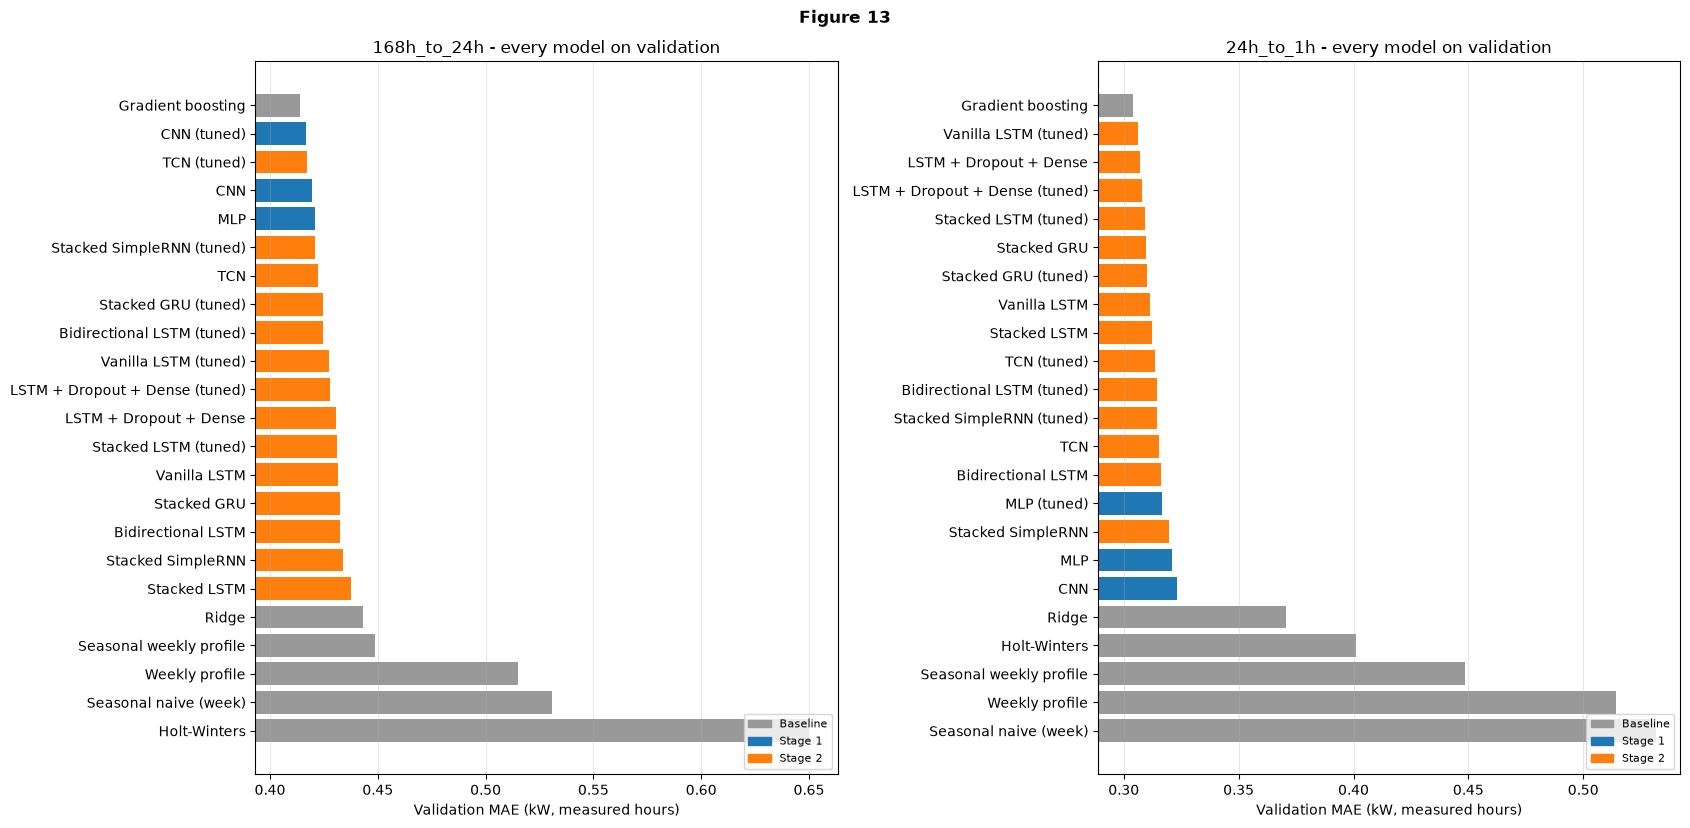

In [ ]:
# Validation MAE of every model, colored by stage
if not stage2_ready:
    print('Stage 2 skipped')
else:
    n_models = max(len(val_pred[s]) for s in WINDOWS)
    fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 1.5 + 0.3 * n_models))
    for ax, setup in zip(axes, WINDOWS):
        names = sorted(val_pred[setup], key=lambda n: val_mae_of(setup, n))[::-1]  # best at the top
        maes = [val_mae_of(setup, n) for n in names]
        ax.barh(names, maes, color=[STAGE_COLORS[stage_of(n)] for n in names])
        ax.set_xlim(min(maes) * 0.95, max(maes) * 1.02)
        ax.set(xlabel='Validation MAE (kW, measured hours)', title=f'{setup} - every model on validation')
        ax.legend(handles=[Patch(color=c, label=s) for s, c in STAGE_COLORS.items()], loc='lower right', fontsize=8)
        ax.grid(alpha=0.3, axis='x')
    plt.tight_layout()
    show(13)

### Stage 2 training and tuning diagnostics
Learning curves of the best tuned Stage 2 model per setup, the Bayesian search progress of all seven models, and the search space of the two best tuned models per setup (read as in Stage 1).

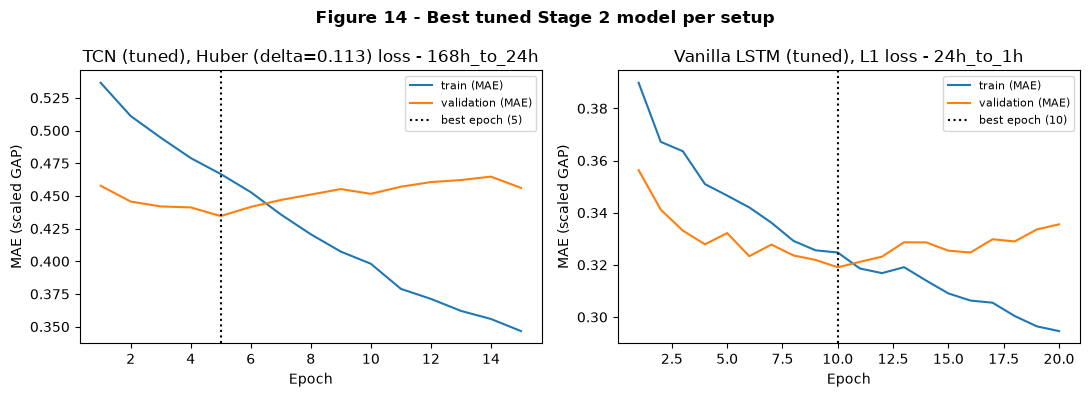

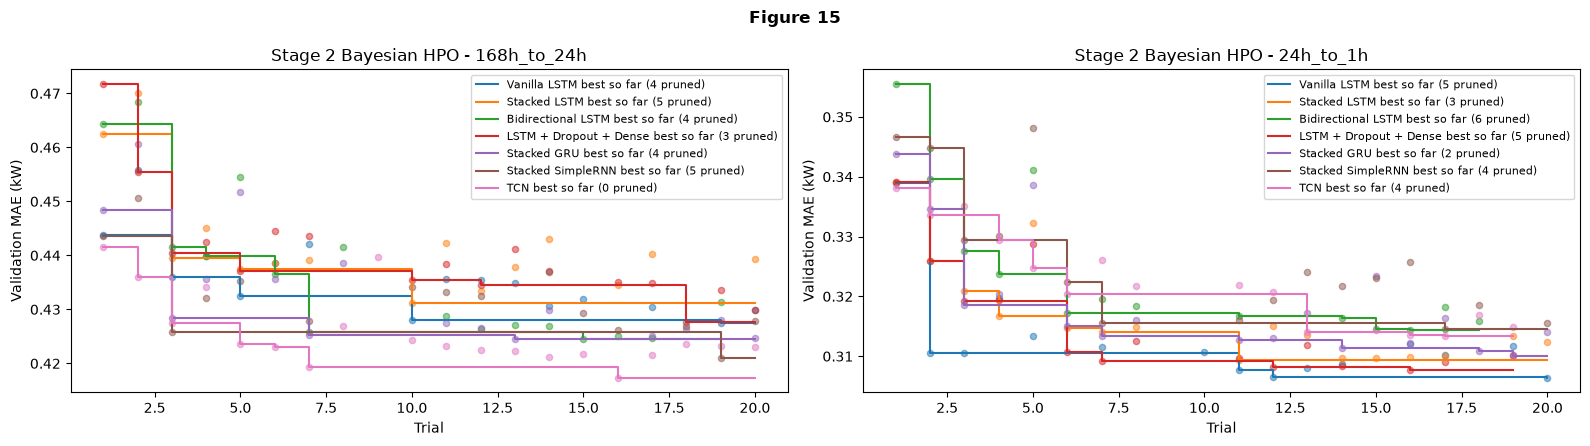

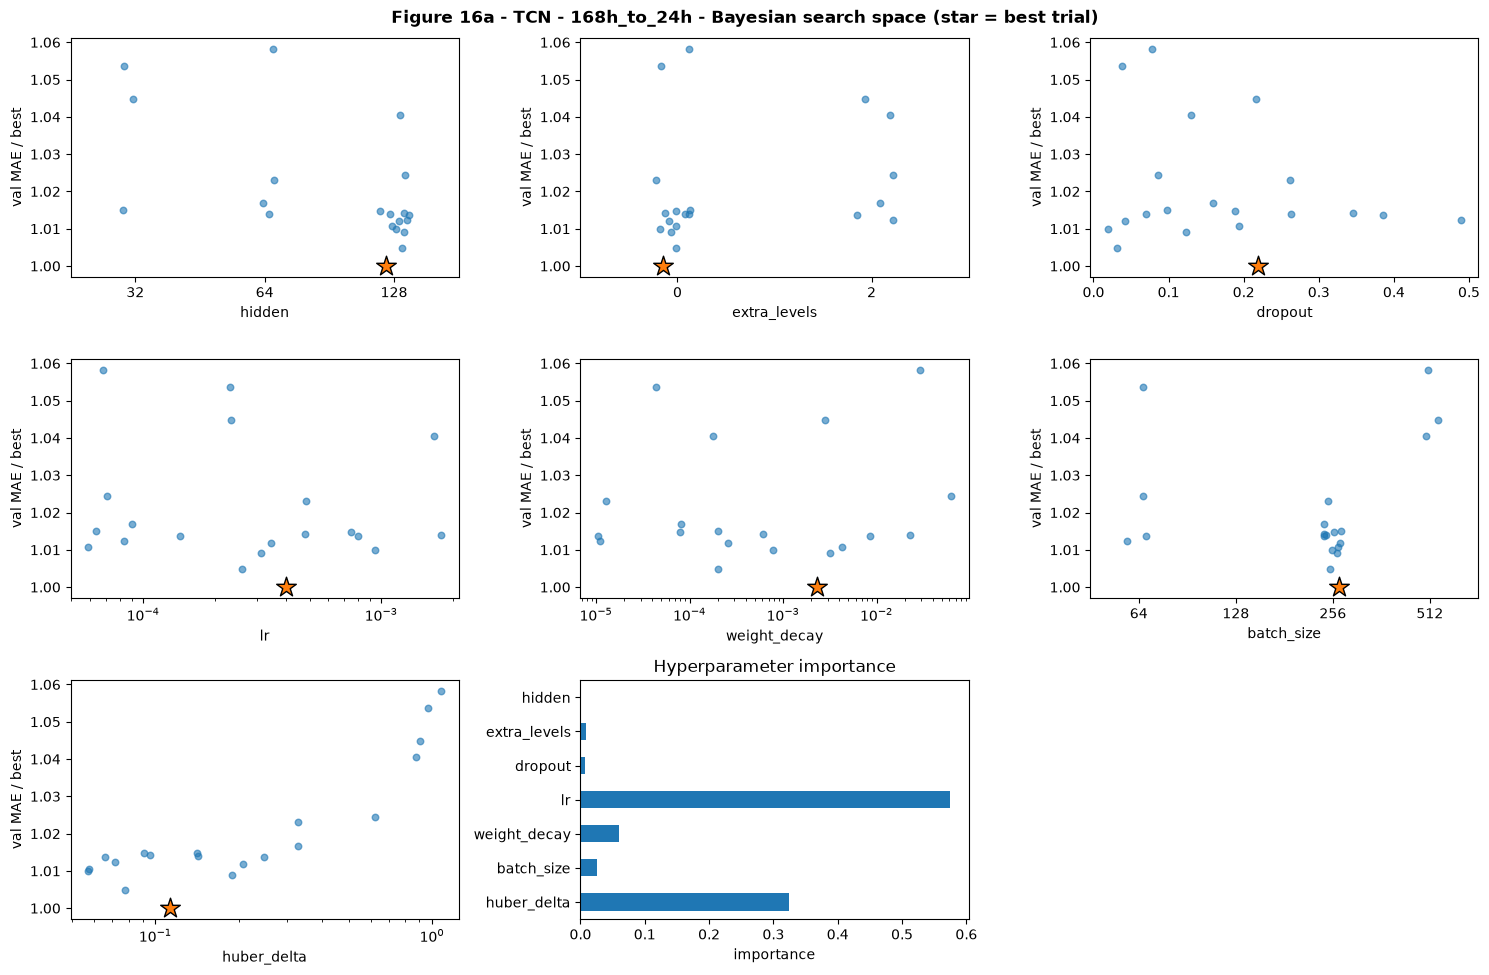

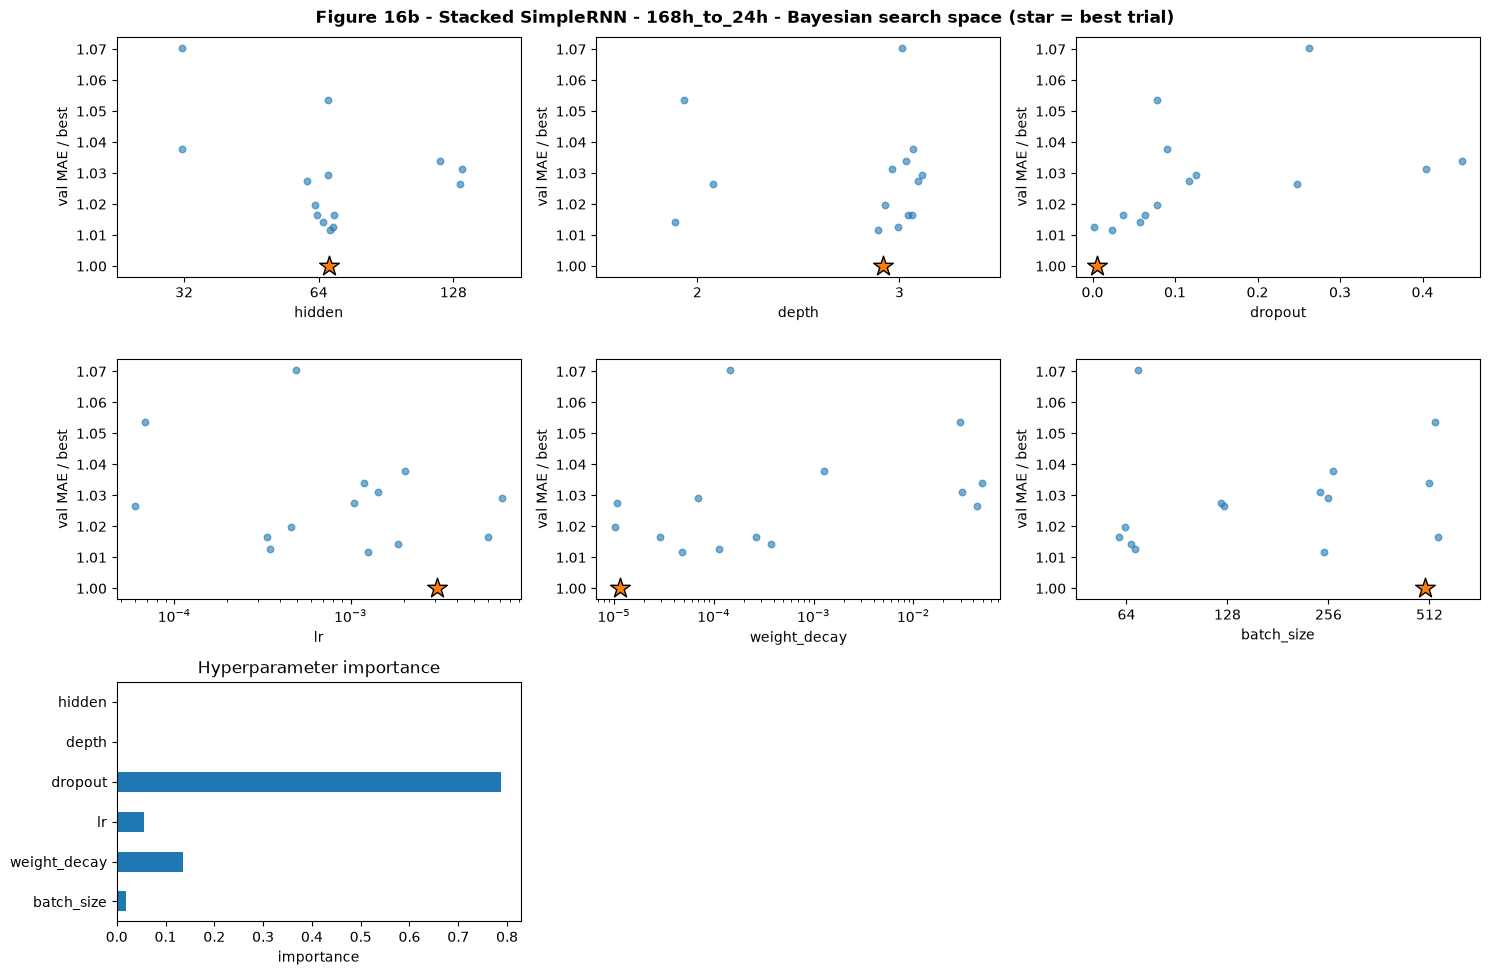

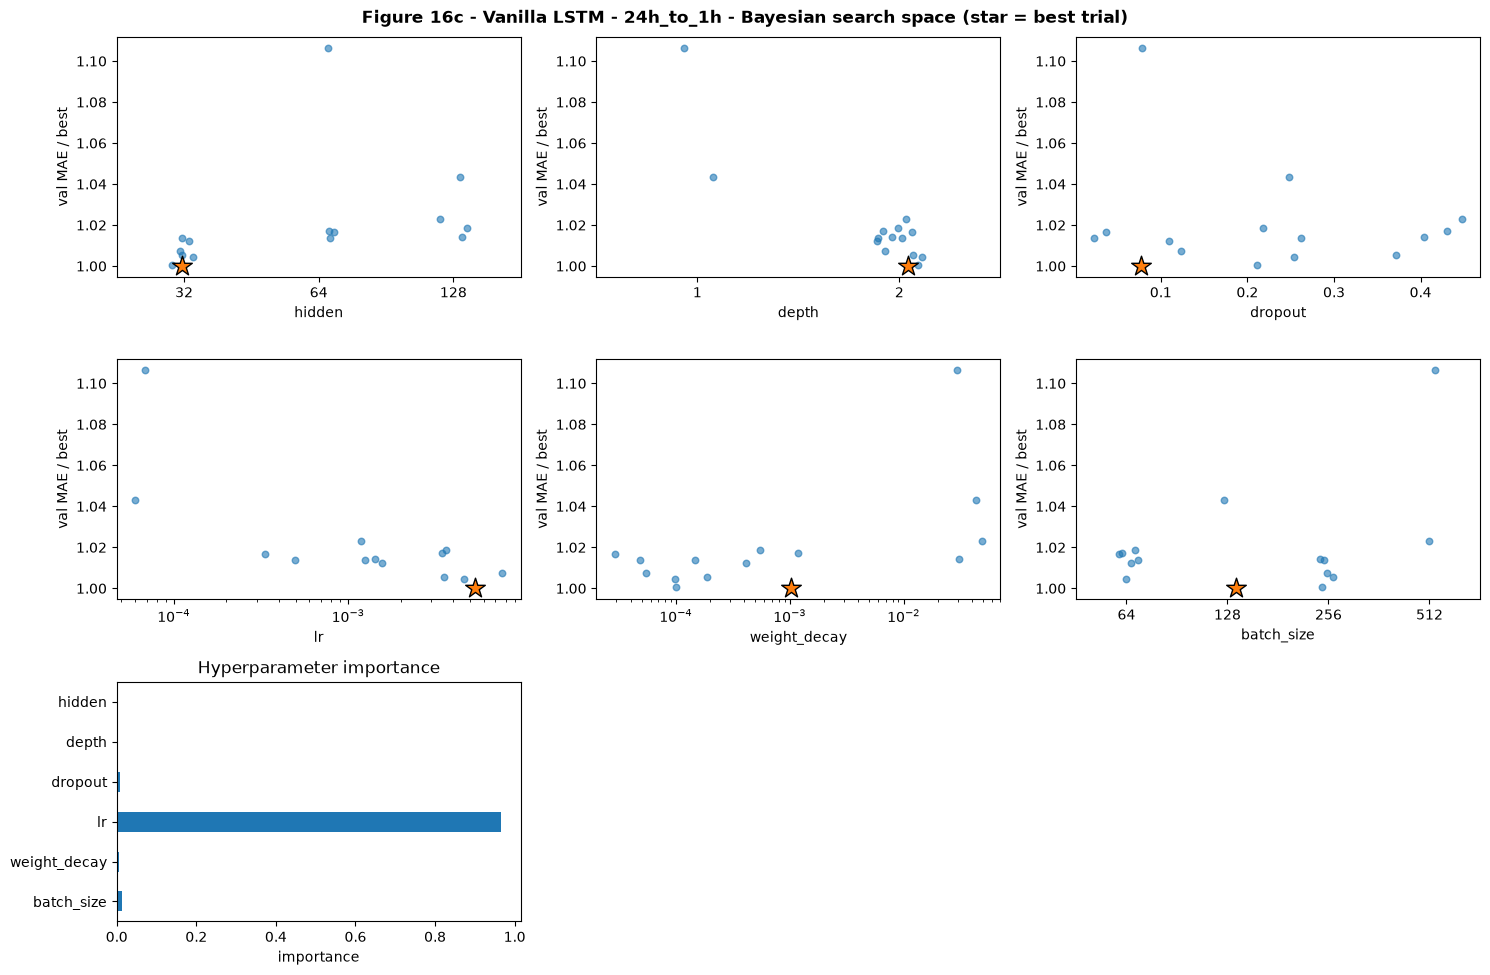

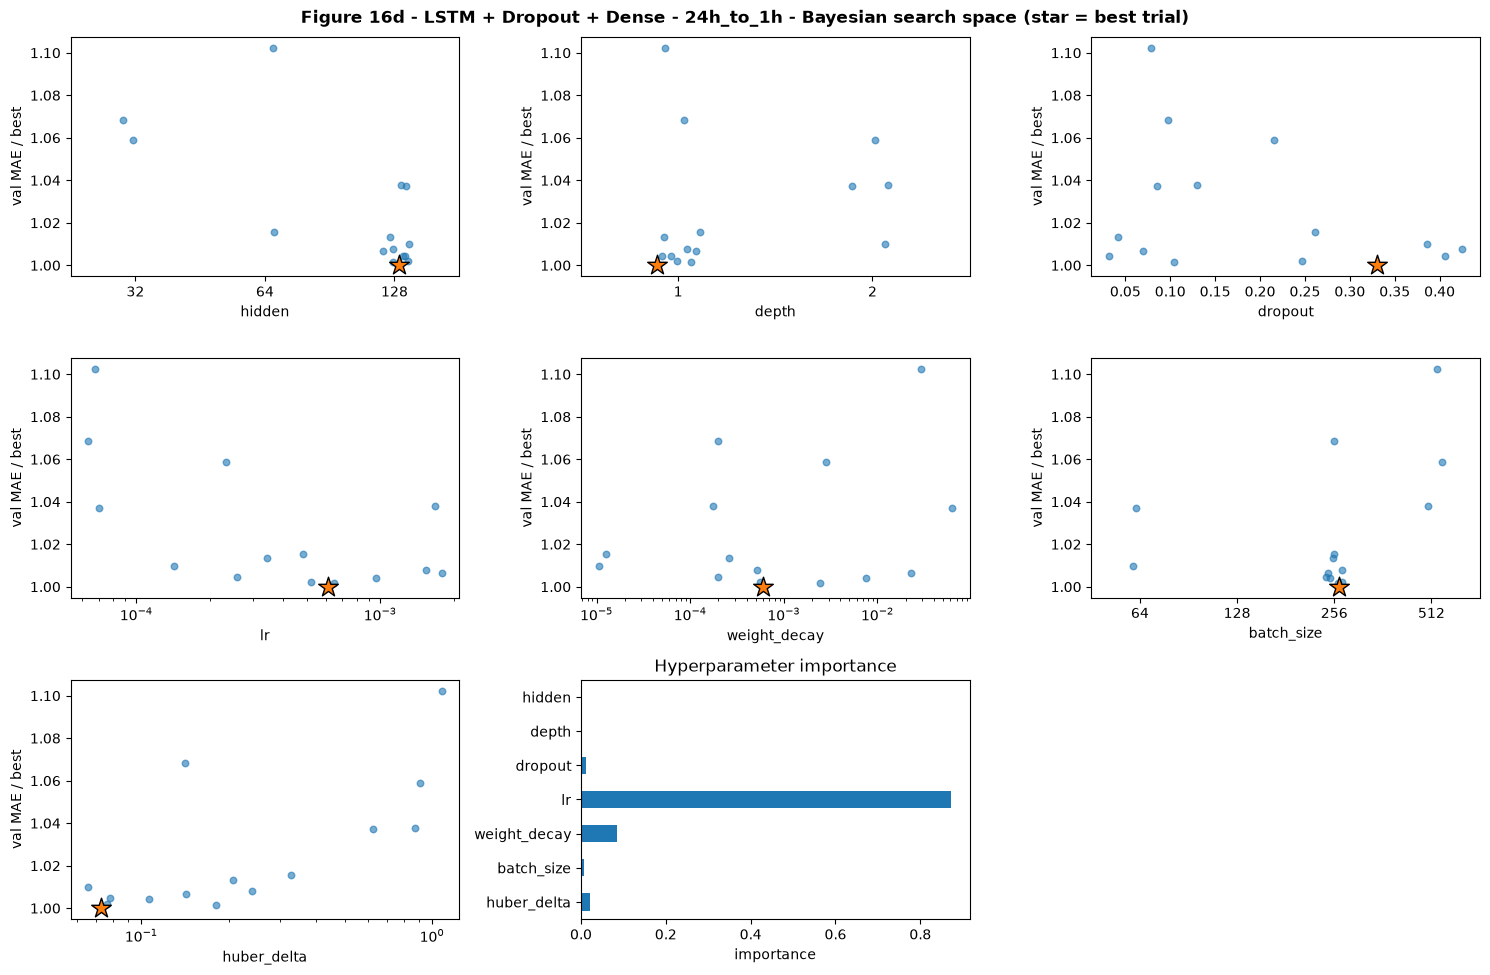

In [ ]:
if not stage2_ready:
    print('Stage 2 skipped')
else:
    best_s2 = {setup: min((n for n in stage2_names()[setup] if n.endswith('(tuned)')), key=lambda n: val_mae_of(setup, n))
               for setup in WINDOWS}
    figure_number(14)
    plot_curves(list(best_s2.items()), 'Best tuned Stage 2 model per setup')
    figure_number(15)
    plot_hpo_progress({setup: list(S2_FAMILIES) for setup in WINDOWS}, 'Stage 2 Bayesian HPO')
    figure_number(16, several=True)
    for setup in WINDOWS:
        for family in sorted(S2_FAMILIES, key=lambda f: val_mae_of(setup, f'{f} (tuned)'))[:2]:
            plot_search_space(setup, family)

## Further investigation to reduce error (validation)
With every Stage 1 and Stage 2 model trained, this section checks whether the validation error can be lowered further before anything is tested, and chooses the **selected model** that the test section adds. It uses **validation data only**: the test windows are only built in the test section at the end, after the choice is made.
1. **Percent error and smoothed GAP:** how large the errors are relative to the load, and whether the models follow the smooth level of the load and miss the spikes.
2. **Smoothed target:** the top models trained on an EWMA of GAP, then inverted back to GAP (a negative result; saved so it is not retrained on every run).
3. **Model cost:** size and inference time of every model.
4. **EWMA input features:** the top models retrained with long-memory EWMA inputs (saved, with refits).
5. **Ensembles:** the mean forecast of models already trained.
6. **Every option** (models, ensembles, EWMA-input models) on one error-vs-latency plot, the cost figures, and the selected model.

### Percent error and smoothed GAP
A check for whether the results can be improved further, using **validation only** (no test data), for the **top 3 validation models of each stage** in both setups.
* **Percent error** on measured hours, three ways: **MAPE** = mean(|a − p| / a), very sensitive to low-load night hours; **sMAPE** = mean(2|a − p| / (|a| + |p|)), bounded at 0–200%; **WAPE** = Σ|a − p| / Σa, which is MAE as a share of mean load.
* **Smoothed GAP:** a causal exponentially weighted moving average of actual GAP (each hour uses only that hour and earlier ones). Every metric is also computed against it. If the models score better against smoothed GAP than raw GAP, they are following the smooth level of the load and missing the short spikes.

In [ ]:
# Percent error of the top 3 validation models per stage, against raw GAP and a causal EWMA of GAP
EWM_SPAN = 6  # hours; alpha = 2 / (span + 1)
gap_smooth = pd.Series(gap).ewm(span=EWM_SPAN, adjust=False).mean().to_numpy()  # hour t uses hours <= t only

def pct_errors(actual, pred):
    """MAPE, sMAPE and WAPE in %."""
    err = np.abs(actual - pred)
    return {'MAPE %': 100 * (err / actual).mean(),
            'sMAPE %': 100 * (2 * err / (np.abs(actual) + np.abs(pred))).mean(),
            'WAPE %': 100 * err.sum() / actual.sum()}

top3 = {setup: {'Stage 1': STAGE1_MODELS[setup][:3],  # STAGE1_MODELS is in validation order
                'Stage 2': sorted(stage2_names()[setup], key=lambda n: val_mae_of(setup, n))[:3] if stage2_ready else []}
        for setup in WINDOWS}

for setup in WINDOWS:
    va = data[setup]['val']
    meas = va['measured']  # not `m`: that is the Holt-Winters season period
    actual, smooth = va['y_kw'][meas], gap_smooth[va['rows']][meas]
    assert (actual > 0).all(), 'MAPE needs positive actual GAP'
    table = pd.DataFrame({(stage, name): {**{f'raw {k}': v for k, v in pct_errors(actual, val_pred[setup][name][meas]).items()},
                                          **{f'smoothed {k}': v for k, v in pct_errors(smooth, val_pred[setup][name][meas]).items()}}
                          for stage, names in top3[setup].items() for name in names}).T
    print(f'Validation percent error - {setup} (measured hours; smoothed = EWMA span {EWM_SPAN} h)')
    display(table.round(2))


Validation percent error - 168h_to_24h (measured hours; smoothed = EWMA span 6 h)


raw MAPE %  raw sMAPE %  raw WAPE %  \
Stage 1 Gradient boosting               53.14        40.96       39.19   
        CNN (tuned)                     50.42        40.98       39.46   
        CNN                             49.96        41.08       39.72   
Stage 2 TCN (tuned)                     50.55        41.65       39.51   
        Stacked SimpleRNN (tuned)       51.46        41.46       39.85   
        TCN                             50.12        42.16       39.96   

                                   smoothed MAPE %  smoothed sMAPE %  \
Stage 1 Gradient boosting                    38.76             37.89   
        CNN (tuned)                          38.52             39.43   
        CNN                                  38.06             39.48   
Stage 2 TCN (tuned)                          39.48             40.90   
        Stacked SimpleRNN (tuned)            42.66             43.64   
        TCN                                  37.51             39.76   

                                   smoothed WAPE %  
Stage 1 Gradient boosting                    35.21  
        CNN (tuned)                          35.83  
        CNN                                  35.65  
Stage 2 TCN (tuned)                          36.70  
        Stacked SimpleRNN (tuned)            38.74  
        TCN                                  35.12

Validation percent error - 24h_to_1h (measured hours; smoothed = EWMA span 6 h)


raw MAPE %  raw sMAPE %  raw WAPE %  \
Stage 1 Gradient boosting                    34.58        29.16       28.77   
        MLP (tuned)                          34.13        30.39       29.98   
        MLP                                  33.53        30.95       30.40   
Stage 2 Vanilla LSTM (tuned)                 33.22        29.05       29.00   
        LSTM + Dropout + Dense               31.90        29.24       29.07   
        LSTM + Dropout + Dense (tuned)       32.39        29.51       29.13   

                                        smoothed MAPE %  smoothed sMAPE %  \
Stage 1 Gradient boosting                         32.86             34.93   
        MLP (tuned)                               34.09             36.96   
        MLP                                       34.73             38.50   
Stage 2 Vanilla LSTM (tuned)                      34.69             36.73   
        LSTM + Dropout + Dense                    33.71             37.47   
        LSTM + Dropout + Dense (tuned)            35.24             38.91   

                                        smoothed WAPE %  
Stage 1 Gradient boosting                         30.15  
        MLP (tuned)                               31.74  
        MLP                                       32.70  
Stage 2 Vanilla LSTM (tuned)                      31.89  
        LSTM + Dropout + Dense                    31.14  
        LSTM + Dropout + Dense (tuned)            32.53

#### Smoothed GAP vs predictions (validation, 1 week; Figure 17)
One graph per stage, with both setups. The forecasts are placed back to back over a fully measured validation week (Monday to Sunday), as in the test forecast plots: grey is actual GAP, black is the EWMA-smoothed GAP, and the colored lines are the top 3 models of that stage.

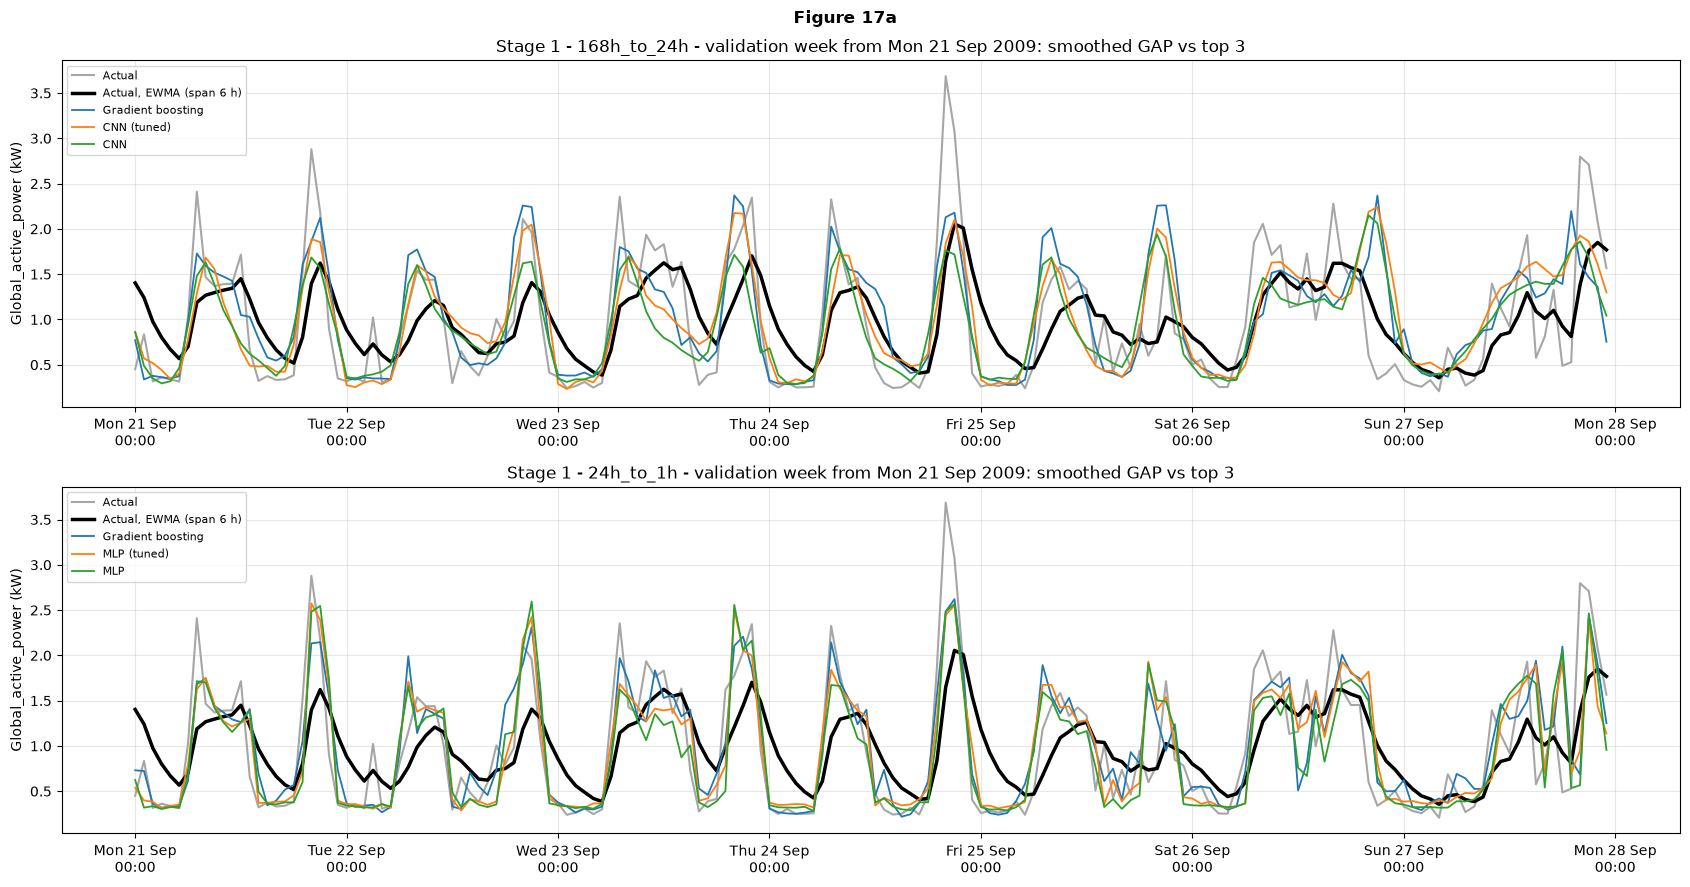

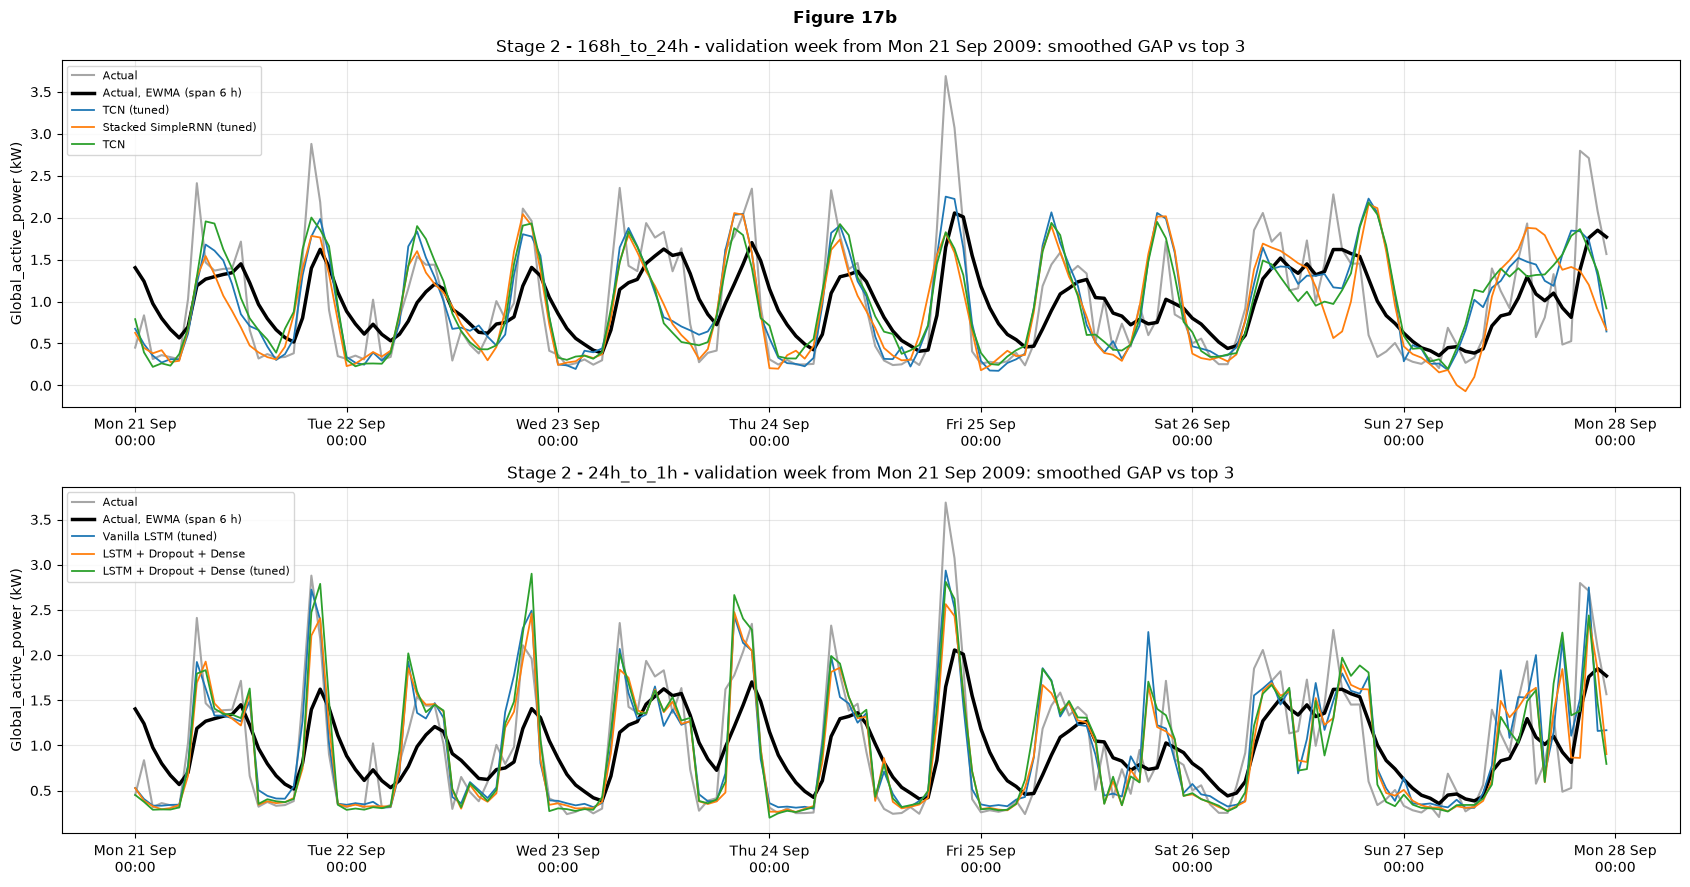

In [ ]:
import matplotlib.dates as mdates

def span_start(frac, days, weekday, split='test'):
    """First midnight on `weekday` at or after `frac` of a split whose next `days` days are all measured."""
    a, b = splits[split]
    for pos in range(a + int(frac * (b - a)), b - days * 24):
        ts = features.index[pos]
        if ts.hour == 0 and ts.day_of_week == weekday and measured_all[pos:pos + days * 24].all():
            return pos
    raise ValueError(f'no fully measured {days}-day span in the {split} split')

def back_to_back(setup, values, pos, days, split='test'):
    """Hours and values of the non-overlapping forecasts of a split that start at row `pos` and cover `days` days."""
    d, horizon = data[setup][split], WINDOWS[setup]['horizon']
    i = np.flatnonzero(d['t'] == pos)[0] + horizon * np.arange(days * 24 // horizon)
    return features.index[d['rows'][i].ravel()], values[i].ravel()

val_week = span_start(0.5, 7, weekday=0, split='val')  # the first fully measured Monday from mid-validation
figure_number(17, several=True)  # a: Stage 1, b: Stage 2
for stage in ('Stage 1', 'Stage 2'):
    if not any(top3[setup][stage] for setup in WINDOWS):
        print(f'{stage} skipped')
        continue
    fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(17, 4.5 * len(WINDOWS)))
    for ax, setup in zip(axes, WINDOWS):
        va = data[setup]['val']
        hours, actual = back_to_back(setup, va['y_kw'], val_week, 7, split='val')
        ax.plot(hours, actual, color='0.65', lw=1.5, label='Actual')
        ax.plot(hours, back_to_back(setup, gap_smooth[va['rows']], val_week, 7, split='val')[1], 'k', lw=2.5,
                label=f'Actual, EWMA (span {EWM_SPAN} h)')
        for name in top3[setup][stage]:
            ax.plot(*back_to_back(setup, val_pred[setup][name], val_week, 7, split='val'), lw=1.3, label=name)
        ax.set(ylabel='Global_active_power (kW)',
               title=f'{stage} - {setup} - validation week from {hours[0]:%a %d %b %Y}: smoothed GAP vs top 3')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b\n%H:%M'))
        ax.legend(fontsize=8, loc='upper left')
        ax.grid(alpha=0.3)
    plt.tight_layout()
    show()


### Train on smoothed GAP, then invert back to GAP
The **top 5 validation models of each setup** (across both stages; baselines excluded, since they are not trained) are retrained with the **same hyperparameters** to forecast a causal EWMA of GAP instead of GAP itself. Their forecasts are then inverted back to GAP and scored on the same validation windows as the originals.
* **Smoothing:** sₜ = α·xₜ + (1 − α)·sₜ₋₁ with α = 2 / (span + 1); each hour uses only that hour and earlier ones.
* **Inversion:** xₜ = (sₜ − (1 − α)·sₜ₋₁) / α. The smoothed value just before the first forecast hour is known (built from past actual hours); later hours of a 24 h forecast use the previous forecast hour, so errors can carry from one hour to the next.
* **Training:** networks use `fit()` with their selected loss and settings, early-stopped on validation MAE against smoothed GAP; Ridge and gradient boosting reuse their selected alpha / trees and round count.
* **Saved:** the retrained models go into `models/combined/stage2.pkl` (key `smooth_models`) and are loaded from it on later runs, unless `TrainStage2 = True` or the top 5 have changed. The original models and targets are left unchanged.

In [ ]:
# Retrain the top 5 validation models of each setup on a causal EWMA of GAP (same hyperparameters), or load them
EWM_ALPHA = 2 / (EWM_SPAN + 1)  # EWM_SPAN and gap_smooth are set in the percent-error cell above
TOP_N = 5

def smoothed_target(d):
    """Window dict d with the training target 'y' swapped for scaled smoothed GAP ('y_kw' stays raw GAP)."""
    return {**d, 'y': ((gap_smooth[d['rows']] - mu[TARGET]) / sd[TARGET]).astype(np.float32)}

def unsmooth(d, pred_smooth):
    """GAP from smoothed forecasts: x_t = (s_t - (1 - alpha) * s_(t-1)) / alpha. s just before the first forecast
    hour is known from past actual hours; later forecast hours use the previous forecast hour."""
    prev = np.hstack([gap_smooth[d['t'] - 1, None], pred_smooth[:, :-1]])
    return (pred_smooth - (1 - EWM_ALPHA) * prev) / EWM_ALPHA

for setup in WINDOWS:  # inverting the actual smoothed GAP must give back the actual GAP
    va = data[setup]['val']
    assert np.allclose(unsmooth(va, gap_smooth[va['rows']]), va['y_kw'])

def top_trained(setup, n):
    """The n trained models (baselines excluded) with the lowest validation MAE."""
    return sorted((m for m in val_pred[setup] if m in nn_models[setup] or m in fitted[setup]),
                  key=lambda m: val_mae_of(setup, m))[:n]

def retrain_variant(key, top, swap, n_features=None):
    """The `top` models of each setup (setup -> names) retrained with their selected hyperparameters on windows
    changed by swap(setup, d), or loaded from the Stage 2 checkpoint under `key` when it holds the same models.
    n_features: input width of the changed windows (default: unchanged). fit() reads its windows from data[setup] and
    the model classes read N_FEATURES, so both are swapped here and restored afterwards.
    Returns (setup -> name -> {'model', 'history', 'pred', 'val MAE', 'refit'}, whether they were loaded): 'pred' is the
    validation forecast (kW) and 'val MAE' its MAE against GAP on measured hours."""
    global N_FEATURES
    saved = load_checkpoint(STAGE2_CKPT, 'TrainStage2').get(key) if stage2_ready else None
    if saved is not None and any(set(saved[s]) != set(top[s]) for s in WINDOWS):
        print(f'{key}: the top models changed since they were saved - retraining them')
        saved = None
    base_features, out = N_FEATURES, {setup: {} for setup in WINDOWS}
    for setup in WINDOWS:
        raw = {s: data[setup][s] for s in ('train', 'val')}
        data[setup].update({s: swap(setup, d) for s, d in raw.items()})
        N_FEATURES = n_features or base_features
        try:
            va = data[setup]['val']
            for name in top[setup]:
                start = time.perf_counter()
                if saved is None:
                    (model, history), refit = retrain(setup, name, data[setup]['train']), None
                else:
                    entry = saved[setup][name]
                    model, history = unpack_model(setup, name, entry['model']), entry['history']
                    refit = unpack_model(setup, name, entry['refit'])
                pred = forecast(model, va)
                mae = evaluate(va, pred)['MAE']
                if saved is not None:  # a loaded model must score as it did when it was saved
                    assert np.isclose(mae, saved[setup][name]['val MAE'], atol=1e-5), \
                        f'{key} {setup} {name}: the loaded model scores differently on validation'
                out[setup][name] = {'model': model, 'history': history, 'pred': pred, 'val MAE': mae, 'refit': refit}
                print(f'{setup}: {name} ({"loaded" if saved else f"{time.perf_counter() - start:.1f} s to train"})',
                      flush=True)
        finally:
            data[setup].update(raw)  # put the original windows back for every other cell
            N_FEATURES = base_features
    return out, saved is not None

def save_variant(key, results):
    """Add retrained models (and their refits, if any) to the Stage 2 checkpoint under `key`."""
    if not stage2_ready:
        print(f'{STAGE2_CKPT} does not exist: {key} is not saved')
        return
    update_checkpoint(STAGE2_CKPT, 'TrainStage2', **{key: {
        setup: {name: {'model': pack_model(r['model']), 'refit': pack_model(r['refit']), 'history': r['history'],
                       'val MAE': r['val MAE']} for name, r in models.items()}
        for setup, models in results.items()}})

smooth_top = {setup: top_trained(setup, TOP_N) for setup in WINDOWS}
smooth_models, smooth_loaded = retrain_variant('smooth_models', smooth_top, lambda setup, d: smoothed_target(d))
if not smooth_loaded:
    save_variant('smooth_models', smooth_models)
smooth_pred = {setup: {name: r['pred'] for name, r in models.items()} for setup, models in smooth_models.items()}


168h_to_24h: Gradient boosting (loaded)
168h_to_24h: CNN (tuned) (loaded)
168h_to_24h: TCN (tuned) (loaded)
168h_to_24h: CNN (loaded)
168h_to_24h: MLP (loaded)
24h_to_1h: Gradient boosting (loaded)
24h_to_1h: Vanilla LSTM (tuned) (loaded)
24h_to_1h: LSTM + Dropout + Dense (loaded)
24h_to_1h: LSTM + Dropout + Dense (tuned) (loaded)
24h_to_1h: Stacked LSTM (tuned) (loaded)


Validation (kW, measured hours) - 168h_to_24h - top 5 models, EWMA span 6 h


,trained on GAP: MAE,smoothed + inverted: MAE,trained on GAP: RMSE,smoothed + inverted: RMSE,smoothed model vs smoothed GAP: MAE,MAE change (%)
Gradient boosting,0.4139,0.4614,0.5999,0.6440,0.2556,11.4768
CNN (tuned),0.4168,0.4439,0.6092,0.6206,0.2552,6.5041
TCN (tuned),0.4173,0.5141,0.6086,0.6909,0.2642,23.1902
CNN,0.4195,0.4467,0.6136,0.6215,0.2584,6.4726
MLP,0.4209,0.4476,0.6217,0.6337,0.2615,6.3430


Validation (kW, measured hours) - 24h_to_1h - top 5 models, EWMA span 6 h


,trained on GAP: MAE,smoothed + inverted: MAE,trained on GAP: RMSE,smoothed + inverted: RMSE,smoothed model vs smoothed GAP: MAE,MAE change (%)
Gradient boosting,0.3039,0.3384,0.4672,0.4918,0.0967,11.3470
Vanilla LSTM (tuned),0.3064,0.3249,0.4768,0.4872,0.0928,6.0381
LSTM + Dropout + Dense,0.3071,0.3230,0.4795,0.4852,0.0923,5.1804
LSTM + Dropout + Dense (tuned),0.3077,0.3194,0.4795,0.4882,0.0913,3.7922
Stacked LSTM (tuned),0.3094,0.3321,0.4775,0.4885,0.0949,7.3282


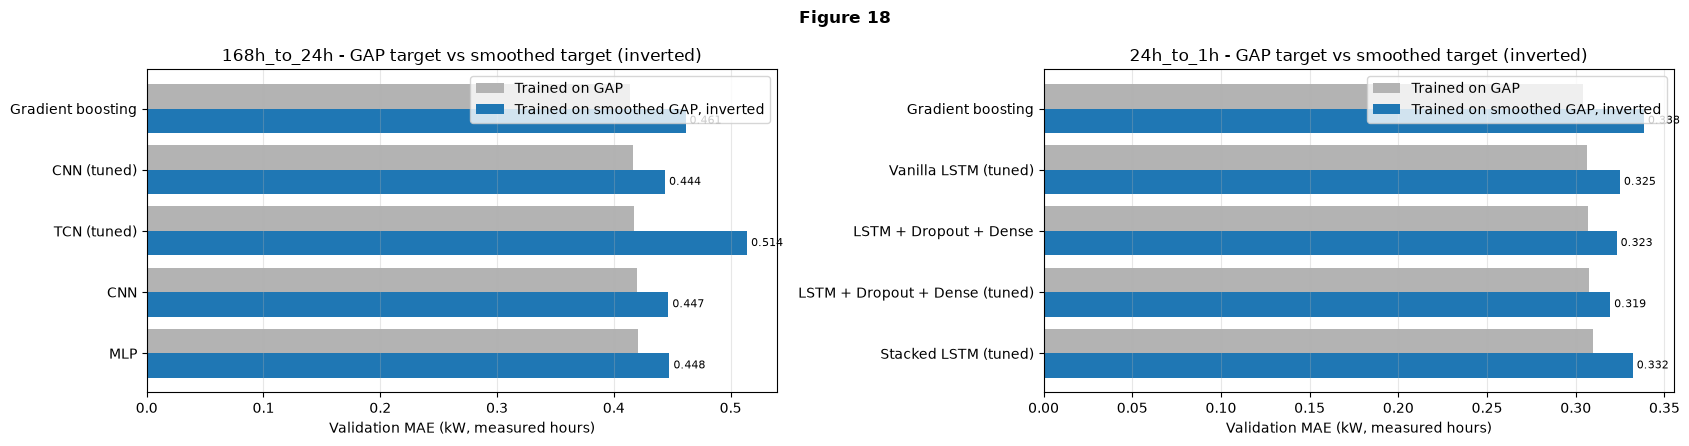

In [ ]:
# Same validation windows, measured hours: trained on GAP vs trained on smoothed GAP and inverted
smooth_tables = {}
for setup in WINDOWS:
    va, names = data[setup]['val'], smooth_top[setup]
    on_gap = {n: evaluate(va, val_pred[setup][n]) for n in names}
    inverted = {n: evaluate(va, unsmooth(va, smooth_pred[setup][n])) for n in names}
    table = pd.DataFrame({
        'trained on GAP: MAE': {n: on_gap[n]['MAE'] for n in names},
        'smoothed + inverted: MAE': {n: inverted[n]['MAE'] for n in names},
        'trained on GAP: RMSE': {n: on_gap[n]['RMSE'] for n in names},
        'smoothed + inverted: RMSE': {n: inverted[n]['RMSE'] for n in names},
        'smoothed model vs smoothed GAP: MAE': {n: np.abs(smooth_pred[setup][n] - gap_smooth[va['rows']])[va['measured']].mean()
                                                for n in names}})
    table['MAE change (%)'] = 100 * (table['smoothed + inverted: MAE'] / table['trained on GAP: MAE'] - 1)
    smooth_tables[setup] = table
    print(f'Validation (kW, measured hours) - {setup} - top {TOP_N} models, EWMA span {EWM_SPAN} h')
    display(table.round(4))

fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 4.5))
for ax, (setup, table) in zip(axes, smooth_tables.items()):
    hbar_pair(ax, table.index, table['trained on GAP: MAE'], table['smoothed + inverted: MAE'],
              ('Trained on GAP', 'Trained on smoothed GAP, inverted'), ('0.7', 'C0'))
    ax.set(xlabel='Validation MAE (kW, measured hours)', title=f'{setup} - GAP target vs smoothed target (inverted)')
plt.tight_layout()
show(18)


**Result (Figure 18):** in the run shown, training on smoothed GAP and inverting it is worse for every model in both setups (validation MAE about 4-23 % higher). The smoothed models follow smoothed GAP closely, but inverting the EWMA multiplies their errors by 1/α (3.5 for a 6 h span) and carries them from one forecast hour to the next. Smoothing the target is therefore dropped; these models are not candidates for the selected model.

### Model cost: accuracy vs size vs inference time (Figure 19)
Every trained model of both stages (refits excluded), in both setups. All three measures use **validation data only**:
* **Accuracy:** validation MAE (kW, measured hours), the selection metric.
* **Size:** trainable values: network parameters, Ridge coefficients, XGBoost tree nodes, or lookup-table entries (weekly profiles; Holt-Winters' four smoothing parameters and 168 seasonal states). Seasonal naive has none.
* **Inference time:** after a warm-up call, the time per 1,000 windows (batches of 1,024, repeated 3 times) and the median latency of one-window forecasts (200 calls), which is how a deployed forecaster runs. Every model is timed in the same run on the same device; GPU calls are synchronised so the time includes the work, not just the launch.

The dashed step line is the **Pareto front**: models that no other model beats on both axes. Anything above it is both larger (or slower) and less accurate than some alternative. Both x axes are logarithmic; a size of 0 is drawn at 1.

In [ ]:
# Cost of every model on validation windows: size, inference time and validation MAE (no test data)
TIMING_BATCH, TIMING_REPEATS, SINGLE_CALLS = 1024, 3, 200
SIZE_FLOOR = 1  # log axis: seasonal naive (size 0) is drawn at 1
FIXED_SIZES = {'Seasonal naive (week)': 0, 'Weekly profile': WEEK, 'Seasonal weekly profile': 4 * WEEK,
               'Holt-Winters': 4 + WEEK}  # smoothing parameters + one seasonal state per hour of the week

def model_size(setup, name):
    """Trainable values: network parameters, Ridge coefficients, XGBoost tree nodes or lookup-table entries."""
    if name in FIXED_SIZES:
        return FIXED_SIZES[name]
    if name == 'Ridge':
        return fitted[setup][name].coef_.size + np.size(fitted[setup][name].intercept_)
    if name == 'Gradient boosting':
        return len(fitted[setup][name].trees_to_dataframe())
    return count_params(nn_models[setup][name])

def take(d, a, b):
    """Windows a..b-1 of a window dict."""
    return {k: v[a:b] for k, v in d.items()}

def run_synced(predict, windows):
    predict(windows)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # wait for the GPU, so the time includes the work and not just the launch

def single_window_ms(predict, d):
    """Median latency (ms) of SINGLE_CALLS one-window calls predict(windows), after a warm-up call."""
    run_synced(predict, take(d, 0, 1))  # warm-up
    times = []
    for i in range(SINGLE_CALLS):
        start = time.perf_counter()
        run_synced(predict, take(d, i, i + 1))
        times.append((time.perf_counter() - start) * 1e3)
    return float(np.median(times))

def inference_times(setup, name):
    """ms per 1,000 windows (batches of TIMING_BATCH) and the median single-window latency in ms."""
    va, predict = data[setup]['val'], lambda windows: model_forecast(setup, name, windows)
    run_synced(predict, take(va, 0, TIMING_BATCH))  # warm-up
    start = time.perf_counter()
    for _ in range(TIMING_REPEATS):
        run_synced(predict, take(va, 0, TIMING_BATCH))
    per_1000 = (time.perf_counter() - start) / (TIMING_REPEATS * TIMING_BATCH) * 1e6  # s per window -> ms per 1,000
    return per_1000, single_window_ms(predict, va)

cost_rows = []
for setup in WINDOWS:
    for name in val_pred[setup]:
        per_1000, single = inference_times(setup, name)
        cost_rows.append({'setup': setup, 'model': name, 'stage': stage_of(name), 'val MAE': val_mae_of(setup, name),
                          'size': model_size(setup, name), 'ms per 1,000 windows': per_1000, 'single-window ms': single})
cost = pd.DataFrame(cost_rows).set_index(['setup', 'model']).sort_values(['setup', 'val MAE'])
display(cost.round(4))

stage  val MAE    size  \
setup       model                                                       
168h_to_24h Gradient boosting               Baseline   0.4139  450000   
            CNN (tuned)                      Stage 1   0.4168   12944   
            TCN (tuned)                      Stage 2   0.4173  824472   
            CNN                              Stage 1   0.4195   10032   
            MLP                              Stage 1   0.4209  218264   
            Stacked SimpleRNN (tuned)        Stage 2   0.4210   11352   
            TCN                              Stage 2   0.4221  211544   
            Stacked GRU (tuned)              Stage 2   0.4246   95256   
            Bidirectional LSTM (tuned)       Stage 2   0.4246   45592   
            Vanilla LSTM (tuned)             Stage 2   0.4275   78360   
            LSTM + Dropout + Dense (tuned)   Stage 2   0.4277   85080   
            LSTM + Dropout + Dense           Stage 2   0.4306   24120   
            Stacked LSTM (tuned)             Stage 2   0.4311  159768   
            Vanilla LSTM                     Stage 2   0.4314   22808   
            Stacked GRU                      Stage 2   0.4323   26136   
            Bidirectional LSTM               Stage 2   0.4325   14616   
            Stacked SimpleRNN                Stage 2   0.4338    9240   
            Stacked LSTM                     Stage 2   0.4375   34584   
            Ridge                           Baseline   0.4433   68568   
            Seasonal weekly profile         Baseline   0.4489     672   
            Weekly profile                  Baseline   0.5149     168   
            Seasonal naive (week)           Baseline   0.5310       0   
            Holt-Winters                    Baseline   0.6502     172   
24h_to_1h   Gradient boosting               Baseline   0.3039   31250   
            Vanilla LSTM (tuned)             Stage 2   0.3064    9745   
            LSTM + Dropout + Dense           Stage 2   0.3071   23361   
            LSTM + Dropout + Dense (tuned)   Stage 2   0.3077   83585   
            Stacked LSTM (tuned)             Stage 2   0.3094  124993   
            Stacked GRU                      Stage 2   0.3096   25377   
            Stacked GRU (tuned)              Stage 2   0.3100   93761   
            Vanilla LSTM                     Stage 2   0.3115   21313   
            Stacked LSTM                     Stage 2   0.3121   33825   
            TCN (tuned)                      Stage 2   0.3135   95105   
            Bidirectional LSTM (tuned)       Stage 2   0.3144   84033   
            Stacked SimpleRNN (tuned)        Stage 2   0.3145   31297   
            TCN                              Stage 2   0.3153   95105   
            Bidirectional LSTM               Stage 2   0.3161   13121   
            MLP (tuned)                      Stage 1   0.3167   34945   
            Stacked SimpleRNN                Stage 2   0.3197    8481   
            MLP                              Stage 1   0.3212   60097   
            CNN                              Stage 1   0.3233    8146   
            Ridge                           Baseline   0.3704     409   
            Holt-Winters                    Baseline   0.4013     172   
            Seasonal weekly profile         Baseline   0.4485     672   
            Weekly profile                  Baseline   0.5144     168   
            Seasonal naive (week)           Baseline   0.5315       0   

                                            ms per 1,000 windows  \
setup       model                                                  
168h_to_24h Gradient boosting                             8.1971   
            CNN (tuned)                                   5.7275   
            TCN (tuned)                                  46.2637   
            CNN                                           4.8269   
            MLP                                           2.0039   
            Stacked SimpleRNN (tuned)                     3.7456  

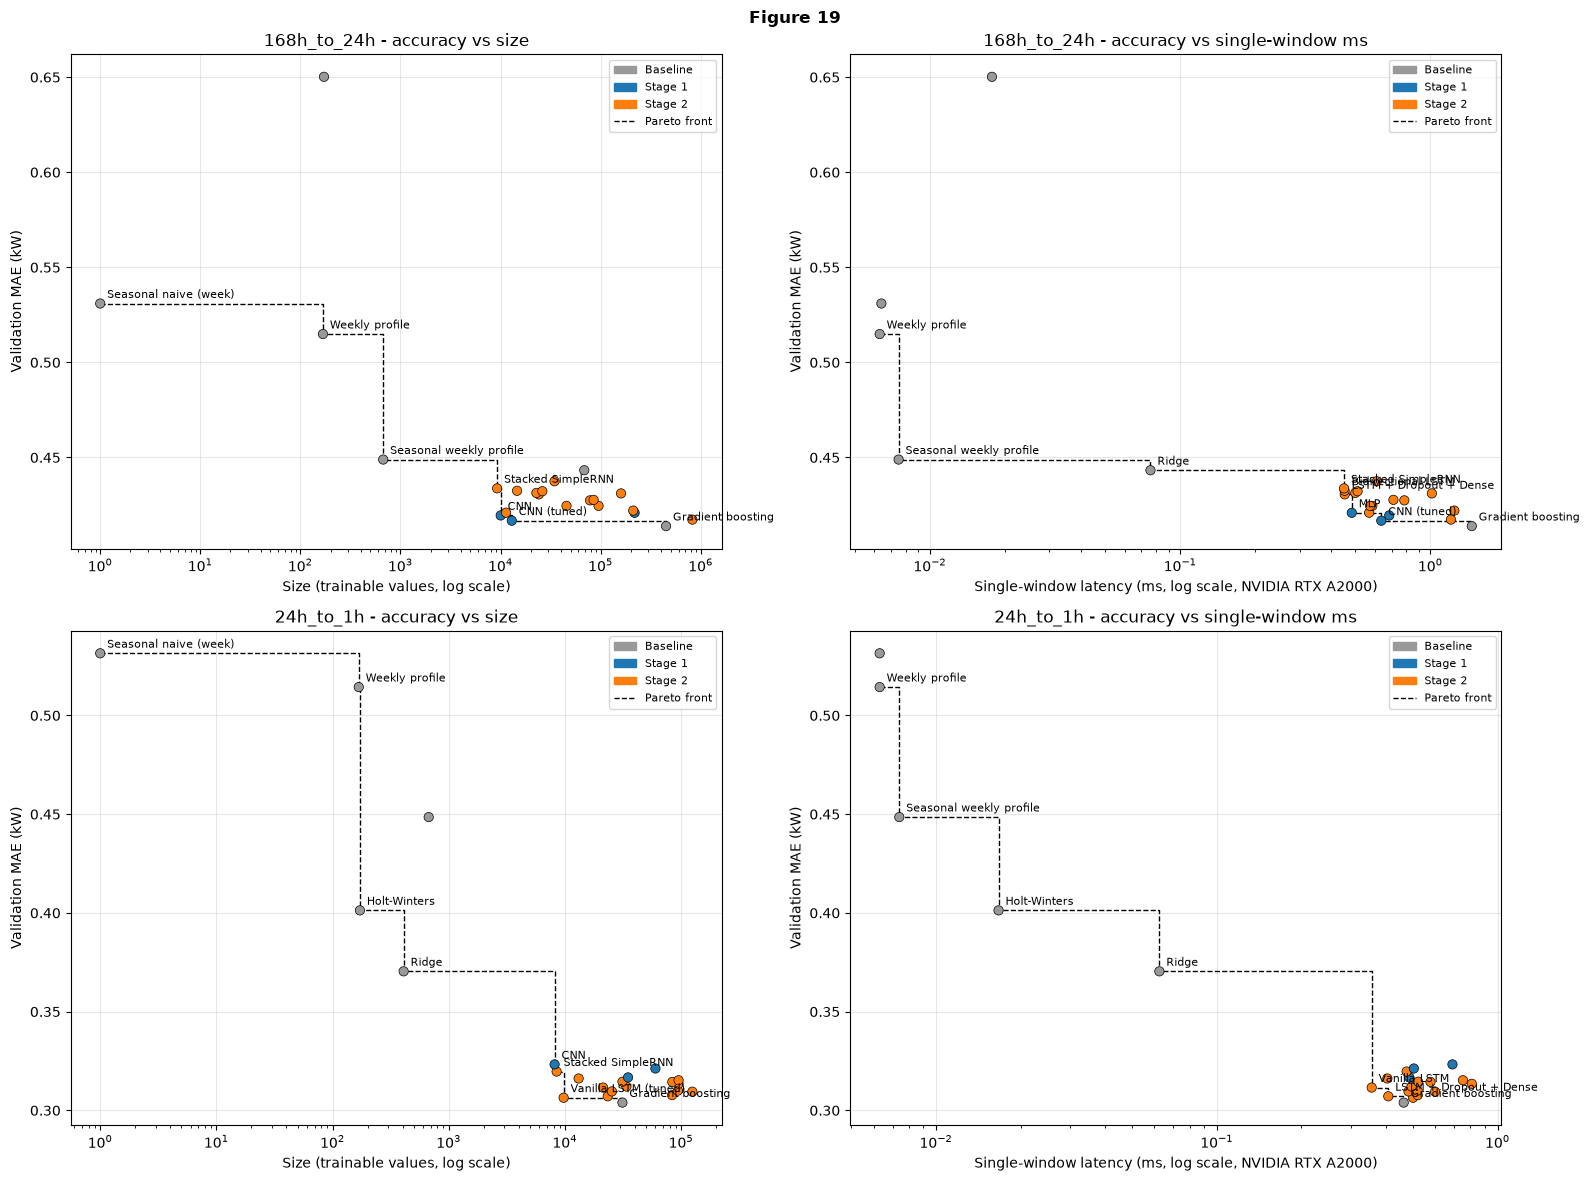

In [ ]:
def pareto_front(x, y):
    """Indices of the models no other model beats on both axes (lower x and lower y), in increasing x."""
    front, best = [], np.inf
    for i in np.argsort(x, kind='stable'):
        if y[i] < best:
            front.append(i)
            best = y[i]
    return front

device_name = torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'
legend = [*(Patch(color=c, label=s) for s, c in STAGE_COLORS.items()),
          Line2D([], [], color='k', ls='--', lw=1, label='Pareto front')]
fig, axes = plt.subplots(len(WINDOWS), 2, figsize=(16, 6 * len(WINDOWS)), squeeze=False)
for row, setup in zip(axes, WINDOWS):
    setup_cost = cost.loc[setup]
    for ax, column, xlabel in ((row[0], 'size', 'Size (trainable values, log scale)'),
                               (row[1], 'single-window ms', f'Single-window latency (ms, log scale, {device_name})')):
        x, y = setup_cost[column].to_numpy(float), setup_cost['val MAE'].to_numpy()
        if column == 'size':
            x = np.maximum(x, SIZE_FLOOR)
        ax.scatter(x, y, s=45, c=[STAGE_COLORS[stage] for stage in setup_cost['stage']], edgecolor='k', linewidth=0.5,
                   zorder=3)
        front = pareto_front(x, y)
        ax.step(x[front], y[front], where='post', color='k', ls='--', lw=1)
        for i in front:
            ax.annotate(setup_cost.index[i], (x[i], y[i]), textcoords='offset points', xytext=(5, 4), fontsize=8)
        ax.set(xscale='log', xlabel=xlabel, ylabel='Validation MAE (kW)', title=f'{setup} - accuracy vs {column}')
        ax.grid(alpha=0.3)
        ax.legend(handles=legend, fontsize=8, loc='upper right')
plt.tight_layout()
show(19)

### EWMA-of-GAP input features
The **top 5 trained models of each setup** (baselines excluded) are retrained with the **same hyperparameters** and three extra input columns: causal EWMAs of GAP with spans of about a day, a week and a month (`EWM_FEATURE_SPANS`). The target stays raw GAP, so nothing has to be inverted.
* **Why it can help:** the EWMA at hour t−1 summarises the load from long before the lookback window (most useful for the 24 h lookback), and gives tree models a ready-made level to split on.
* **No leakage:** the EWMA at row i uses only hours up to i, inputs end at hour t−1 (asserted), and the extra columns are scaled with training rows only.
* **Latency:** measured the same way as the cost section (median of `SINGLE_CALLS` single-window forecasts). In deployment the EWMAs are one multiply-add per hour, so they add nothing measurable.
* The training windows and `N_FEATURES` are swapped only inside the cell and restored afterwards.
* **Saved:** the models go into `models/combined/stage2.pkl` (key `ewm_models`) and are loaded from it on later runs, unless `TrainStage2 = True` or the top 5 have changed. As with the original models, the best `S2_REFITS` (2) per setup on validation are also refitted on train + validation, so they can be compared fairly in the test.

In [ ]:
# Retrain the top 5 trained models of each setup with EWMA-of-GAP input features (same hyperparameters), or load them
EWM_FEATURE_SPANS = (24, 168, 720)  # hours: about a day, a week and a month of memory
EWM_TOP = 5
N_BASE, X_base = X_all.shape[1], X_all
ewm_raw = np.column_stack([pd.Series(gap).ewm(span=s, adjust=False).mean().to_numpy()
                           for s in EWM_FEATURE_SPANS])  # row i uses hours <= i only
ewm_scaled = (ewm_raw - ewm_raw[:train_end].mean(0)) / ewm_raw[:train_end].std(0)  # train-only scaling
X_ewm = np.hstack([X_all, ewm_scaled]).astype(np.float32)

def with_ewm_inputs(d, lookback):
    """Window dict d with inputs rebuilt from X_ewm: the same rows t-lookback..t-1, targets unchanged."""
    X = np.stack([X_ewm[i - lookback:i] for i in d['t']])
    assert np.array_equal(X[..., :N_BASE], d['X'])  # same inputs as before, plus the EWMA columns
    return {**d, 'X': X}

ewm_top = {setup: top_trained(setup, EWM_TOP) for setup in WINDOWS}
ewm_results, ewm_loaded = retrain_variant('ewm_models', ewm_top,
                                          lambda setup, d: with_ewm_inputs(d, WINDOWS[setup]['lookback']),
                                          n_features=X_ewm.shape[1])
for setup in WINDOWS:  # latency timed like the cost section
    va = with_ewm_inputs(data[setup]['val'], WINDOWS[setup]['lookback'])
    for name, r in ewm_results[setup].items():
        r['single-window ms'] = single_window_ms(lambda windows: forecast(r['model'], windows), va)
        print(f'{setup}: {name} with EWMA inputs: val MAE {r["val MAE"]:.4f} (was {val_mae_of(setup, name):.4f})')

def refit_ewm(setup, names):
    """refit_on_train_val with the EWMA inputs: make_windows reads X_all and the model classes read N_FEATURES, so both
    are swapped in for the call and restored afterwards. Each network trains for its own best validation epoch."""
    global X_all, N_FEATURES
    X_all, N_FEATURES = X_ewm, X_ewm.shape[1]
    try:
        return refit_on_train_val(setup, names, histories={n: ewm_results[setup][n]['history'] for n in names})
    finally:
        X_all, N_FEATURES = X_base, N_BASE

if not ewm_loaded:  # refit the best S2_REFITS per setup on train + validation, as for the original models
    for setup in WINDOWS:
        best = sorted(ewm_results[setup], key=lambda n: ewm_results[setup][n]['val MAE'])[:S2_REFITS]
        for name, model in refit_ewm(setup, best).items():
            ewm_results[setup][name]['refit'] = model
    save_variant('ewm_models', ewm_results)


168h_to_24h: Gradient boosting (loaded)
168h_to_24h: CNN (tuned) (loaded)
168h_to_24h: TCN (tuned) (loaded)
168h_to_24h: CNN (loaded)
168h_to_24h: MLP (loaded)
24h_to_1h: Gradient boosting (loaded)
24h_to_1h: Vanilla LSTM (tuned) (loaded)
24h_to_1h: LSTM + Dropout + Dense (loaded)
24h_to_1h: LSTM + Dropout + Dense (tuned) (loaded)
24h_to_1h: Stacked LSTM (tuned) (loaded)
168h_to_24h: Gradient boosting with EWMA inputs: val MAE 0.4127 (was 0.4139)
168h_to_24h: CNN (tuned) with EWMA inputs: val MAE 0.4178 (was 0.4168)
168h_to_24h: TCN (tuned) with EWMA inputs: val MAE 0.4192 (was 0.4173)
168h_to_24h: CNN with EWMA inputs: val MAE 0.4218 (was 0.4195)
168h_to_24h: MLP with EWMA inputs: val MAE 0.4173 (was 0.4209)
24h_to_1h: Gradient boosting with EWMA inputs: val MAE 0.3036 (was 0.3039)
24h_to_1h: Vanilla LSTM (tuned) with EWMA inputs: val MAE 0.3106 (was 0.3064)
24h_to_1h: LSTM + Dropout + Dense with EWMA inputs: val MAE 0.3079 (was 0.3071)
24h_to_1h: LSTM + Dropout + Dense (tuned) with E

In [ ]:
# Same validation windows, measured hours: original inputs vs original inputs + EWMA features
for setup in WINDOWS:
    names = ewm_top[setup]
    table = pd.DataFrame({
        'original: val MAE': {n: val_mae_of(setup, n) for n in names},
        'with EWMA inputs: val MAE': {n: ewm_results[setup][n]['val MAE'] for n in names},
        'original: single-window ms': {n: cost.loc[(setup, n), 'single-window ms'] for n in names},
        'with EWMA inputs: single-window ms': {n: ewm_results[setup][n]['single-window ms'] for n in names}})
    table.insert(2, 'MAE change (%)', 100 * (table['with EWMA inputs: val MAE'] / table['original: val MAE'] - 1))
    print(f'Validation - {setup} - EWMA spans {EWM_FEATURE_SPANS} h (kW, measured hours)')
    display(table.round(4))


Validation - 168h_to_24h - EWMA spans (24, 168, 720) h (kW, measured hours)


,original: val MAE,with EWMA inputs: val MAE,MAE change (%),original: single-window ms,with EWMA inputs: single-window ms
Gradient boosting,0.4139,0.4127,-0.2903,1.4633,1.6715
CNN (tuned),0.4168,0.4178,0.2587,0.6362,0.7146
TCN (tuned),0.4173,0.4192,0.4521,1.2076,1.2139
CNN,0.4195,0.4218,0.5374,0.6847,0.8524
MLP,0.4209,0.4173,-0.8617,0.4850,0.5402


Validation - 24h_to_1h - EWMA spans (24, 168, 720) h (kW, measured hours)


,original: val MAE,with EWMA inputs: val MAE,MAE change (%),original: single-window ms,with EWMA inputs: single-window ms
Gradient boosting,0.3039,0.3036,-0.1147,0.4632,0.4318
Vanilla LSTM (tuned),0.3064,0.3106,1.3828,0.4999,0.8433
LSTM + Dropout + Dense,0.3071,0.3079,0.2404,0.4082,0.3851
LSTM + Dropout + Dense (tuned),0.3077,0.3085,0.2657,0.5198,0.4698
Stacked LSTM (tuned),0.3094,0.3091,-0.1153,0.5990,0.5518


### Ensembles
The mean forecast of several models that are already trained, so nothing new is trained. Averaging helps when the models make different mistakes, since their errors partly cancel.
* **Top-k mean:** the k best models on validation (k = 2 to `ENSEMBLE_MAX`), from every model in the notebook.
* **Greedy mean:** start from the best model, then repeatedly add the model (from the `ENSEMBLE_POOL` best) that lowers the ensemble's validation MAE the most.
* **Latency:** the members' single-window latencies from the cost section, added together (members run one after another; running them in parallel would be faster).
* Members are picked on validation and scored on validation, so the gains are slightly optimistic. Confirm the final choice on the test set once.
* Needs the cost section above to have run (it uses `cost`).

In [ ]:
# Ensembles: the mean forecast of models already trained (no new training)
ENSEMBLE_MAX, ENSEMBLE_POOL = 5, 10

def ensemble_pred(setup, members):
    return np.mean([val_pred[setup][n] for n in members], axis=0)

def ensemble_ms(setup, members):
    """Single-window latency of running the members one after another (measured in the cost section)."""
    return sum(cost.loc[(setup, n), 'single-window ms'] for n in members)

ensembles = {setup: {} for setup in WINDOWS}  # setup -> label -> member names
ensemble_tables = {}
for setup in WINDOWS:
    va = data[setup]['val']
    ranked = sorted(val_pred[setup], key=lambda n: val_mae_of(setup, n))
    for k in range(2, ENSEMBLE_MAX + 1):
        ensembles[setup][f'Top-{k} mean'] = ranked[:k]
    members, pool = [ranked[0]], ranked[:ENSEMBLE_POOL]
    while len(members) < ENSEMBLE_MAX:
        members = members + [min((n for n in pool if n not in members),
                                 key=lambda n: evaluate(va, ensemble_pred(setup, members + [n]))['MAE'])]
        ensembles[setup][f'Greedy mean ({len(members)})'] = members
    best_single = ranked[0]
    rows = [{'ensemble': f'{best_single} (best single model)', 'val MAE': val_mae_of(setup, best_single),
             'single-window ms': ensemble_ms(setup, [best_single]), 'members': best_single}]
    rows += [{'ensemble': label, 'val MAE': evaluate(va, ensemble_pred(setup, m))['MAE'],
              'single-window ms': ensemble_ms(setup, m), 'members': ', '.join(m)} for label, m in ensembles[setup].items()]
    table = pd.DataFrame(rows).set_index('ensemble')
    table.insert(1, 'MAE vs best single (%)', 100 * (table['val MAE'] / val_mae_of(setup, best_single) - 1))
    ensemble_tables[setup] = table
    print(f'Validation ensembles - {setup} (kW, measured hours)')
    display(table.round(4))


Validation ensembles - 168h_to_24h (kW, measured hours)


,val MAE,MAE vs best single (%),single-window ms,members
ensemble,,,,
Gradient boosting (best single model),0.4139,0.0000,1.4633,Gradient boosting
Top-2 mean,0.4048,-2.2074,2.0996,"Gradient boosting, CNN (tuned)"
Top-3 mean,0.4026,-2.7341,3.3072,"Gradient boosting, CNN (tuned), TCN (tuned)"
Top-4 mean,0.4028,-2.6803,3.9918,"Gradient boosting, CNN (tuned), TCN (tuned), CNN"
Top-5 mean,0.4025,-2.7670,4.4769,"Gradient boosting, CNN (tuned), TCN (tuned), C..."
Greedy mean (2),0.4031,-2.6054,2.0323,"Gradient boosting, Stacked SimpleRNN (tuned)"
Greedy mean (3),0.4009,-3.1399,2.6686,"Gradient boosting, Stacked SimpleRNN (tuned), ..."
Greedy mean (4),0.4003,-3.2951,3.8762,"Gradient boosting, Stacked SimpleRNN (tuned), ..."
Greedy mean (5),0.4004,-3.2733,4.4498,"Gradient boosting, Stacked SimpleRNN (tuned), ..."


Validation ensembles - 24h_to_1h (kW, measured hours)


,val MAE,MAE vs best single (%),single-window ms,members
ensemble,,,,
Gradient boosting (best single model),0.3039,0.0000,0.4632,Gradient boosting
Top-2 mean,0.2965,-2.4446,0.9631,"Gradient boosting, Vanilla LSTM (tuned)"
Top-3 mean,0.2962,-2.5406,1.3713,"Gradient boosting, Vanilla LSTM (tuned), LSTM ..."
Top-4 mean,0.2970,-2.2805,1.8911,"Gradient boosting, Vanilla LSTM (tuned), LSTM ..."
Top-5 mean,0.2975,-2.1116,2.4901,"Gradient boosting, Vanilla LSTM (tuned), LSTM ..."
Greedy mean (2),0.2965,-2.4446,0.9631,"Gradient boosting, Vanilla LSTM (tuned)"
Greedy mean (3),0.2959,-2.6551,1.4819,"Gradient boosting, Vanilla LSTM (tuned), Stack..."
Greedy mean (4),0.2964,-2.4828,2.2916,"Gradient boosting, Vanilla LSTM (tuned), Stack..."
Greedy mean (5),0.2967,-2.3862,2.8906,"Gradient boosting, Vanilla LSTM (tuned), Stack..."


### Error vs inference time: every option (Figure 20)
Every original model (from the cost section), every ensemble and every EWMA-feature model on one plot per setup: validation MAE against single-window latency. The dashed line is the Pareto front (reusing `pareto_front`): no other option is both faster and more accurate. The table lists the front from fastest to most accurate, so the best trade-off for the deployment's latency budget can be read off directly.

Pareto front - 168h_to_24h (fastest first)


,kind,val MAE,single-window ms
option,,,
Weekly profile,Original model,0.5149,0.0063
Seasonal weekly profile,Original model,0.4489,0.0075
Ridge,Original model,0.4433,0.0761
Stacked SimpleRNN,Original model,0.4338,0.4518
Bidirectional LSTM,Original model,0.4325,0.4541
LSTM + Dropout + Dense,Original model,0.4306,0.4545
MLP,Original model,0.4209,0.4850
MLP + EWMA inputs,EWMA inputs,0.4173,0.5402
CNN (tuned),Original model,0.4168,0.6362


Pareto front - 24h_to_1h (fastest first)


,kind,val MAE,single-window ms
option,,,
Weekly profile,Original model,0.5144,0.0063
Seasonal weekly profile,Original model,0.4485,0.0074
Holt-Winters,Original model,0.4013,0.0167
Ridge,Original model,0.3704,0.0624
Vanilla LSTM,Original model,0.3115,0.3563
LSTM + Dropout + Dense + EWMA inputs,EWMA inputs,0.3079,0.3851
LSTM + Dropout + Dense,Original model,0.3071,0.4082
Gradient boosting + EWMA inputs,EWMA inputs,0.3036,0.4318
Top-2 mean,Ensemble,0.2965,0.9631


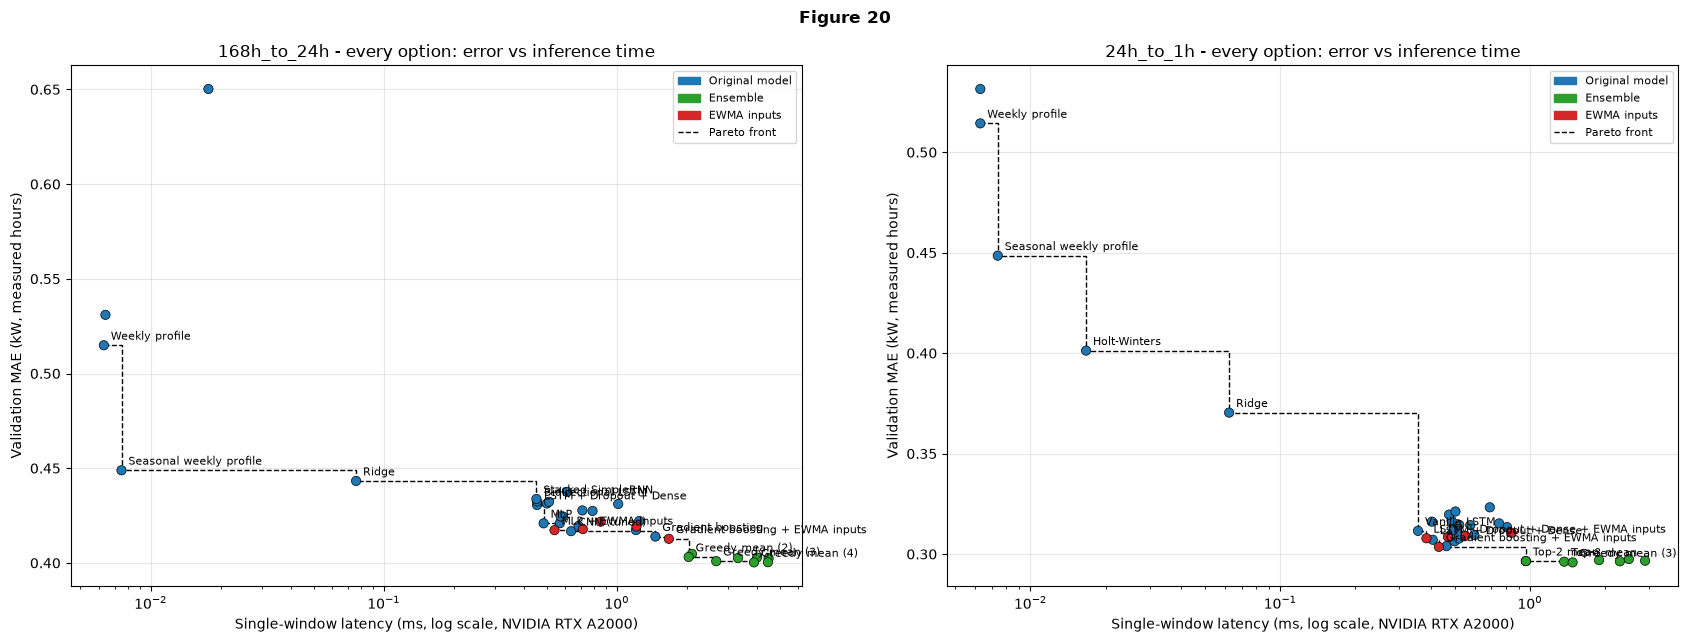

In [ ]:
# Every option (original models, ensembles, EWMA-feature models): validation MAE vs single-window latency
OPTION_COLORS = {'Original model': 'C0', 'Ensemble': 'C2', 'EWMA inputs': 'C3'}

def all_options(setup):
    """Every original model, ensemble and EWMA-feature model of one setup: kind, validation MAE and latency."""
    rows = [{'option': n, 'kind': 'Original model', 'val MAE': r['val MAE'], 'single-window ms': r['single-window ms']}
            for n, r in cost.loc[setup].iterrows()]
    rows += [{'option': label, 'kind': 'Ensemble', 'val MAE': r['val MAE'], 'single-window ms': r['single-window ms']}
             for label, r in ensemble_tables[setup].iloc[1:].iterrows()]  # row 0 is the best single model again
    rows += [{'option': f'{n} + EWMA inputs', 'kind': 'EWMA inputs', 'val MAE': r['val MAE'],
              'single-window ms': r['single-window ms']} for n, r in ewm_results[setup].items()]
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 6.5), squeeze=False)
for ax, setup in zip(axes[0], WINDOWS):
    options = all_options(setup)
    x, y = options['single-window ms'].to_numpy(float), options['val MAE'].to_numpy(float)
    ax.scatter(x, y, s=45, c=options['kind'].map(OPTION_COLORS), edgecolor='k', linewidth=0.5, zorder=3)
    front = pareto_front(x, y)
    ax.step(x[front], y[front], where='post', color='k', ls='--', lw=1)
    for i in front:
        ax.annotate(options['option'][i], (x[i], y[i]), textcoords='offset points', xytext=(5, 4), fontsize=8)
    ax.set(xscale='log', xlabel=f'Single-window latency (ms, log scale, {device_name})',
           ylabel='Validation MAE (kW, measured hours)', title=f'{setup} - every option: error vs inference time')
    ax.legend(handles=[*(Patch(color=c, label=k) for k, c in OPTION_COLORS.items()),
                       Line2D([], [], color='k', ls='--', lw=1, label='Pareto front')], fontsize=8)
    ax.grid(alpha=0.3)
    print(f'Pareto front - {setup} (fastest first)')
    display(options.iloc[front].set_index('option').round(4))
plt.tight_layout()
show(20)


### Zoom: the low-error options (Figure 21)
The same options as Figure 20, keeping only those within `ZOOM_PCT` % of the lowest validation MAE (the crowded bottom of that plot). Each point is numbered from most to least accurate, and the table under the figure is the key: name, kind, validation MAE, latency, and whether it is on the Pareto front. The dotted line is the best single original model, so anything below it beats every model on its own.

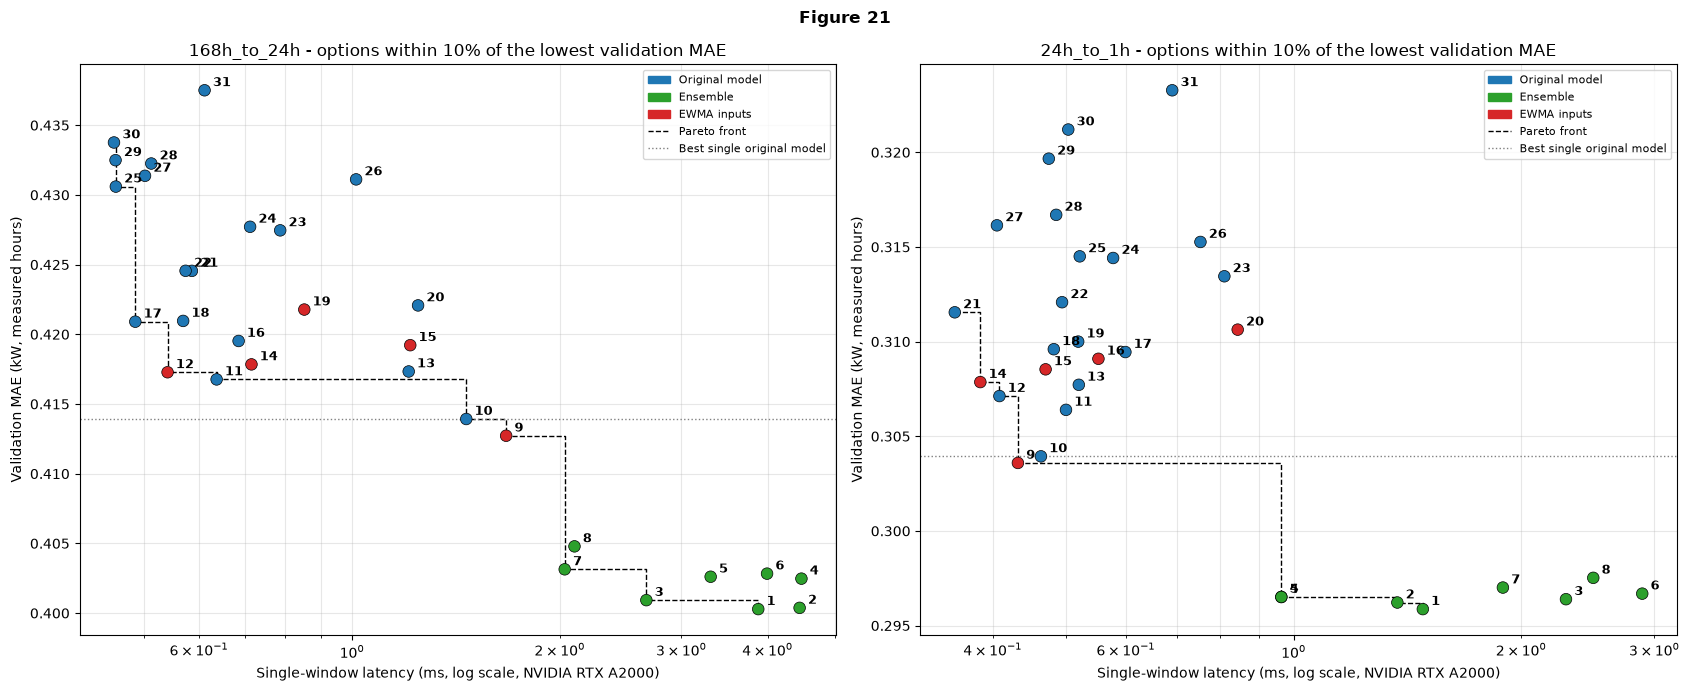

Key - 168h_to_24h (numbers on the plot)


,option,kind,val MAE,single-window ms,Pareto front
1,Greedy mean (4),Ensemble,0.4003,3.8762,True
2,Greedy mean (5),Ensemble,0.4004,4.4498,False
3,Greedy mean (3),Ensemble,0.4009,2.6686,True
4,Top-5 mean,Ensemble,0.4025,4.4769,False
5,Top-3 mean,Ensemble,0.4026,3.3072,False
6,Top-4 mean,Ensemble,0.4028,3.9918,False
7,Greedy mean (2),Ensemble,0.4031,2.0323,True
8,Top-2 mean,Ensemble,0.4048,2.0996,False
9,Gradient boosting + EWMA inputs,EWMA inputs,0.4127,1.6715,True
10,Gradient boosting,Original model,0.4139,1.4633,True


Key - 24h_to_1h (numbers on the plot)


,option,kind,val MAE,single-window ms,Pareto front
1,Greedy mean (3),Ensemble,0.2959,1.4819,True
2,Top-3 mean,Ensemble,0.2962,1.3713,True
3,Greedy mean (4),Ensemble,0.2964,2.2916,False
4,Greedy mean (2),Ensemble,0.2965,0.9631,True
5,Top-2 mean,Ensemble,0.2965,0.9631,False
6,Greedy mean (5),Ensemble,0.2967,2.8906,False
7,Top-4 mean,Ensemble,0.2970,1.8911,False
8,Top-5 mean,Ensemble,0.2975,2.4901,False
9,Gradient boosting + EWMA inputs,EWMA inputs,0.3036,0.4318,True
10,Gradient boosting,Original model,0.3039,0.4632,False


In [ ]:
# Zoom on the competitive options: within ZOOM_PCT % of the lowest validation MAE, numbered, with a key table
ZOOM_PCT = 10
zoom_keys = {}
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 7), squeeze=False)
for ax, setup in zip(axes[0], WINDOWS):
    options = all_options(setup)
    zoom = (options[options['val MAE'] <= options['val MAE'].min() * (1 + ZOOM_PCT / 100)]
            .sort_values('val MAE').reset_index(drop=True))
    zoom.index += 1  # the numbers drawn on the plot
    x, y = zoom['single-window ms'].to_numpy(float), zoom['val MAE'].to_numpy(float)
    ax.scatter(x, y, s=70, c=zoom['kind'].map(OPTION_COLORS), edgecolor='k', linewidth=0.5, zorder=3)
    for num, xi, yi in zip(zoom.index, x, y):
        ax.annotate(str(num), (xi, yi), textcoords='offset points', xytext=(6, 3), fontsize=9, weight='bold')
    front = pareto_front(x, y)  # nothing outside the zoom can dominate a point inside it (its MAE is higher)
    ax.step(x[front], y[front], where='post', color='k', ls='--', lw=1)
    ax.axhline(cost.loc[setup, 'val MAE'].min(), color='0.5', ls=':', lw=1)
    ax.set(xscale='log', xlabel=f'Single-window latency (ms, log scale, {device_name})',
           ylabel='Validation MAE (kW, measured hours)',
           title=f'{setup} - options within {ZOOM_PCT}% of the lowest validation MAE')
    ax.legend(handles=[*(Patch(color=c, label=k) for k, c in OPTION_COLORS.items()),
                       Line2D([], [], color='k', ls='--', lw=1, label='Pareto front'),
                       Line2D([], [], color='0.5', ls=':', lw=1, label='Best single original model')], fontsize=8)
    ax.grid(alpha=0.3, which='both')
    zoom['Pareto front'] = np.isin(np.arange(len(zoom)), front)
    zoom_keys[setup] = zoom
plt.tight_layout()
show(21)
for setup, zoom in zoom_keys.items():
    print(f'Key - {setup} (numbers on the plot)')
    display(zoom.round(4))


### Cost figures: accuracy vs size, training time and latency
Every original model of both stages and both setups, from the cost section's measurements (`cost`) and the training times (`train_secs`). The letter is the setup (a: 168h_to_24h, b: 24h_to_1h).
* **Figure 22:** validation MAE against size, training time of the selected configuration, and single-window latency (lower left is better). Points are numbered by validation MAE, with the key table above each row, so close points stay readable; the horizontal lines are the best model of each stage. Seasonal naive has no training time, so it is missing from the middle panel.
* **Figure 23:** the same, zoomed in on the models within `ZOOM_PCT` % of the lowest validation MAE.
* **Figure 24:** inference time per 1,000 windows (batched) and per single window, lowest validation MAE at the top, colored by stage.

Key - 168h_to_24h (numbers on Figures 22 and 23)


,#,stage,val MAE,size,"ms per 1,000 windows",single-window ms,train time (s)
model,,,,,,,
Gradient boosting,1,Baseline,0.4139,450000,8.1971,1.4633,98.4882
CNN (tuned),2,Stage 1,0.4168,12944,5.7275,0.6362,71.6954
TCN (tuned),3,Stage 2,0.4173,824472,46.2637,1.2076,68.8394
CNN,4,Stage 1,0.4195,10032,4.8269,0.6847,18.8988
MLP,5,Stage 1,0.4209,218264,2.0039,0.4850,2.6106
Stacked SimpleRNN (tuned),6,Stage 2,0.4210,11352,3.7456,0.5690,7.0016
TCN,7,Stage 2,0.4221,211544,26.4599,1.2459,28.1096
Stacked GRU (tuned),8,Stage 2,0.4246,95256,14.4816,0.5859,27.2307
Bidirectional LSTM (tuned),9,Stage 2,0.4246,45592,8.9355,0.5737,18.8202


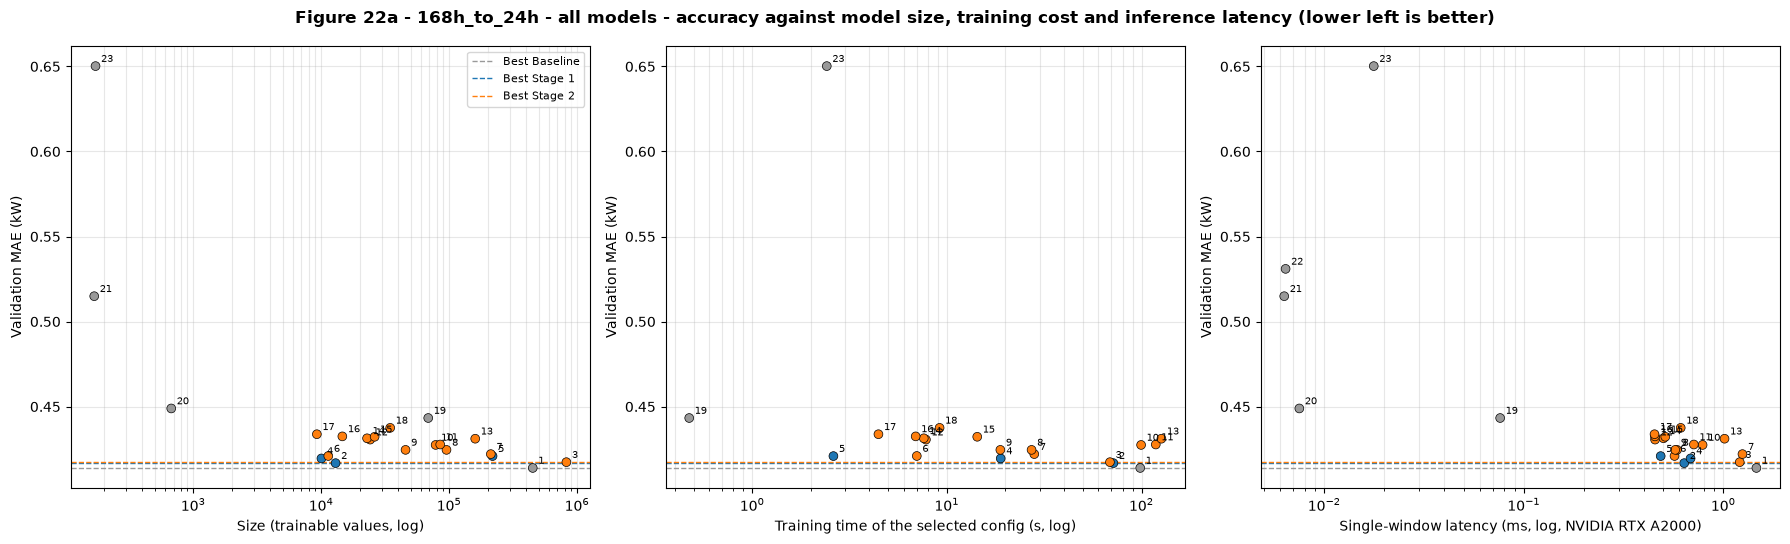

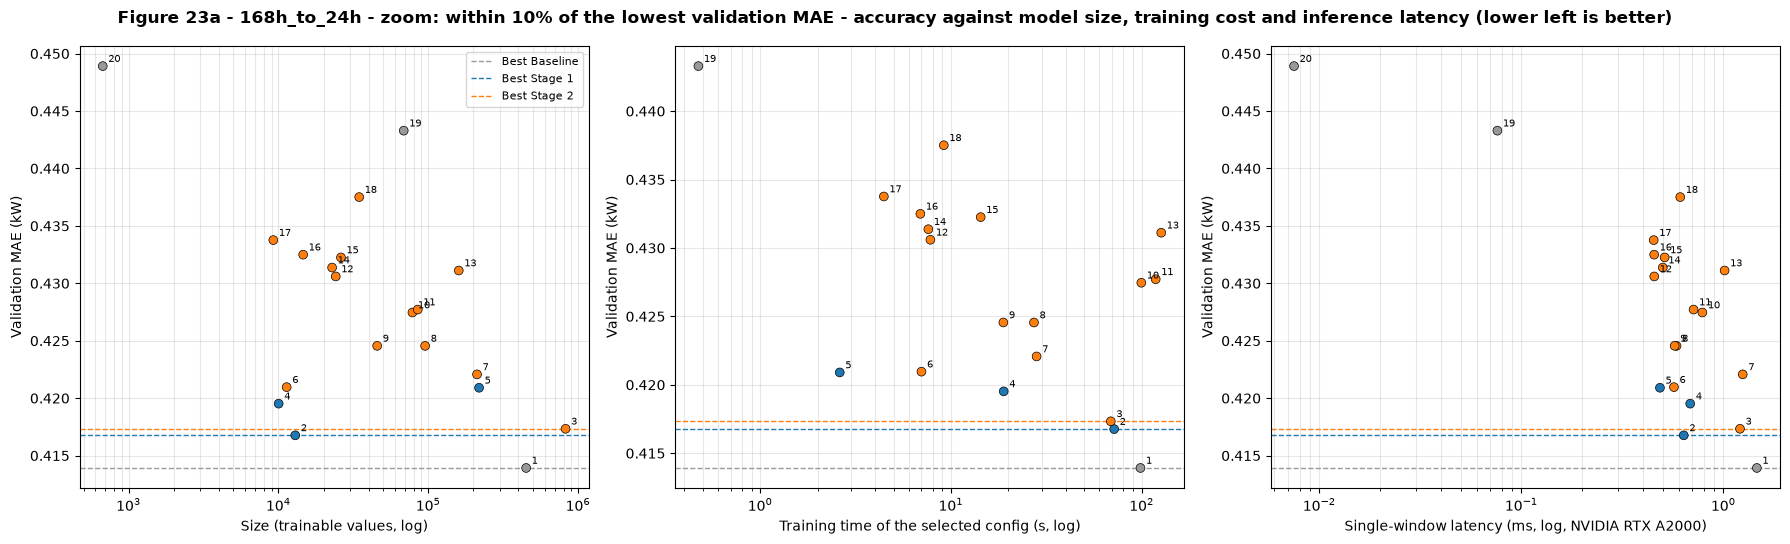

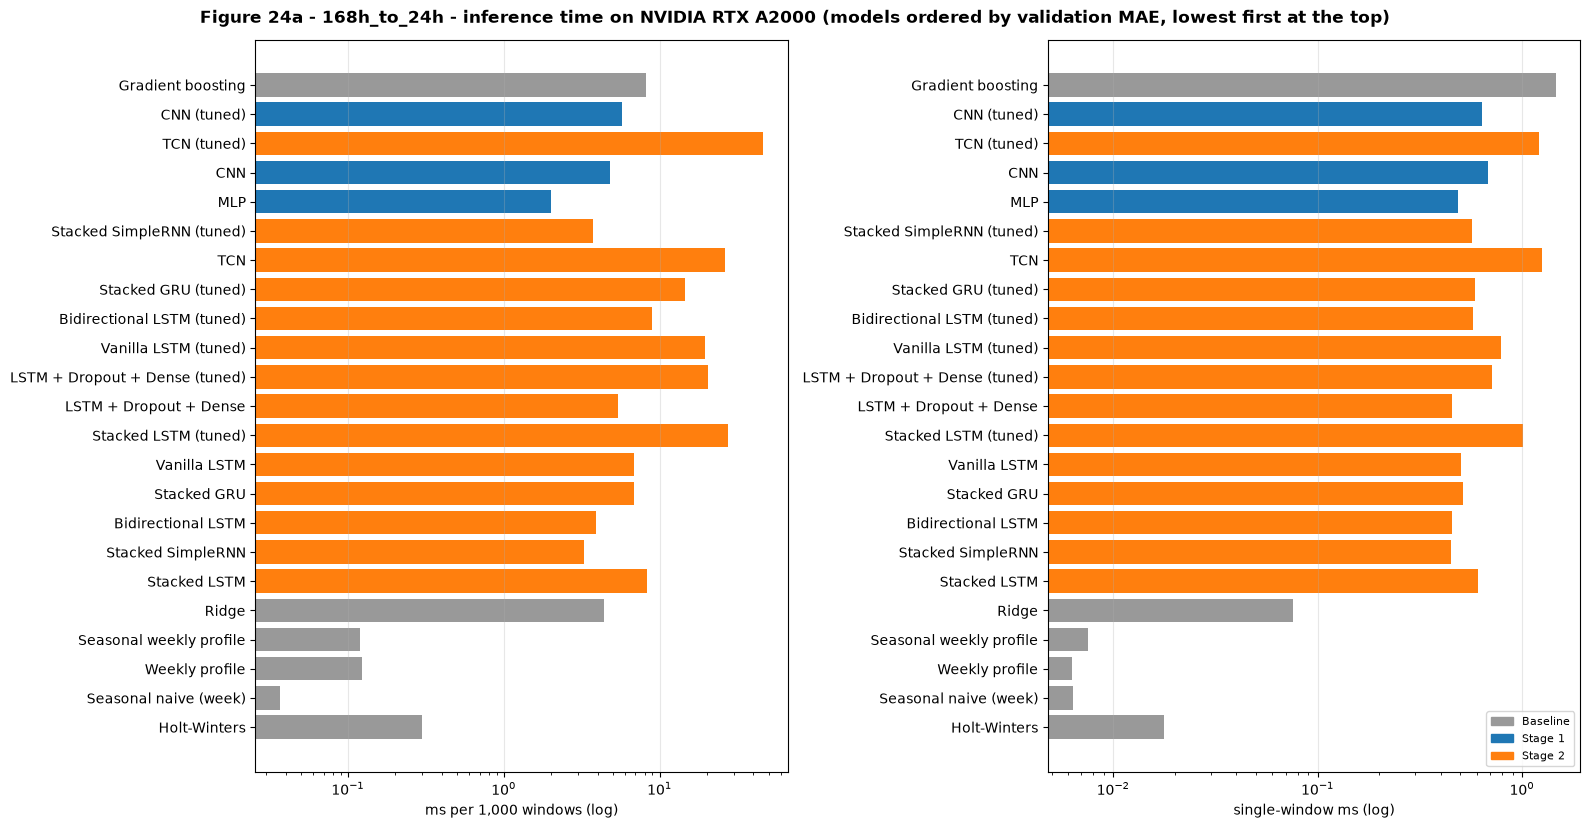

Key - 24h_to_1h (numbers on Figures 22 and 23)


,#,stage,val MAE,size,"ms per 1,000 windows",single-window ms,train time (s)
model,,,,,,,
Gradient boosting,1,Baseline,0.3039,31250,4.8113,0.4632,21.9891
Vanilla LSTM (tuned),2,Stage 2,0.3064,9745,0.8965,0.4999,8.6829
LSTM + Dropout + Dense,3,Stage 2,0.3071,23361,1.4400,0.4082,4.3864
LSTM + Dropout + Dense (tuned),4,Stage 2,0.3077,83585,6.1438,0.5198,37.7146
Stacked LSTM (tuned),5,Stage 2,0.3094,124993,5.9531,0.5990,28.6531
Stacked GRU,6,Stage 2,0.3096,25377,1.7390,0.4817,9.1874
Stacked GRU (tuned),7,Stage 2,0.3100,93761,5.1549,0.5188,6.3103
Vanilla LSTM,8,Stage 2,0.3115,21313,1.2544,0.3563,5.7016
Stacked LSTM,9,Stage 2,0.3121,33825,1.4326,0.4940,7.7421


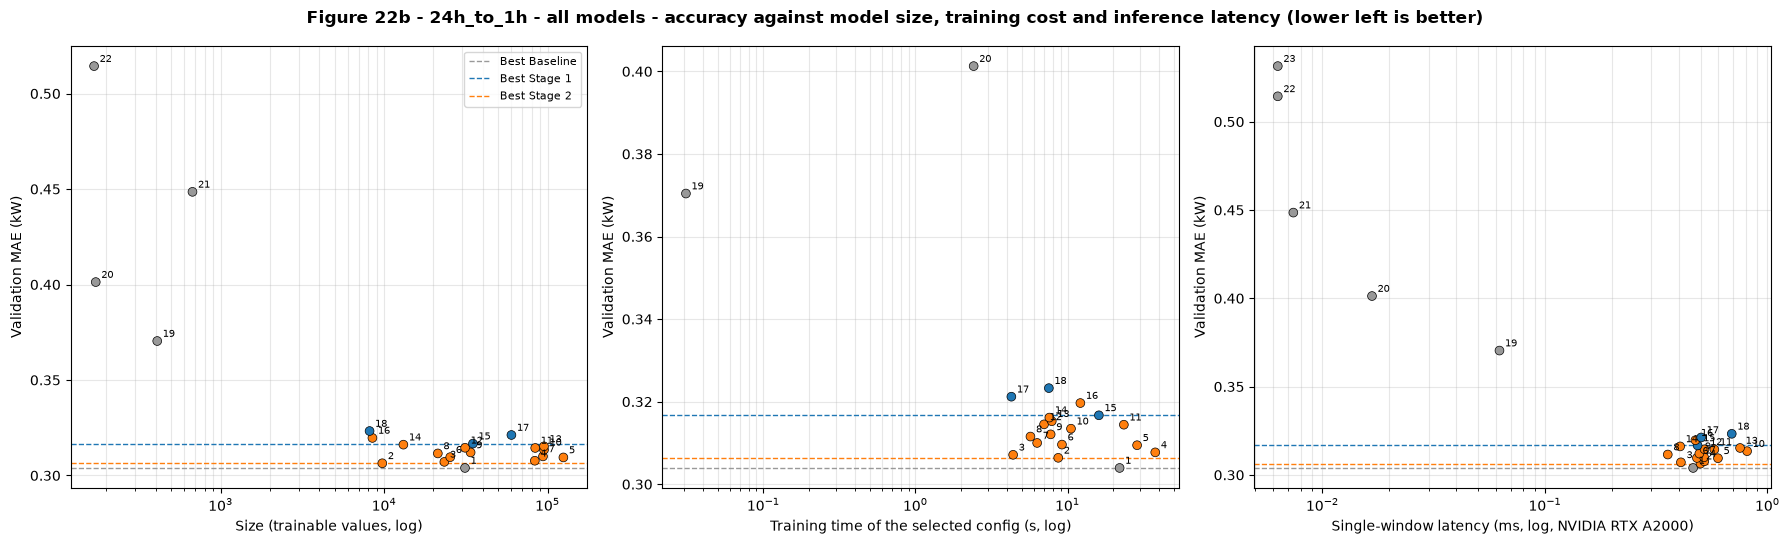

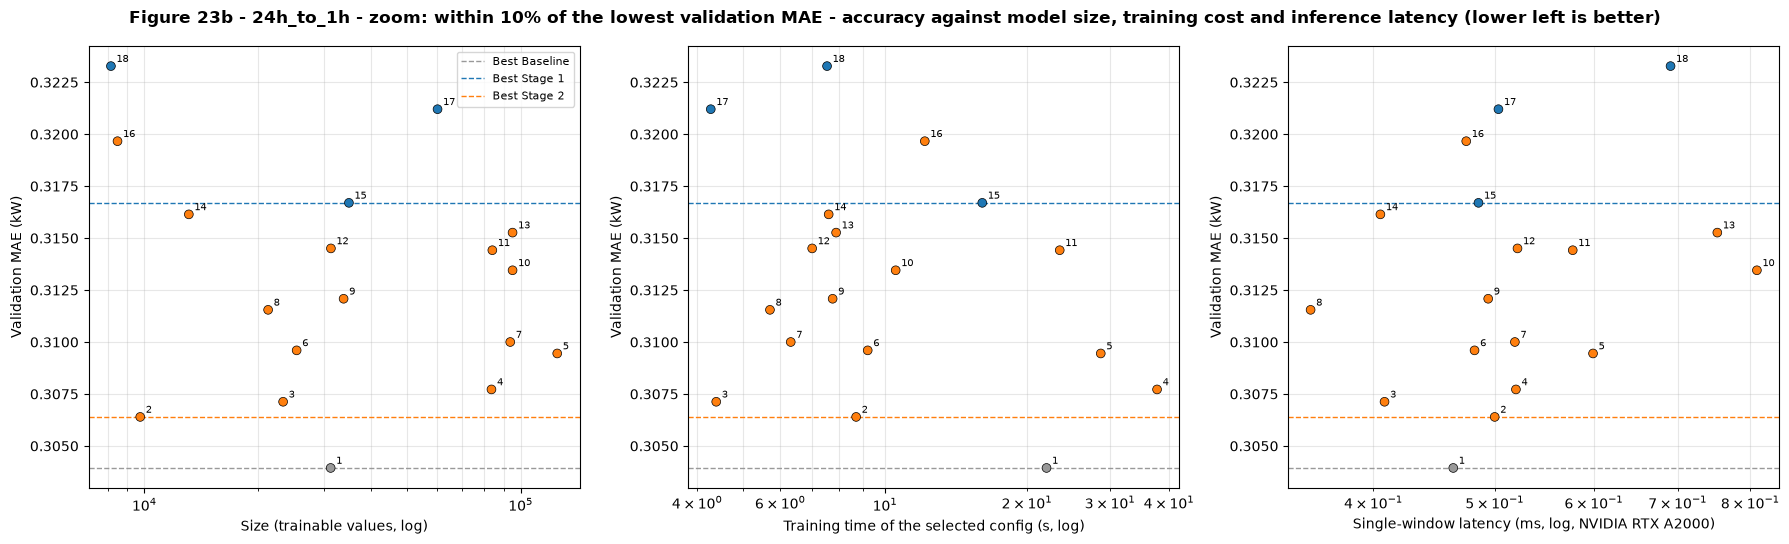

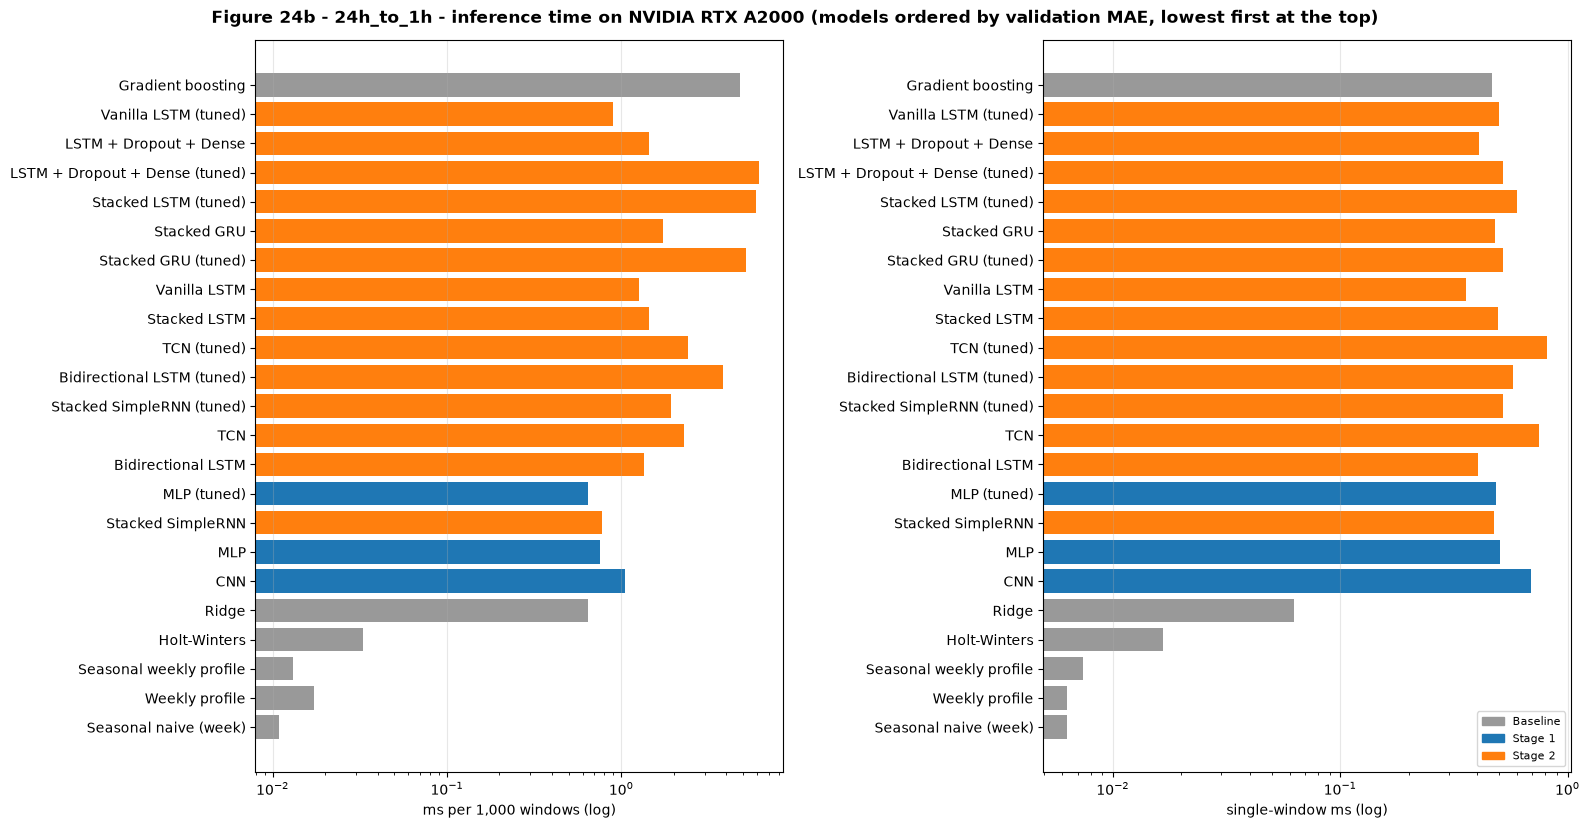

In [ ]:
# Figures 22-24 for every original model, from the cost section's measurements
for setup in WINDOWS:
    models = cost.loc[setup].copy()  # validation-MAE order
    models['train time (s)'] = pd.Series(train_secs[setup])
    models.insert(0, '#', np.arange(1, len(models) + 1))
    print(f'Key - {setup} (numbers on Figures 22 and 23)')
    display(models.round(4))

    # Full view, then a zoom on the models within ZOOM_PCT % of the lowest validation MAE
    zoomed = models[models['val MAE'] <= models['val MAE'].min() * (1 + ZOOM_PCT / 100)]
    for shown_models, view, num in [(models, 'all models', 22), (zoomed, f'zoom: within {ZOOM_PCT}% of the lowest validation MAE', 23)]:
        fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
        for ax, column, xlabel in [(axes[0], 'size', 'Size (trainable values, log)'),
                                   (axes[1], 'train time (s)', 'Training time of the selected config (s, log)'),
                                   (axes[2], 'single-window ms', f'Single-window latency (ms, log, {device_name})')]:
            shown = shown_models[shown_models[column] > 0]  # log axis: seasonal naive has size 0 and no training time
            ax.scatter(shown[column], shown['val MAE'], s=40, c=shown['stage'].map(STAGE_COLORS), edgecolor='k',
                       linewidth=0.5, zorder=3)
            for _, r in shown.iterrows():
                ax.annotate(str(r['#']), (r[column], r['val MAE']), fontsize=7, xytext=(4, 3), textcoords='offset points')
            for stage, best in shown_models.groupby('stage')['val MAE'].min().items():
                ax.axhline(best, color=STAGE_COLORS[stage], ls='--', lw=1, label=f'Best {stage}')
            ax.set(xscale='log', xlabel=xlabel, ylabel='Validation MAE (kW)')
            ax.grid(alpha=0.3, which='both')
        axes[0].legend(fontsize=8)
        fig.suptitle(f'{setup} - {view} - accuracy against model size, training cost and inference latency (lower left is better)')
        plt.tight_layout()
        show(num, list(WINDOWS).index(setup))

    fig, axes = plt.subplots(1, 2, figsize=(16, 1.5 + 0.3 * len(models)))
    order = models.sort_values('val MAE').index[::-1]  # barh draws bottom-up: lowest validation MAE at the top
    for ax, column in zip(axes, ['ms per 1,000 windows', 'single-window ms']):
        ax.barh(order, models.loc[order, column], color=models.loc[order, 'stage'].map(STAGE_COLORS))
        ax.set(xlabel=f'{column} (log)', xscale='log')
        ax.grid(alpha=0.3, axis='x')
    axes[1].legend(handles=[Patch(color=c, label=s) for s, c in STAGE_COLORS.items()], fontsize=8, loc='lower right')
    fig.suptitle(f'{setup} - inference time on {device_name} (models ordered by validation MAE, lowest first at the top)')
    plt.tight_layout()
    show(24, list(WINDOWS).index(setup))


### Selected model for testing
The test section scores every model of both stages and, in addition, the option chosen here for each setup: the **best balance between validation error and single-window latency**, read off Figures 20 and 21 (the Pareto front and its key). It can be any option: a model of either stage, an ensemble, or an EWMA-input model. The choice uses validation only.
* **168h_to_24h:** `Greedy mean (2)` (gradient boosting + Stacked SimpleRNN (tuned)) is about 2.6 % below the best single model at about 1.9 ms. The larger ensembles gain under 0.7 % more for up to twice the latency.
* **24h_to_1h:** `Gradient boosting + EWMA inputs` is the fastest option within about 2.6 % of the lowest validation MAE (0.31 ms, about a third of the cheapest competitive ensemble).
* **Refit:** like the original models, the selected option is also scored after its train + validation refit when it has one. An ensemble uses its members' refits when every member has one, and an EWMA-input model outside the two refitted per setup is refitted here.

Change `SELECTED` in the next cell to test a different option.

In [ ]:
# The option tested as the best balance of validation error and latency, chosen by hand from Figures 20 and 21
SELECTED = {'168h_to_24h': 'Greedy mean (2)', '24h_to_1h': 'Gradient boosting + EWMA inputs'}
EWM_SUFFIX = ' + EWMA inputs'
option_table = {setup: all_options(setup).set_index('option') for setup in WINDOWS}

def option_kind(setup, option):
    assert option in option_table[setup].index, f'{setup}: {option!r} is not an option - pick a name from the key tables above'
    return option_table[setup].loc[option, 'kind']

def option_forecast(setup, option, d, refit=False):
    """Forecasts in kW for windows d from any option: an original model, an ensemble (the mean of its members) or an
    EWMA-input model. refit=True uses the train + validation refits."""
    kind = option_kind(setup, option)
    if kind == 'Ensemble':
        return np.mean([option_forecast(setup, n, d, refit) for n in ensembles[setup][option]], axis=0)
    if kind == 'EWMA inputs':
        result = ewm_results[setup][option.removesuffix(EWM_SUFFIX)]
        return forecast(result['refit' if refit else 'model'], with_ewm_inputs(d, WINDOWS[setup]['lookback']))
    return forecast(refits[setup][option], d) if refit else model_forecast(setup, option, d)

def has_refit(setup, option):
    kind = option_kind(setup, option)
    if kind == 'Ensemble':
        return all(has_refit(setup, n) for n in ensembles[setup][option])
    if kind == 'EWMA inputs':
        return ewm_results[setup][option.removesuffix(EWM_SUFFIX)]['refit'] is not None
    return option in refits[setup]

for setup, option in SELECTED.items():  # an EWMA-input model outside the refitted ones is refitted (and saved) here
    if option_kind(setup, option) == 'EWMA inputs' and not has_refit(setup, option):
        name = option.removesuffix(EWM_SUFFIX)
        ewm_results[setup][name]['refit'] = refit_ewm(setup, [name])[name]
        save_variant('ewm_models', ewm_results)

rows = []
for setup, option in SELECTED.items():
    options, va = option_table[setup], data[setup]['val']
    chosen, best = options.loc[option], options['val MAE'].idxmin()
    assert np.isclose(evaluate(va, option_forecast(setup, option, va))['MAE'], chosen['val MAE'], atol=1e-5), \
        f'{setup}: {option} does not reproduce its validation MAE'
    rows.append({'setup': setup, 'selected': option, 'kind': chosen['kind'], 'val MAE': chosen['val MAE'],
                 'single-window ms': chosen['single-window ms'], 'refit on train + val': has_refit(setup, option),
                 'lowest val MAE option': best, 'its val MAE': options.loc[best, 'val MAE'],
                 'its single-window ms': options.loc[best, 'single-window ms']})
print('Selected options (validation only)')
display(pd.DataFrame(rows).set_index('setup').round(4))

Selected options (validation only)


,selected,kind,val MAE,single-window ms,refit on train + val,lowest val MAE option,its val MAE,its single-window ms
setup,,,,,,,,
168h_to_24h,Greedy mean (2),Ensemble,0.4031,2.0323,True,Greedy mean (4),0.4003,3.8762
24h_to_1h,Gradient boosting + EWMA inputs,EWMA inputs,0.3036,0.4318,True,Greedy mean (3),0.2959,1.4819


## Test set evaluation (Stage 1 and Stage 2)
Every model of both stages is frozen: its configuration was chosen on validation, and the test split (the last 20 % of hours) is scored **once, for both stages together**, with the same windows, the same measured-hours rule and the same metrics.

* **Panels:** each stage is ranked by its **validation** MAE. The ranking is not redone on test, since picking models by their test score would leak the test set into model selection. Stage 1 (with the baselines) is shown as its top 3 and its remaining models; Stage 2 as its top 3 and its remaining models split by layout (Vanilla / Stacked LSTM; Bidirectional / Dropout + Dense LSTM; GRU, SimpleRNN and TCN), so no panel has more than about six models. Each model keeps the same color in every figure.
* This section **only forecasts**: the models are the ones trained above or loaded from `models/combined/stage1.pkl` and `models/combined/stage2.pkl`, including the train + validation refits. Nothing is trained or refitted here, and the test windows are only built here.
* The **selected model** (chosen in **Further investigation**) is scored at the end of the section, in the same run.
* Runs only as set by `TestModels` in **Run settings** at the top.

In [ ]:
# Test machinery: test windows, model colors, and the test run (or its stored results)
def build_test_windows():
    """Test windows, built only when testing or plotting stored test results (same checks as train / val)."""
    for setup, w in WINDOWS.items():
        if 'test' not in data[setup]:
            data[setup]['test'] = make_windows(*splits['test'], **w)
            check_windows(data[setup]['test'], splits['test'], w['lookback'])

def model_colors(names):
    """One fixed color per model, shared by every figure of a test section."""
    palette = plt.get_cmap('tab10').colors if len(names) <= 10 else plt.get_cmap('tab20').colors + plt.get_cmap('tab20b').colors
    assert len(names) <= len(palette), 'more models than colors'
    return dict(zip(names, palette))

def test_or_load(run_now, cache, flag_name, label, models, refit_names, refs, groups):
    """Test-set results of one section, or None when there is nothing to plot.
    run_now True: forecast the test windows with `models` (setup -> names, ranked here by validation MAE), the
    reference models `refs` and the refits `refit_names`, and store everything in `cache`.
    run_now False: load `cache` if it exists; nothing is tested.
    groups(ranked names) -> [(panel title, names)] splits the ranked models into figure panels."""
    if run_now:
        build_test_windows()
        ranked = {setup: sorted(models[setup], key=lambda name: val_mae_of(setup, name)) for setup in WINDOWS}
        names = {setup: [*ranked[setup], *refs[setup]] for setup in WINDOWS}
        stored = {'ranked': ranked, 'refs': refs,
                  'pred': {setup: {name: model_forecast(setup, name, data[setup]['test']) for name in names[setup]}
                           for setup in WINDOWS},
                  'refit_pred': {setup: {name: forecast(refits[setup][name], data[setup]['test'])
                                         for name in refit_names[setup]} for setup in WINDOWS},
                  'val_mae': {setup: {name: val_mae_of(setup, name) for name in names[setup]} for setup in WINDOWS}}
        with open(cache, 'wb') as f:
            pickle.dump(stored, f)
        print(f'{label}: test run complete; results stored in {cache}')
    elif os.path.exists(cache):
        with open(cache, 'rb') as f:
            stored = pickle.load(f)
        assert 'pred' in stored, f'{cache} is from an older version of this notebook - set {flag_name} = True'
        build_test_windows()
        print(f'{flag_name} = False: plotting the stored {label} results from {cache} (no testing)')
        changed = [name for setup in WINDOWS for name, mae in stored['val_mae'][setup].items()
                   if name not in val_pred[setup] or not np.isclose(val_mae_of(setup, name), mae, atol=1e-4)]
        if changed:
            print(f'WARNING: {len(changed)} stored models (e.g. {changed[0]}) score differently on validation than the '
                  f'ones in memory. Set {flag_name} = True to test the current models.')
    else:
        print(f'{flag_name} = False and {cache} does not exist: no testing, test figures skipped')
        return None
    for setup in WINDOWS:
        forecasts = (*stored['pred'][setup].values(), *stored['refit_pred'][setup].values())
        assert all(p.shape == data[setup]['test']['y_kw'].shape for p in forecasts), \
            f'stored forecasts do not match the current test windows - set {flag_name} = True'
    run = SimpleNamespace(label=label, **stored)
    run.groups = {setup: groups(run.ranked[setup]) for setup in WINDOWS}
    run.colors = model_colors(list(dict.fromkeys(name for setup in WINDOWS
                                                 for name in [*run.ranked[setup], *run.refs[setup]])))
    return run

In [ ]:
# Plot helpers of the test figures
TEST_FIGS = {'scores': 25, 'by hour': 26, 'spans': 27, 'scatter': 28, 'by month': 29, 'imputed': 30, 'refit': 31}

def plot_if(run, *plots):
    """Draw each plot function for a test run, or say there is nothing to draw."""
    if run is None:
        print('No test results to plot - skipped')
        return
    for plot in plots:
        plot(run)

def group_grid(run, row_height=3.8):
    """One row of axes per panel group and one column per setup; rows share the y axis within a column."""
    n_rows = len(next(iter(run.groups.values())))
    return plt.subplots(n_rows, len(WINDOWS), figsize=(17, row_height * n_rows), sharey='col', squeeze=False)

def draw_models(ax, run, setup, names, curve):
    """One line per named model, plus the section's reference models dashed; curve(name) -> (x, y)."""
    for name in names:
        ax.plot(*curve(name), marker='.', color=run.colors[name], label=name)
    for name in run.refs[setup]:
        ax.plot(*curve(name), ls='--', color=run.colors[name], label=f'{name} (reference)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

In [ ]:
# Test run of every Stage 1 and Stage 2 model (TestModels = True) or its stored results
S2_PANELS = [('remaining: Vanilla / Stacked LSTM', ('Vanilla LSTM', 'Stacked LSTM')),
             ('remaining: Bidirectional / Dropout + Dense LSTM', ('Bidirectional LSTM', 'LSTM + Dropout + Dense')),
             ('remaining: GRU, SimpleRNN, TCN', ('Stacked GRU', 'Stacked SimpleRNN', 'TCN'))]

def test_groups(ranked):
    """Per stage: the top 3 on validation, then the remaining models (Stage 2: split by layout)."""
    s1 = [n for n in ranked if stage_of(n) != 'Stage 2']
    s2 = [n for n in ranked if stage_of(n) == 'Stage 2']
    groups = [('Stage 1: top 3 on validation', s1[:3]), ('Stage 1: remaining models', s1[3:]),
              ('Stage 2: top 3 on validation', s2[:3])]
    groups += [(f'Stage 2: {title}', [n for n in s2[3:] if family_of(n) in families]) for title, families in S2_PANELS]
    return [group for group in groups if group[1]]  # no Stage 2 panels when Stage 2 was skipped

test_models = {setup: STAGE1_MODELS[setup] + (stage2_names()[setup] if stage2_ready else []) for setup in WINDOWS}
test_run = test_or_load(TestModels, TEST_CACHE, 'TestModels', 'Stage 1 + 2', test_models,
                        refit_names={setup: list(refits[setup]) for setup in WINDOWS},
                        refs={setup: [] for setup in WINDOWS}, groups=test_groups)

TestModels = False and models/test_predictions.pkl does not exist: no testing, test figures skipped


In [ ]:
def plot_test_scores(run):
    """Test scores in validation order next to the validation MAE, and validation vs test bars."""
    n_models = max(len(run.val_mae[s]) for s in WINDOWS)
    fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 1.5 + 0.4 * n_models))
    for ax, setup in zip(axes, WINDOWS):
        te, refs = data[setup]['test'], run.refs[setup]
        names = [*run.ranked[setup], *refs]
        table = pd.DataFrame({n: evaluate(te, run.pred[setup][n]) for n in names}).T.add_prefix('test ')
        table.insert(0, 'val MAE', pd.Series(run.val_mae[setup]))
        table['test - val MAE'] = table['test MAE'] - table['val MAE']
        table['test rank'] = table['test MAE'].rank().astype(int)
        table.index = [f'{n} (reference)' if n in refs else n for n in names]
        print(f"{run.label} test - {setup} ({len(te['t'])} windows, measured hours, ordered by validation MAE)")
        display(table.round(4))
        hbar_pair(ax, table.index, table['val MAE'], table['test MAE'], ('Validation', 'Test'), ('0.7', 'C0'))
        ax.set(xlabel='MAE (kW, measured hours)', title=f'{run.label} - {setup} - validation vs test MAE')
    plt.tight_layout()
    show(TEST_FIGS['scores'])

plot_if(test_run, plot_test_scores)

No test results to plot - skipped


### Error by forecast hour and by hour of day
* **168h_to_24h:** test MAE at each lead hour (1 = the first hour forecast, 24 = the last), averaged over every hourly forecast origin.
* **24h_to_1h:** there is only one lead hour, so the error is split by the **hour of day being forecast** instead, which shows whether the morning and evening peaks are where the misses come from.

Panels in the same column share a y axis, so the top 3 and the remaining models can be compared directly.

In [ ]:
def error_curve(run, setup):
    """curve(name) -> (x, test MAE): by lead hour for a multi-hour horizon, by the hour of day being forecast for a
    1-hour horizon. Returns the curve and its x-axis label."""
    te = data[setup]['test']
    horizon = te['rows'].shape[1]
    abs_err = lambda name: np.where(te['measured'], np.abs(run.pred[setup][name] - te['y_kw']), np.nan)
    if horizon > 1:
        return (lambda name: (np.arange(1, horizon + 1), np.nanmean(abs_err(name), axis=0))), 'Hours ahead'
    hour_of_day = features.index[te['t']].hour
    return (lambda name: (np.arange(24), pd.Series(abs_err(name)[:, 0]).groupby(hour_of_day).mean().to_numpy()),
            'Hour of day being forecast')

def plot_error_by_hour(run):
    fig, axes = group_grid(run)
    for col, setup in enumerate(WINDOWS):
        curve, xlabel = error_curve(run, setup)
        for ax, (group, names) in zip(axes[:, col], run.groups[setup]):
            draw_models(ax, run, setup, names, curve)
            ax.set(xlabel=xlabel, ylabel='Test MAE (kW)', title=f'{run.label} - {setup} - {group}')
    plt.tight_layout()
    show(TEST_FIGS['by hour'])

plot_if(test_run, plot_error_by_hour)

No test results to plot - skipped


### Forecast vs actual on the test set
Two fully measured test periods, the same dates for both setups: **3 days** (Friday to Sunday, so the switch from weekday to weekend is visible) and **1 week** (Monday to Sunday). The forecasts are placed back to back:
* **168h_to_24h:** one 24-hour forecast issued at each midnight (dotted lines), so each day is a separate forecast.
* **24h_to_1h:** consecutive 1-hour-ahead forecasts, each made with the actual load up to the previous hour.

In [ ]:
# span_start and back_to_back are defined with the validation-week figure (Figure 17)
def plot_forecast_spans(run):
    spans = {'3 days': (span_start(0.25, 3, weekday=4), 3), '1 week': (span_start(0.5, 7, weekday=0), 7)}
    for setup in WINDOWS:
        te, horizon = data[setup]['test'], WINDOWS[setup]['horizon']
        panels = list(itertools.product(spans.items(), run.groups[setup]))
        fig, axes = plt.subplots(len(panels), 1, figsize=(17, 4 * len(panels)))
        for ax, ((span, (pos, days)), (group, names)) in zip(axes, panels):
            hours, actual = back_to_back(setup, te['y_kw'], pos, days)
            ax.plot(hours, actual, 'k', lw=2.5, label='Actual')
            for name in names:
                ax.plot(*back_to_back(setup, run.pred[setup][name], pos, days), color=run.colors[name], lw=1.3, label=name)
            if horizon > 1:  # each forecast starts at midnight
                for origin in hours[::horizon]:
                    ax.axvline(origin, color='0.6', ls=':', lw=1)
            ax.set(ylabel='Global_active_power (kW)',
                   title=f'{run.label} - {setup} - {span} from {hours[0]:%a %d %b %Y}: actual vs {group}')
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b\n%H:%M'))
            ax.legend(fontsize=8, loc='upper left')
            ax.grid(alpha=0.3)
        plt.tight_layout()
        show(TEST_FIGS['spans'], list(WINDOWS).index(setup))

plot_if(test_run, plot_forecast_spans)

No test results to plot - skipped


### Predicted vs actual, and error by month
* **Predicted vs actual (best validation model per setup):** every measured test forecast-hour, binned (darker = more hours). Points on the dashed line are perfect; a cloud that flattens below the line at high loads means peaks are under-forecast.
* **Test MAE by month:** the test split runs from February to November 2010, so this shows whether errors follow the seasons (higher, more variable winter load vs lighter summer load).

In [ ]:
def plot_scatter_best(run):
    """Predicted vs actual for the best validation model of each setup, every measured test forecast-hour."""
    fig, axes = plt.subplots(1, len(WINDOWS), figsize=(14, 6))
    for ax, setup in zip(axes, WINDOWS):
        te, name = data[setup]['test'], run.ranked[setup][0]
        actual, pred = te['y_kw'][te['measured']], run.pred[setup][name][te['measured']]
        hb = ax.hexbin(actual, pred, gridsize=60, bins='log', cmap='Blues', mincnt=1)
        lim = (0, max(actual.max(), pred.max()) * 1.02)
        ax.plot(lim, lim, 'k--', lw=1, label='Predicted = actual')
        ax.set(xlim=lim, ylim=lim, aspect='equal', xlabel='Actual (kW)', ylabel='Predicted (kW)',
               title=f'{run.label} - {setup} - {name} (best on validation)')
        ax.legend(loc='upper left')
        fig.colorbar(hb, ax=ax, label='Forecast-hours per bin (log)', shrink=0.8)
    plt.tight_layout()
    show(TEST_FIGS['scatter'])

def plot_error_by_month(run):
    fig, axes = group_grid(run)
    for col, setup in enumerate(WINDOWS):
        te = data[setup]['test']
        keep = te['measured'].ravel()
        month = features.index[te['rows'].ravel()[keep]].to_period('M')

        def curve(name):
            by_month = pd.Series(np.abs(run.pred[setup][name] - te['y_kw']).ravel()[keep]).groupby(month).mean()
            return by_month.index.to_timestamp(), by_month.to_numpy()

        for ax, (group, names) in zip(axes[:, col], run.groups[setup]):
            draw_models(ax, run, setup, names, curve)
            ax.set(ylabel='Test MAE (kW)', title=f'{run.label} - {setup} - test error by month ({group})')
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    plt.tight_layout()
    show(TEST_FIGS['by month'])

plot_if(test_run, plot_scatter_best, plot_error_by_month)

No test results to plot - skipped


### Error on imputed hours (test)
The scores above use **measured** target hours only. This figure compares that error with the error on the test hours that were **imputed**. Keep in mind that the imputed values are not real load. Almost every one comes from a long gap filled with the value from one week earlier, so the error here measures how close a model gets to the fill, not to what the household actually used. Seasonal naive (week) forecasts exactly that value, so its error is near zero by construction. Treat this as a diagnostic and use the measured-hours scores to compare models.

In [ ]:
def plot_imputed_error(run):
    """Test MAE on measured vs imputed target hours (imputed values are fills, not real load)."""
    n_models = max(len(run.val_mae[s]) for s in WINDOWS)
    fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 1.5 + 0.4 * n_models))
    for ax, setup in zip(axes, WINDOWS):
        te = data[setup]['test']
        names = [*run.ranked[setup], *run.refs[setup]]
        abs_err = {n: np.abs(run.pred[setup][n] - te['y_kw']) for n in names}
        hbar_pair(ax, names, [abs_err[n][te['measured']].mean() for n in names],
                  [abs_err[n][~te['measured']].mean() for n in names], ('Measured hours', 'Imputed hours'), ('C0', 'C3'))
        n_imputed = (~te['measured']).sum()
        ax.set(xlabel='Test MAE (kW)',
               title=f'{run.label} - {setup} - measured vs imputed target hours\n'
                     f'({n_imputed} imputed of {te["measured"].size} forecast-hours, {n_imputed / te["measured"].size:.1%})')
    plt.tight_layout()
    show(TEST_FIGS['imputed'])

plot_if(test_run, plot_imputed_error)

No test results to plot - skipped


### Refit on train + validation (test)
The train + validation refits of both stages (same hyperparameters) against the same models trained on train only. A lower test MAE means the extra, more recent training data helped.

In [ ]:
def plot_refit_effect(run):
    """Test MAE of each refitted model: trained on train only vs refitted on train + validation."""
    fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 4.5))
    for ax, setup in zip(axes, WINDOWS):
        te = data[setup]['test']
        names = [n for n in run.ranked[setup] if n in run.refit_pred[setup]]  # validation order
        table = pd.DataFrame({'train only': {n: evaluate(te, run.pred[setup][n])['MAE'] for n in names},
                              'train + val': {n: evaluate(te, run.refit_pred[setup][n])['MAE'] for n in names}})
        table['change (%)'] = 100 * (table['train + val'] / table['train only'] - 1)
        print(f'{run.label} test MAE (kW, measured hours) - {setup}')
        display(table.round(4))
        hbar_pair(ax, names, table['train only'], table['train + val'],
                  ('Trained on train', 'Refit on train + validation'), ('0.7', 'C0'))
        ax.set(xlabel='Test MAE (kW, measured hours)', title=f'{run.label} - {setup} - effect of refitting on train + validation')
    plt.tight_layout()
    show(TEST_FIGS['refit'])

plot_if(test_run, plot_refit_effect)

No test results to plot - skipped


### Selected model on the test set (Figure 32)
The option chosen in **Selected model for testing** (one per setup), scored in the same test run on the same test windows, next to the best Stage 2 model on validation, the best Stage 1 model and seasonal naive (week) as references. When it has train + validation refits, the refitted version is scored too; it has no validation MAE, since it was trained on validation. Runs only as set by `TestModels`; the results are stored in `models/test_predictions_selected.pkl`.

In [ ]:
# The selected options on the test set (TestModels = True) or their stored results
if TestModels:
    build_test_windows()
    sel_test = {}
    for setup, option in SELECTED.items():
        te = data[setup]['test']
        rows = {f'{option} (selected)': (option_table[setup].loc[option, 'val MAE'], option_forecast(setup, option, te))}
        if has_refit(setup, option):
            rows[f'{option} (selected, refit on train + val)'] = (np.nan, option_forecast(setup, option, te, refit=True))
        best_s2 = [min(stage2_names()[setup], key=lambda n: val_mae_of(setup, n))] if stage2_ready else []
        for name in dict.fromkeys([*best_s2, STAGE1_MODELS[setup][0], 'Seasonal naive (week)']):
            rows[f'{name} (reference)'] = (val_mae_of(setup, name), model_forecast(setup, name, te))
        sel_test[setup] = rows
    sel_stored = {'selected': SELECTED, 'rows': sel_test}
    with open(TEST_CACHE_SEL, 'wb') as f:
        pickle.dump(sel_stored, f)
    print(f'Selected models: test run complete; results stored in {TEST_CACHE_SEL}')
elif os.path.exists(TEST_CACHE_SEL):
    with open(TEST_CACHE_SEL, 'rb') as f:
        sel_stored = pickle.load(f)
    build_test_windows()
    print(f'TestModels = False: plotting the stored selected-model results from {TEST_CACHE_SEL} (no testing)')
    if sel_stored['selected'] != SELECTED:
        print(f"WARNING: stored for {sel_stored['selected']}, not the current SELECTED. Set TestModels = True to test it.")
else:
    sel_stored = None
    print(f'TestModels = False and {TEST_CACHE_SEL} does not exist: no testing, selected-model figure skipped')

if sel_stored is not None:
    fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 4.5))
    for ax, setup in zip(axes, WINDOWS):
        te = data[setup]['test']
        assert all(p.shape == te['y_kw'].shape for _, p in sel_stored['rows'][setup].values()), \
            'stored forecasts do not match the current test windows - set TestModels = True'
        table = pd.DataFrame({label: {'val MAE': val, **{f'test {k}': v for k, v in evaluate(te, pred).items()}}
                              for label, (val, pred) in sel_stored['rows'][setup].items()}).T
        print(f"Selected model test - {setup} ({len(te['t'])} windows, measured hours)")
        display(table.round(4))
        hbar_pair(ax, table.index, table['val MAE'], table['test MAE'], ('Validation', 'Test'), ('0.7', 'C0'))
        ax.set(xlabel='MAE (kW, measured hours)', title=f'{setup} - selected model vs references')
    show(32)

TestModels = False and models/test_predictions_selected.pkl does not exist: no testing, selected-model figure skipped


## Notes
* **Flags and run order:** see **Run settings** at the top.
* **Checkpoints.** `models/combined/stage1.pkl` and `models/combined/stage2.pkl` hold every trained model (weights and configurations), the search logs, the Optuna studies and the train + validation refits. `stage2.pkl` also holds the smoothed-target and EWMA-input models of **Further investigation** (keys `smooth_models` and `ewm_models`) and the EWMA refits. Loaded models are checked against the validation scores saved with them.
* **No test leakage.** Scaling, profiles and Holt-Winters parameters use training rows only; loss selection, early stopping, tuning, every ranking, **Further investigation** and the choice of `SELECTED` use validation only; refits use windows whose targets end before the test split (asserted); test windows are only built inside the test section at the end; the cost section uses validation windows.
* **Run time** (GPU): Stage 1 about 10 minutes, Stage 2 about 2 hours (step 1 about 15–20 minutes, then 14 Bayesian studies). Inference times depend on the device, so only compare models timed in the same run.